In [12]:
import os
# os.environ['XUVTOP'] = '/Users/andysh.to/Script/ssw/packages/chianti/dbase/'
os.environ['XUVTOP'] = '/Volumes/Crucial X9/databases/CHIANTI_11.0.2_database/'
import pathlib
import fiasco
home = pathlib.Path("/Volumes/Crucial X9/databases")
fiasco.defaults["ascii_dbase_root"] = home / "CHIANTI_11.0.2_database"
fiasco.defaults["hdf5_dbase_root"] = home / "CHIANTI_11.0.2_database.h5"
fiasco.defaults
import fiasco
import numpy as np
import matplotlib.pyplot as plt

In [13]:
os.environ["HOME"] = "/Volumes/Crucial X9/databases"

fiasco.defaults



{'ascii_dbase_root': PosixPath('/Volumes/Crucial X9/databases/CHIANTI_11.0.2_database'),
 'hdf5_dbase_root': PosixPath('/Volumes/Crucial X9/databases/CHIANTI_11.0.2_database.h5')}

### Photoionisation


In [14]:
import astropy.units as u
import numpy as np
from fiasco import Ion

T = np.logspace(3.5, 6, 200) * u.K

neutral = Ion("O I", T)
singly_ionised = Ion("O II", T)

C_X = neutral.ionization_rate           # O I  -> O II, cm³/s
alpha_X = singly_ionised.recombination_rate  # O II -> O I, cm³/s

In [5]:
import astropy.units as u
fe_18 = fiasco.Ion('Fe XVIII', 1*u.MK)
fe_18


No HDF5 database found at /Volumes/Crucial X9/databases/CHIANTI_11.0.2_database.h5. Build it now? [Y/n] 

CHIANTI Database Ion
---------------------
Name: Fe 18
Element: iron (26)
Charge: +17
Isoelectronic Sequence: F
Number of Levels: 337
Number of Transitions: 10884

Temperature range: [1.000 MK, 1.000 MK]

HDF5 Database: /Volumes/Crucial X9/databases/CHIANTI_11.0.2_database.h5
Using Datasets:
  ionization_fraction: chianti
  abundance: sun_coronal_1992_feldman_ext
  ip: chianti

In [15]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np

from astropy.visualization import quantity_support

from fiasco import Ion

quantity_support()


<astropy.visualization.units.quantity_support.<locals>.MplQuantityConverterFormatted at 0x1365f8a70>

In [16]:
ion = Ion('H I', np.logspace(4, 8, 100) * u.K)


In [17]:
T = np.logspace(4, 8, 100) * u.K

fe1 = Ion('Fe I', T)
fe2 = Ion('Fe II', T)

C_X = fe1.ionization_rate        # Fe I  -> Fe II [cm³/s]
alpha_X = fe2.recombination_rate # Fe II -> Fe I  [cm³/s]

# ne: electron density [cm⁻³]
# Gamma_X: Fe I photoionisation rate [s⁻¹]
R_ion = Gamma_X + ne * C_X
R_rec = ne * alpha_X

xi_Fe = (R_ion / (R_ion + R_rec)).to_value(
    u.dimensionless_unscaled
)

NameError: name 'Gamma_X' is not defined

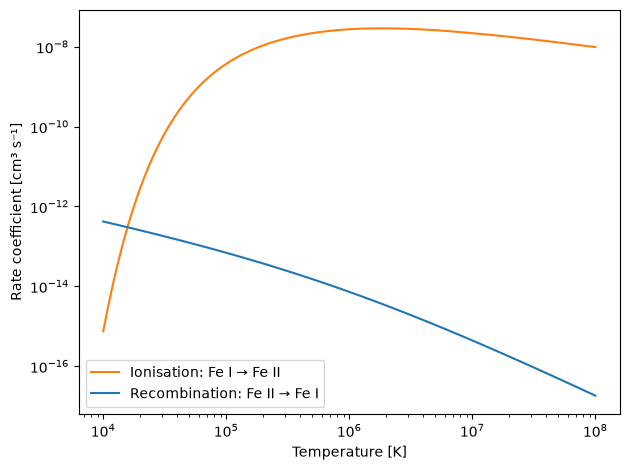

In [ ]:
import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from fiasco import Ion

T = np.logspace(4, 8, 100) * u.K

fe1 = Ion('Fe I', T)
fe2 = Ion('Fe II', T)

# Matching forward and reverse transitions
C_X = fe1.ionization_rate
alpha_X = fe2.recombination_rate

fig, ax = plt.subplots(tight_layout=True)

ax.plot(T, C_X.to_value(u.cm**3 / u.s),
        label='Ionisation: Fe I → Fe II', color='C1')

ax.plot(T, alpha_X.to_value(u.cm**3 / u.s),
        label='Recombination: Fe II → Fe I', color='C0')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel('Rate coefficient [cm³ s⁻¹]')
ax.legend()
plt.show()

In [20]:
from functools import lru_cache
from pathlib import Path

_COLUMNS = ("Z", "N", "E_th", "E_max", "E0", "sigma0", "ya", "P", "yw", "y0", "y1")

_SYMBOLS = {
    1: "H", 2: "He", 3: "Li", 4: "Be", 5: "B", 6: "C", 7: "N", 8: "O",
    9: "F", 10: "Ne", 11: "Na", 12: "Mg", 13: "Al", 14: "Si", 16: "S",
    18: "Ar", 20: "Ca", 26: "Fe",
}
_Z_OF = {symbol.lower(): z for z, symbol in _SYMBOLS.items()}

_ROMAN = {
    "I": 1, "II": 2, "III": 3, "IV": 4, "V": 5, "VI": 6, "VII": 7,
    "VIII": 8, "IX": 9, "X": 10, "XI": 11, "XII": 12, "XIII": 13,
    "XIV": 14, "XV": 15, "XVI": 16, "XVII": 17, "XVIII": 18, "XIX": 19,
    "XX": 20, "XXI": 21, "XXII": 22, "XXIII": 23, "XXIV": 24, "XXV": 25,
    "XXVI": 26,
}


@lru_cache(maxsize=None)
def _load_photo_dat(path):
    rows = []
    for line in Path(path).read_text().splitlines():
        parts = line.split()
        if len(parts) != 11:
            continue
        row = dict(zip(_COLUMNS, (float(value) for value in parts)))
        row["Z"] = int(row["Z"])
        row["N"] = int(row["N"])
        rows.append(row)
    return rows


def _atomic_number(element):
    if isinstance(element, (int, np.integer)):
        z = int(element)
    else:
        text = str(element).strip()
        if text.isdigit():
            z = int(text)
        else:
            z = _Z_OF.get(text.lower())
    if z not in _SYMBOLS:
        known = ", ".join(_SYMBOLS[z] for z in sorted(_SYMBOLS))
        raise ValueError(f"{element!r} is not in photo.dat. Available: {known}")
    return z


def verner_parameters(element, ion=None, electrons=None, path="/Users/ato/Downloads/photo.dat"):
    """Verner et al. (1996) fit parameters for one element.

    element: symbol or atomic number, e.g. "Fe" or 26.
    ion: spectroscopic stage, 1 for the neutral (Fe I). Optional.
    electrons: electron count N. Neutral is N = Z. Optional.

    Returns one dict, or a list of dicts (neutral first) if neither
    ion nor electrons is given. Keys are Z, N, E_th, E_max, E0,
    sigma0, ya, P, yw, y0, y1. Energies are eV and sigma0 is Mb.
    """
    if ion is not None and electrons is not None:
        raise ValueError("Pass ion or electrons, not both.")

    z = _atomic_number(element)
    rows = [row for row in _load_photo_dat(str(Path(path))) if row["Z"] == z]
    if electrons is None and ion is not None:
        electrons = z - int(ion) + 1
    if electrons is None:
        return rows

    electrons = int(electrons)
    for row in rows:
        if row["N"] == electrons:
            return row
    raise ValueError(
        f"No photo.dat row for {_SYMBOLS[z]} with N={electrons} electrons "
        f"(ion stage {z - electrons + 1})."
    )


def parse_ion_name(name):
    """Split 'Fe I' or 'Fe 1' into (element, spectroscopic stage)."""
    parts = str(name).replace("_", " ").split()
    if len(parts) != 2:
        raise ValueError(f"Expected 'Fe I' or 'Fe 1', got {name!r}.")
    element, stage = parts
    ion = _ROMAN.get(stage.upper(), int(stage) if stage.isdigit() else None)
    if ion is None:
        raise ValueError(f"Unrecognised ion stage {stage!r}.")
    return element, ion

In [21]:
import numpy as np
import astropy.units as u



def photoionisation_cross_section(energy, element, ion=1, path="/Users/ato/Downloads/photo.dat"):
    """Photoionisation cross-section from the Verner et al. (1996) fit.
    element is a symbol or atomic number. ion is the spectroscopic stage
    (1 is neutral, so Fe I is element="Fe", ion=1). Energies are eV and
    the returned cross-section is in cm^2. The fit is the total only up
    to E_max.
    """
    p = verner_parameters(element, ion=ion, path=path)
    E = np.asarray(energy.to_value(u.eV))
    if np.any(~np.isfinite(E)) or np.any(E <= 0):
        raise ValueError("Photon energies must be finite and positive.")
    if np.any(E >= p["E_max"]):
        raise ValueError(
            f"At E >= {p['E_max']:g} eV this fit is no longer the total "
            "cross-section; additional inner-shell terms are required."
        )
    E_eval = np.maximum(E, p["E_th"])
    x = E_eval / p["E0"] - p["y0"]
    y = np.sqrt(x**2 + p["y1"]**2)
    sigma = (
        1e-18 * p["sigma0"]
        * ((x - 1) ** 2 + p["yw"] ** 2)
        * y ** (0.5 * p["P"] - 5.5)
        * (1 + np.sqrt(y / p["ya"])) ** (-p["P"])
    )
    return np.where(E >= p["E_th"], sigma, 0.0) * u.cm**2


In [39]:
from physics.cross_section import photoionisation_cross_section

In [41]:
sigma

<Quantity [8.33031643e-20, 9.10668015e-20, 9.92839742e-20, 1.07965779e-19,
           1.17123173e-19, 1.26766981e-19, 1.36907891e-19, 1.47556462e-19,
           1.58723123e-19, 1.70418176e-19, 1.82651799e-19, 1.95434048e-19,
           2.08774855e-19, 2.22684038e-19, 2.37171294e-19, 2.52246208e-19,
           2.67918250e-19, 2.84196782e-19, 3.01091052e-19, 3.18610204e-19,
           3.36763274e-19, 3.55559196e-19, 3.75006799e-19, 3.95114813e-19,
           4.15891866e-19, 4.37346491e-19, 4.59487123e-19, 4.82322102e-19,
           5.05859675e-19, 5.30107996e-19, 5.55075130e-19, 5.80769051e-19,
           6.07197645e-19, 6.34368713e-19, 6.62289967e-19, 6.90969038e-19,
           7.20413473e-19, 7.50630736e-19, 7.81628212e-19, 8.13413204e-19,
           8.45992939e-19, 8.79374564e-19, 9.13565153e-19, 9.48571701e-19,
           9.84401131e-19, 1.02106029e-18, 1.05855596e-18, 1.09689484e-18,
           1.13608357e-18, 1.17612871e-18, 1.21703676e-18, 1.25881415e-18,
           1.30146724e-18

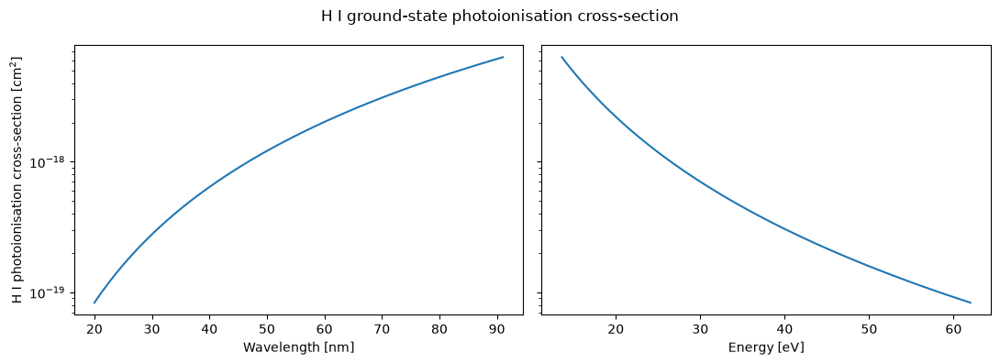

In [44]:
import matplotlib.pyplot as plt

wavelength = np.linspace(20, 200, 300) * u.nm
energy = wavelength.to(u.eV, equivalencies=u.spectral())
sigma = photoionisation_cross_section(energy, "H", ion=1)
sigma_plot = np.ma.masked_less_equal(sigma.value, 0)

fig, (ax_wave, ax_energy) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

ax_wave.plot(wavelength.value, sigma_plot)
ax_wave.set_xlabel("Wavelength [nm]")

ax_energy.plot(energy.value, sigma_plot)
ax_energy.set_xlabel("Energy [eV]")

ax_wave.set_ylabel(r"H I photoionisation cross-section [cm$^2$]")
for ax in (ax_wave, ax_energy):
    ax.set_yscale("log")
    # ax.grid(True, which="both", ls=":")

fig.suptitle("H I ground-state photoionisation cross-section")

fig.tight_layout()
plt.show()

Loaded 24000 wavelength bins.
Selected spectrum: quiet
Filled bins: 30
Integrated irradiance over the supplied bins: 1309.84 W / m2


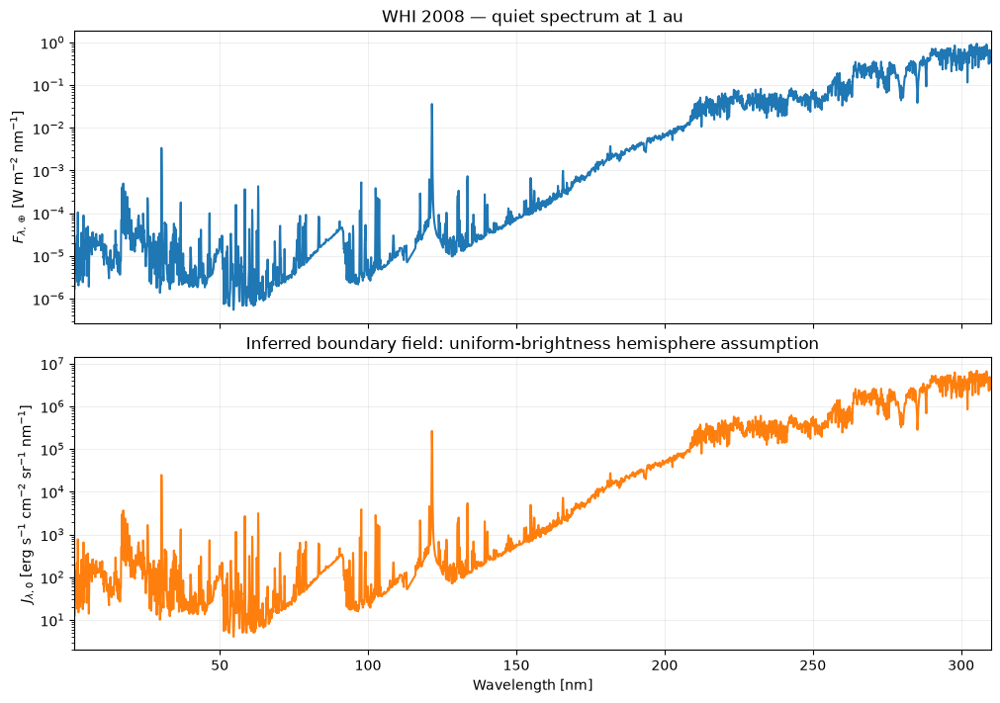

In [56]:
from pathlib import Path
from io import StringIO
from urllib.request import urlopen

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.constants import au, R_sun, h, c


# ------------------------------------------------------------
# 1. Download the WHI spectrum once; reuse the local file
# ------------------------------------------------------------

URL = (
    "https://lasp.colorado.edu/lisird/resources/"
    "whi_ref_spectra/data/ref_solar_irradiance_whi-2008_ver2.dat"
)

DATA_FILE = Path("ref_solar_irradiance_whi-2008_ver2.dat")

if not DATA_FILE.exists():
    with urlopen(URL, timeout=60) as response:
        text = response.read().decode("utf-8")

    # Check the response before saving it.
    if "5 columns" not in text:
        raise ValueError("Downloaded content is not the expected WHI file.")

    DATA_FILE.write_text(text, encoding="utf-8")

text = DATA_FILE.read_text(encoding="utf-8")


# ------------------------------------------------------------
# 2. Read the numerical data
# ------------------------------------------------------------

lines = text.splitlines()

start = next(
    (
        i + 1
        for i, line in enumerate(lines)
        if line.strip().startswith("5 columns")
    ),
    None,
)

if start is None:
    raise ValueError("Cannot locate the WHI numerical-data header.")

data = np.loadtxt(StringIO("\n".join(lines[start:])))

if data.shape != (24000, 5):
    raise ValueError(f"Unexpected data shape: {data.shape}")

if not np.all(np.isfinite(data)):
    raise ValueError("The file contains non-finite values.")

if np.any(np.diff(data[:, 0]) <= 0):
    raise ValueError("Wavelengths must be strictly increasing.")

if np.any(data[:, 1:4] < 0):
    raise ValueError("The file contains negative irradiances.")


# ------------------------------------------------------------
# 3. Assign columns and physical units
# ------------------------------------------------------------

wavelength = data[:, 0] * u.nm

F_unit = u.W / (u.m**2 * u.nm)

spectra = {
    "sunspot": data[:, 1] * F_unit,  # March 25–29
    "faculae": data[:, 2] * F_unit,  # March 30–April 4
    "quiet":   data[:, 3] * F_unit,  # April 10–16
}

source_flag = data[:, 4].astype(int)

# Select the spectrum used below.
spectrum_name = "quiet"
F_lambda_earth = spectra[spectrum_name]

# Preserve filled bins; -1 means estimated rather than measured.
filled_bins = source_flag == -1

print(f"Loaded {len(wavelength)} wavelength bins.")
print(f"Selected spectrum: {spectrum_name}")
print(f"Filled bins: {filled_bins.sum()}")


# ------------------------------------------------------------
# 4. Check the wavelength-integrated irradiance
# ------------------------------------------------------------

# This file contains spectral irradiance averaged into 0.1-nm bins.
# A bin-width sum preserves their integrated energy.
bin_width = 0.1 * u.nm

integrated_irradiance = (
    np.sum(F_lambda_earth) * bin_width
).to(u.W / u.m**2)

print(
    "Integrated irradiance over the supplied bins: "
    f"{integrated_irradiance:.2f}"
)
# The quiet-Sun value should be approximately 1309.84 W/m².
# This excludes radiation beyond the file's wavelength coverage.


# ------------------------------------------------------------
# 5. Construct an effective unattenuated boundary mean intensity
# ------------------------------------------------------------

# ASSUMPTION:
# Uniform surface brightness, with radiation filling one hemisphere
# immediately above the solar surface.
#
# F_lambda_surface = F_lambda_earth * (au / R_sun)^2
# I_lambda_surface = F_lambda_surface / pi
# J_lambda_0 = I_lambda_surface / 2
#
# This is a prescribed boundary-field approximation.
# Applying it to downward coronal radiation requires an additional
# geometrical/normalisation assumption.

geometric_scale = (au / R_sun).decompose().value**2

J_lambda_unit = u.erg / (
    u.s * u.cm**2 * u.sr * u.nm
)

J_lambda_0 = (
    F_lambda_earth * geometric_scale / (2 * np.pi * u.sr)
).to(J_lambda_unit)


# ------------------------------------------------------------
# 6. Convert J_lambda to J_nu, if needed
# ------------------------------------------------------------

frequency = (c / wavelength).to(u.Hz)

J_nu_unit = u.erg / (
    u.s * u.cm**2 * u.sr * u.Hz
)

# Astropy handles the wavelength/frequency Jacobian and unit conversion.
J_nu_0 = J_lambda_0.to(
    J_nu_unit,
    equivalencies=u.spectral_density(wavelength),
)

# Increasing wavelength corresponds to decreasing frequency.
# Sort before integrating in frequency.
frequency_order = np.argsort(frequency.value)

frequency_sorted = frequency[frequency_order]
J_nu_0_sorted = J_nu_0[frequency_order]


# ------------------------------------------------------------
# 7. Photon-number intensity
# ------------------------------------------------------------

photon_energy = (h * c / wavelength).to(u.erg)

# Multiply this by a cross-section [cm²] and integrate over
# wavelength [nm] to obtain a photoionisation rate [s^-1].
photon_factor = (
    4 * np.pi * u.sr * J_lambda_0 / photon_energy
).to(1 / (u.s * u.cm**2 * u.nm))


# ------------------------------------------------------------
# 8. Plot the UV spectrum and inferred boundary mean intensity
# ------------------------------------------------------------

uv = (
    (wavelength >= 1 * u.nm)
    & (wavelength <= 310 * u.nm)
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 7),
    sharex=True,
    constrained_layout=True,
)

axes[0].plot(
    wavelength[uv].to_value(u.nm),
    F_lambda_earth[uv].to_value(F_unit),
    color="C0",
)

axes[0].set_yscale("log")
axes[0].set_ylabel(
    r"$F_{\lambda,\oplus}$ [W m$^{-2}$ nm$^{-1}$]"
)
axes[0].set_title(
    f"WHI 2008 — {spectrum_name} spectrum at 1 au"
)

axes[1].plot(
    wavelength[uv].to_value(u.nm),
    J_lambda_0[uv].to_value(J_lambda_unit),
    color="C1",
)

axes[1].set_yscale("log")
axes[1].set_xlabel("Wavelength [nm]")
axes[1].set_ylabel(
    r"$J_{\lambda,0}$ [erg s$^{-1}$ cm$^{-2}$ sr$^{-1}$ nm$^{-1}$]"
)
axes[1].set_title(
    "Inferred boundary field: uniform-brightness hemisphere assumption"
)

for ax in axes:
    ax.grid(alpha=0.2)
    ax.set_xlim(1, 310)

plt.show()

In [ ]:
% git clone https://github.com/rice-solar-physics/pydrad.git
% cd pydrad
$ pip install .
%pip install pydrad 

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.1/24.1 MB 7.8 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pydrad]
Note: you may need to restart the kernel to use updated packages.


In [1]:
from hydrogen import reconstruct_hydrogen
import astropy.units as u
from main_fip_bias_batch import process_hydrad_data
import matplotlib.pyplot as plt
import numpy as np

In [5]:
import os
import pickle
import astropy.units as u
from main_fip_bias_batch import process_hydrad_data

input_file = "/Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings"
strand_num = 700
frequency = 0.206 * u.s**-1
amplitude = 0.97 * u.km / u.s
acoustic_flux = 5e7 * u.erg / u.cm**2 / u.s
v_add = 0.0 * u.km / u.s

output_dir = os.path.join(input_file, "fip_bias_output")
os.makedirs(output_dir, exist_ok=True)
cache_file = os.path.join(
    output_dir,
    f"output_f{frequency.value:.3f}_A{amplitude.value:.2f}_s{strand_num}"
    f"_F{acoustic_flux.value:.1e}_vadd{v_add.value:.1f}.pkl",
)

rerun = False

if os.path.exists(cache_file) and not rerun:
    with open(cache_file, "rb") as f:
        output_data = pickle.load(f)
    print(f"Loaded {cache_file}")
else:
    output_data = process_hydrad_data(
        input_file=input_file,
        frequency=frequency,
        amplitude=amplitude,
        output_dir=output_dir + "/",
        strand_num=strand_num,
        acoustic_flux=acoustic_flux,
        v_add=v_add,
    )
    with open(cache_file, "wb") as f:
        pickle.dump(output_data, f)
    print(f"Saved {cache_file}")

Loading from pydrad profile
Solving ODE 
Function evaluations: 10665
Number of steps: 4382
ODE solved
Element: Ca, Atomic Number: 20, Mass Number: 40.078
Element: Mg, Atomic Number: 12, Mass Number: 24.304
Element: Fe, Atomic Number: 26, Mass Number: 55.845
Element: Si, Atomic Number: 14, Mass Number: 28.084
Element: S, Atomic Number: 16, Mass Number: 32.059
Element: C, Atomic Number: 6, Mass Number: 12.0096
Element: N, Atomic Number: 7, Mass Number: 14.0064
Element: O, Atomic Number: 8, Mass Number: 15.999
Element: Ne, Atomic Number: 10, Mass Number: 20.1797
Element: Ar, Atomic Number: 18, Mass Number: 39.948
Saved FIP bias vs height plot for 0.206_0.97_700: /Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/fip_bias_output/v_0.2060_A_0.97_F_5.0e07/images/fip_bias_vs_height_multi_0.206_0.97_700.png
Saved /Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_t

In [8]:
# root = "/Volumes/Crucial X9/collaborations/Biswajit/2026_Solphys/Hydrad_outputs2/Emax0.5"
root = "/Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings"
history = reconstruct_hydrogen(
    root,
    mode="equilibrium",
    cache="results/hydrogen_validation/my_history.npz",
)


In [2]:
def quantity_values(values, unit=None):
    """Return a NumPy array, converting Astropy quantities when present."""
    if hasattr(values, "to") and unit is not None:
        return np.asarray(values.to(unit).value)
    if hasattr(values, "value"):
        return np.asarray(values.value)
    return np.asarray(values)


def loop_distance_mm(data):
    return quantity_values(data["s_values"], u.Mm)


def plot_loop_atmosphere(data):
    s_mm = loop_distance_mm(data)
    temperature = quantity_values(data["T"], u.K)
    density = quantity_values(data["ne"], u.cm**-3)

    fig, ax_density = plt.subplots(figsize=(8, 4.8))
    ax_temperature = ax_density.twinx()

    ax_density.semilogy(s_mm, density, color="tab:blue", label="Electron density")
    ax_temperature.semilogy(s_mm, temperature, color="tab:red", label="Temperature")

    ax_density.set_xlabel("Distance along loop (Mm)")
    ax_density.set_ylabel("Electron density (cm$^{-3}$)", color="tab:blue")
    ax_temperature.set_ylabel("Temperature (K)", color="tab:red")
    ax_density.tick_params(axis="y", labelcolor="tab:blue")
    ax_temperature.tick_params(axis="y", labelcolor="tab:red")
    ax_density.set_title("HYDRAD atmosphere used by FIPpy")

    lines, labels = ax_density.get_legend_handles_labels()
    lines2, labels2 = ax_temperature.get_legend_handles_labels()
    ax_density.legend(lines + lines2, labels + labels2, loc="best")
    fig.tight_layout()
    return fig


def plot_ponderomotive_acceleration(data):
    s_mm = loop_distance_mm(data)
    acceleration = quantity_values(data["ponderomotive_acceleration"], u.cm / u.s**2)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(s_mm, acceleration, color="black")
    ax.axhline(0.0, color="0.5", linewidth=0.8)
    ax.set_xlabel("Distance along loop (Mm)")
    ax.set_ylabel("Ponderomotive acceleration (cm s$^{-2}$)")
    ax.set_title("Ponderomotive acceleration along the loop")
    fig.tight_layout()
    return fig


def plot_ionisation_fractions(data, elements=("Ca", "Fe", "Mg", "Si", "O", "Ne", "Ar")):
    s_mm = loop_distance_mm(data)
    fractions = data["ionization_fractions"]

    fig, ax = plt.subplots(figsize=(8, 4.8))
    for element in elements:
        if element in fractions:
            ax.semilogy(s_mm, np.clip(fractions[element], 1e-6, 1.0), label=element)

    ax.set_xlabel("Distance along loop (Mm)")
    ax.set_ylabel("Ionisation fraction")
    ax.set_ylim(1e-4, 1.1)
    ax.set_title("Ionisation fractions used in the fractionation calculation")
    ax.legend(ncol=2)
    fig.tight_layout()
    return fig


def bias_arrays(data, element, side):
    segment = data["fip_bias_heights"].get(element, {}).get(side)
    if segment is None:
        return None, None
    heights = quantity_values(segment["heights"])
    bias = quantity_values(segment["bias"])
    return heights, bias


def plot_fip_bias_relative_to_oxygen(data, side="right", elements=("Ca", "Fe", "Mg", "Si", "S", "Ar", "Ne")):
    oxygen_height, oxygen_bias = bias_arrays(data, "O", side)
    if oxygen_height is None:
        raise KeyError(f"No oxygen FIP-bias data found for side={side!r}")

    fig, ax = plt.subplots(figsize=(8, 4.8))
    for element in elements:
        heights, bias = bias_arrays(data, element, side)
        if heights is None:
            continue
        oxygen_at_height = np.interp(heights, oxygen_height, oxygen_bias)
        ax.plot(heights, bias / oxygen_at_height, label=f"{element}/O")

    ax.axhline(1.0, color="0.5", linewidth=0.8)
    ax.set_xlabel("Height (Mm)")
    ax.set_ylabel("FIP bias normalized to O")
    ax.set_title(f"FIP bias at the {side} footpoint")
    ax.legend(ncol=2)
    fig.tight_layout()
    return fig

In [6]:
import numpy as np
import astropy.units as u
from loop.reader import HydradReader
from loop.properties import LoopProperties
from wave.solver import WaveAnalyzer

root = "/Volumes/Crucial X9/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings"
strand = HydradReader(root, strand_num=700).read_strand()
props = LoopProperties(strand)
va = WaveAnalyzer(props).VA(props.s_array).to(u.cm / u.s).value

s = props.s_array.to(u.cm).value
T = props.T(props.s_array).to(u.K).value
va = WaveAnalyzer(props).VA(props.s_array).to(u.cm / u.s).value
dlnT = np.abs(np.gradient(np.log(T), s))
mid = len(s) // 2
i_left = np.argmax(dlnT[:mid])
i_right = mid + np.argmax(dlnT[mid:])
travel_time = np.trapezoid(1 / va[i_left:i_right + 1], s[i_left:i_right + 1])
frequency = (1 / (2 * travel_time)) * u.s**-1
print(frequency)


Loading from pydrad profile
0.0410009289780905 1 / s


In [9]:
output_data.keys()

dict_keys(['s_values', 'I_plus', 'I_minus', 'delta_B_over_sqrt_4pi_rho', 'delta_v', 'flux_right', 'flux_left', 'normalized_flux_difference', 'ponderomotive_acceleration', 'acceleration_cm_s2', 'VA_s', 'ne', 'nh', 'h_ionisation', 'hydrogen_metadata', 'T', 'thermal_speed_squared', 'B', 'rho', 'collision_components_dict', 'slow_mode_velocity', 'sound_speed', 'acoustic_flux', 'v_add', 'fip_bias_heights', 'ionization_fractions', 'collision_frequencies', 'integral_terms', 'frequency', 'amplitude', 'loop_length'])

In [31]:
output_data['nh']

<Quantity [3.36901470e+16, 3.36901469e+16, 3.36901469e+16, ...,
           3.20052427e+16, 3.22245551e+16, 3.24060766e+16] 1 / cm3>

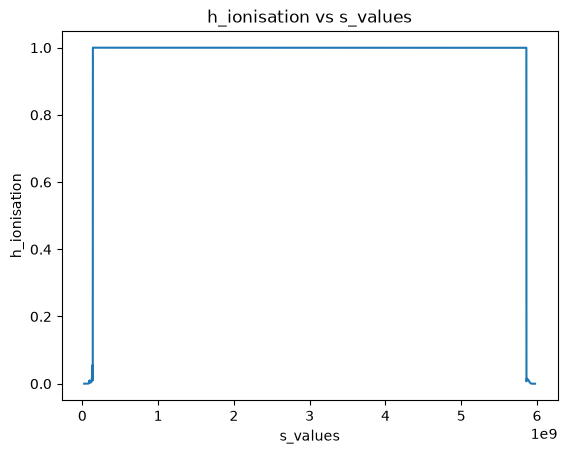

In [28]:
plt.plot(output_data['s_values'], output_data['h_ionisation'])
plt.xlabel('s_values')
plt.ylabel('h_ionisation')
plt.title('h_ionisation vs s_values')
plt.show()

In [25]:
output_data['s_values']

<Quantity [2.42187500e+07, 2.42187500e+07, 2.42187500e+07, ...,
           5.97408004e+09, 5.97415668e+09, 5.97421875e+09] cm>

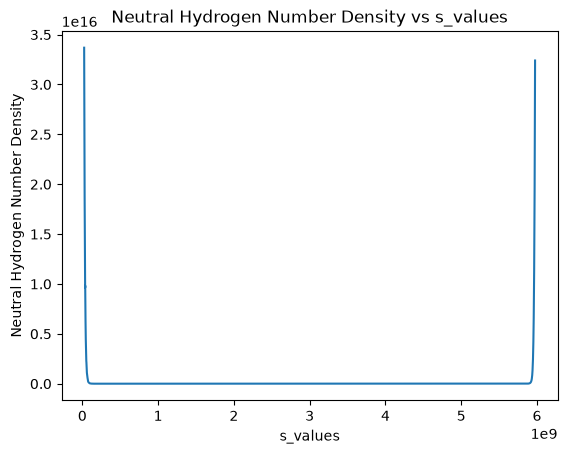

In [32]:
# number density of neutral hydrogen
n_H0 = output_data['nh'] * (1 - output_data['h_ionisation'])
plt.plot(output_data['s_values'], n_H0)
plt.xlabel('s_values')
plt.ylabel('Neutral Hydrogen Number Density')
plt.title('Neutral Hydrogen Number Density vs s_values')
plt.show()


In [36]:
import astropy.units as u
import numpy as np
from scipy.integrate import cumulative_trapezoid

s_cm = output_data["s_values"].to_value(u.cm)
n_cm = n_H0.to_value(u.cm**-3)

N_from_start = cumulative_trapezoid(n_cm, x=s_cm, initial=0)
N_from_end = cumulative_trapezoid(n_cm[::-1], x=-s_cm[::-1], initial=0)[::-1]

s_apex = 0.5 * (s_cm[0] + s_cm[-1])
N_H0 = np.where(s_cm <= s_apex, N_from_start, N_from_end) * u.cm**-2

In [ ]:
import numpy as np
import astropy.units as u
from scipy.integrate import cumulative_trapezoid


def hydrogen_optical_depth(s, n_H, f_Hplus, sigma_H):
    """
    s:        increasing path coordinate, shape (n_positions,)
    n_H:      total hydrogen-nucleus density, same shape
    f_Hplus:  hydrogen ionised fraction, same shape
    sigma_H:  H I cross-section on energy grid, shape (n_energies,)

    Returns:
        N_bot, N_top: column densities [cm^-2]
        tau_bot, tau_top: arrays shaped (n_positions, n_energies)
    """
    s_cm = s.to_value(u.cm)
    nH = n_H.to_value(u.cm**-3)
    f = np.asarray(f_Hplus, dtype=float)
    sigma = sigma_H.to_value(u.cm**2)

    n_H0 = nH * (1 - f)

    # Bottom -> position
    N_bot = cumulative_trapezoid(n_H0, s_cm, initial=0)

    # Position -> top; reverse integration avoids subtracting large columns.
    N_top = -cumulative_trapezoid(
        n_H0[::-1], s_cm[::-1], initial=0
    )[::-1]

    # Outer products: position × photon energy
    tau_bot = N_bot[:, None] * sigma[None, :]
    tau_top = N_top[:, None] * sigma[None, :]

    return (
        N_bot * u.cm**-2,
        N_top * u.cm**-2,
        tau_bot,
        tau_top,
    )


In [57]:
wavelengths = wavelength[uv]
# wavelength = np.linspace(10, 200, 300) * u.nm
energy = wavelengths.to(u.eV, equivalencies=u.spectral())
sigma_H0 = photoionisation_cross_section(energy, "H", ion=1)

In [ ]:
tau = (
    N_H0[:, None] * sigma_H0[None, :]
).to_value(u.dimensionless_unscaled)

transmission = np.exp(-tau)

print(tau.shape)

(4406, 3090)


In [80]:
# read the solar spectrum
from physics.radiation import (
    load_whi_spectrum,
    surface_hemisphere_mean_intensity,
    two_sided_mean_intensity,
)

wavelength, irradiance, source_flags = load_whi_spectrum(
    spectrum="quiet"
)

J_lambda_0 = surface_hemisphere_mean_intensity(irradiance)

In [71]:
wavelength, irradiance, source_flags = load_whi_spectrum(spectrum="quiet")
J_reference = surface_hemisphere_mean_intensity(irradiance)

energy = wavelength.to(u.eV, equivalencies=u.spectral())
sigma_H0 = photoionisation_cross_section(energy, "H", ion=1)

In [ ]:
# filter energy of the photon
from_above = wavelength < (7.9 * u.eV).to(u.nm, equivalencies=u.spectral())

J_top_0 = J_reference * from_above
J_bottom_0 = J_reference * (~from_above)

In [81]:
J_lambda = two_sided_mean_intensity(
    J_bottom=J_bottom_0,  # incident spectrum from below
    J_top=J_top_0,        # incident spectrum from above
    N_bottom=N_bottom,   # neutral-H column from below [cm^-2]
    N_top=N_top,         # neutral-H column from above [cm^-2]
    sigma=sigma_H0,      # H I cross-section [cm^2]
)

NameError: name 'N_bottom' is not defined

In [63]:
J_lambda = two_sided_mean_intensity(
    J_bottom=J_bottom_0,  # incident spectrum from below
    J_top=J_top_0,        # incident spectrum from above
    N_bottom=N_bottom,   # neutral-H column from below [cm^-2]
    N_top=N_top,         # neutral-H column from above [cm^-2]
    sigma=sigma_H0,      # H I cross-section [cm^2]
)

NameError: name 'two_sided_mean_intensity' is not defined

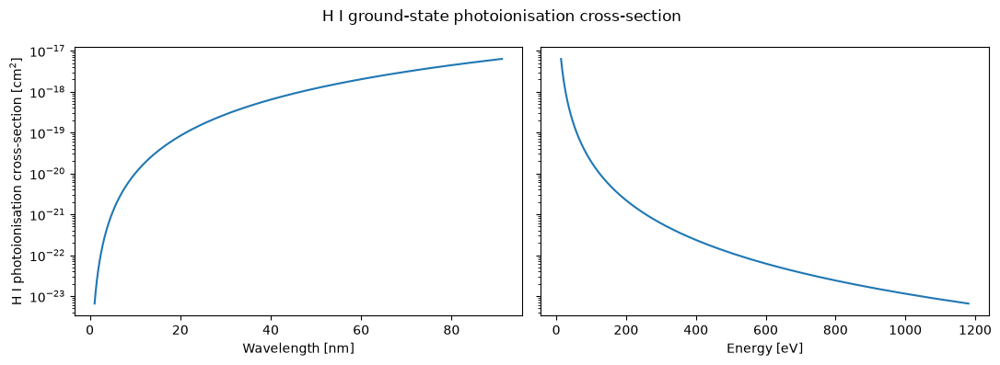

In [58]:
import matplotlib.pyplot as plt

# Use wavelengths, energy, sigma_H0 already defined earlier
sigma_plot = np.ma.masked_less_equal(sigma_H0.value, 0)

fig, (ax_wave, ax_energy) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

ax_wave.plot(wavelengths.value, sigma_plot)
ax_wave.set_xlabel("Wavelength [nm]")

ax_energy.plot(energy.value, sigma_plot)
ax_energy.set_xlabel("Energy [eV]")

ax_wave.set_ylabel(r"H I photoionisation cross-section [cm$^2$]")
for ax in (ax_wave, ax_energy):
    ax.set_yscale("log")
    # ax.grid(True, which="both", ls=":")

fig.suptitle("H I ground-state photoionisation cross-section")

fig.tight_layout()
plt.show()

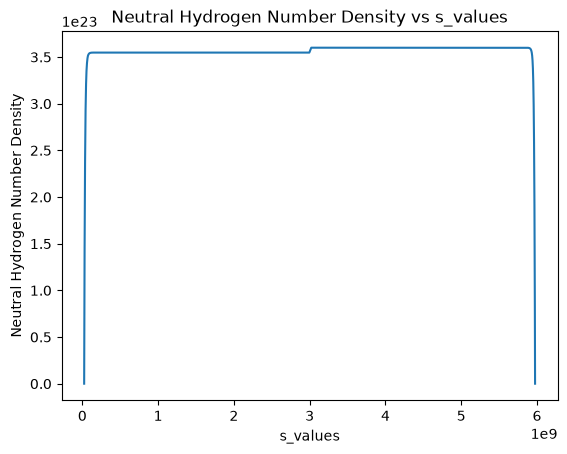

In [37]:
# number density of neutral hydrogen
n_H0 = output_data['nh'] * (1 - output_data['h_ionisation'])
plt.plot(output_data['s_values'], N_H0)
plt.xlabel('s_values')
plt.ylabel('Neutral Hydrogen Number Density')
plt.title('Neutral Hydrogen Number Density vs s_values')
plt.show()


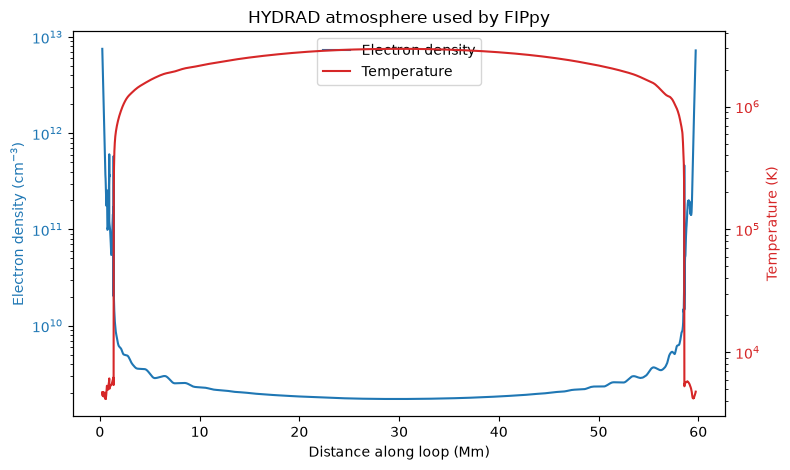

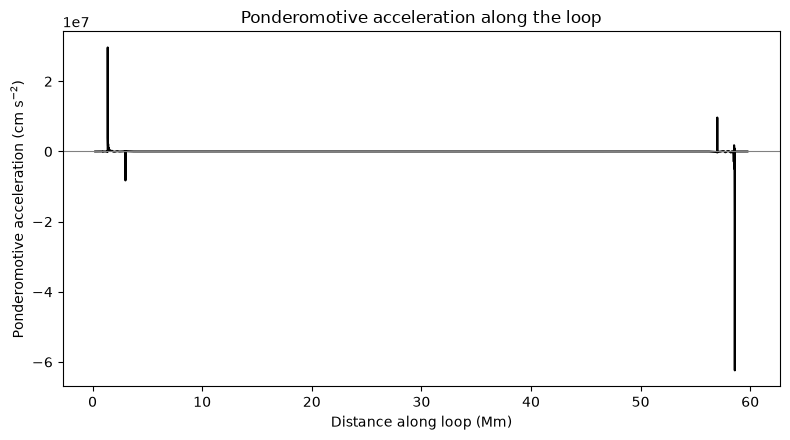

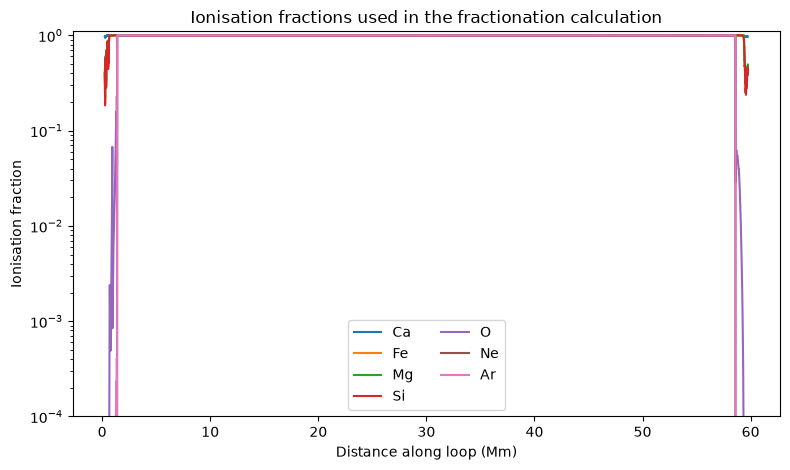

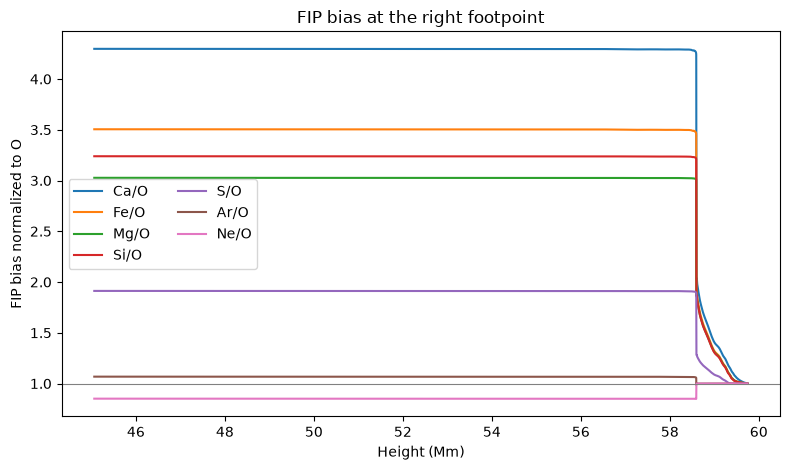

In [7]:
plot_loop_atmosphere(output_data)
plot_ponderomotive_acceleration(output_data)
plot_ionisation_fractions(output_data)
plot_fip_bias_relative_to_oxygen(output_data, side="right")
plt.show()

MissingDatasetException: _drparams dataset missing for Fe 1.

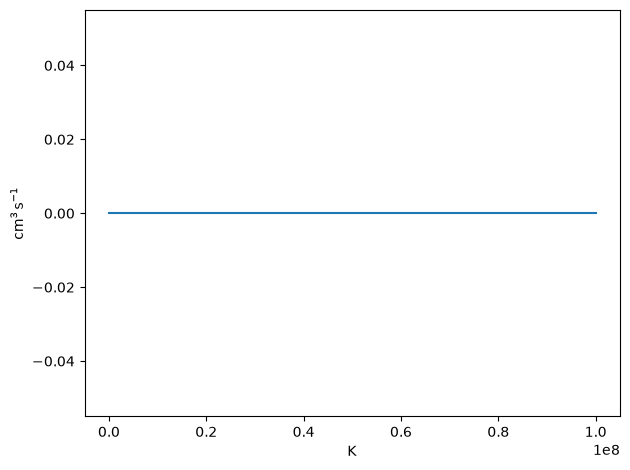

In [35]:
from fiasco.util.exceptions import MissingDatasetException

fig, ax = plt.subplots(tight_layout=True)
ax.plot(ion.temperature, ion.recombination_rate,
        label='Recombination', color='C0')
ax.plot(ion.temperature, ion.dielectronic_recombination_rate,
        label='Dielectronic', color='C0', ls='--')
ax.plot(ion.temperature, ion.radiative_recombination_rate,
        label='Radiative', color='C0', ls=':')
ax.plot(ion.temperature, ion.ionization_rate,
        label='Ionization', color='C1')
ax.plot(ion.temperature, ion.direct_ionization_rate,
        label='Direct', color='C1', ls='--')
try:
    ax.plot(ion.temperature, ion.excitation_autoionization_rate,
            label='Excitation Autoionization', color='C1', ls=':')
except MissingDatasetException:
    print(f'No excitation-autoionization data for {ion.ion_name}')
ax.set_xscale('log')
ax.set_yscale('log')
# ax.set_ylim(1e-12, 1e-6)
ax.legend()
plt.show()

In [2]:
# Get the temperature array
temperatures = ca.Temperature

# Get the ion fraction array
ion_fractions = ca.Ioneq

# For just the first ionization stage (neutral state)
first_stage_fraction = ca.Ioneq[0]

# Create a dictionary or array of corresponding values
data = {
    'temperature': temperatures,
    'ion_fraction': first_stage_fraction
}

# Or if you want it as a numpy array:
data_array = np.column_stack((temperatures, first_stage_fraction))

In [184]:
from plasmapy.formulary.ionization import Saha
import numpy as np
import astropy.units as u

atomic_data = {
    # 'H': {'ionization_energy': 13.6, 'g_i': 2, 'g_j': 1},
    # 'He': {'ionization_energy': 24.6, 'g_i': 1, 'g_j': 2},
    'Ca': {'ionization_energy': 6.1132*u.eV, 'g_i': 1, 'g_j': 2},
    'Mg': {'ionization_energy': 7.6462*u.eV, 'g_i': 1, 'g_j': 2},
    'Fe': {'ionization_energy': 7.9024*u.eV, 'g_i': 25, 'g_j': 30},
    'Si': {'ionization_energy': 8.1517*u.eV, 'g_i': 9, 'g_j': 6},
    'S': {'ionization_energy': 10.3600*u.eV, 'g_i': 9, 'g_j': 4},
    'C': {'ionization_energy': 11.2603*u.eV, 'g_i': 9, 'g_j': 6},
    'O': {'ionization_energy': 13.6181*u.eV, 'g_i': 9, 'g_j': 4}, 
    'N':  {'ionization_energy': 14.5341*u.eV, 'g_i': 4, 'g_j': 9},
    'Ar': {'ionization_energy': 15.7568*u.eV, 'g_i': 1, 'g_j': 6},
    'Ne': {'ionization_energy': 21.5645*u.eV, 'g_i': 1, 'g_j': 6},

}

def get_ionisation_fraction(g_i, g_j, n_e, ionization_energy, T):
    """
    Calculate the ionization fraction using the Saha equation.
    
    Parameters:
    T: Temperature in Kelvin
    n_e: Electron number density in cm^-3
    ionization_energy: Ionization energy in eV
    g_i: Statistical weight of the lower ionization state
    g_j: Statistical weight of the higher ionization state
    
    Returns:
    Ionization fraction n_j / n_i
    """
    fraction = Saha(g_i, g_j, n_e, ionization_energy, T)
    ionisation_fraction = 1 / (1 + 1 / np.array(fraction))
    
    return ionisation_fraction


In [23]:
from loop.reader import HydradReader
import matplotlib.pyplot as plt
import astropy.units as u
from pydrad.parse import Strand
from astropy.visualization import ImageNormalize, LogStretch

hydrad_strand = HydradReader('/Users/andysh.to/Script/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H', strand_num=1500).read_strand()


In [14]:
hydrad_strand.electron_density
hydrad_strand.electron_temperature
hydrad_strand.ion_temperature
hydrad_strand.coordinate


<Quantity [1.22070312e+04, 3.66210938e+04, 6.10351562e+04, 8.54492188e+04,
           1.22070312e+05, 1.70898438e+05, 2.44140625e+05, 3.41796875e+05,
           4.88281250e+05, 6.83593750e+05, 9.76562500e+05, 1.36718750e+06,
           1.95312500e+06, 2.73437500e+06, 3.51562500e+06, 4.29687500e+06,
           5.07812500e+06, 5.85937500e+06, 7.03125000e+06, 8.59375000e+06,
           1.01562500e+07, 1.17187500e+07, 1.32812500e+07, 1.48437500e+07,
           1.64062500e+07, 1.79687500e+07, 1.95312500e+07, 2.10937500e+07,
           2.26562500e+07, 2.42187500e+07, 2.57812500e+07, 2.73437500e+07,
           2.89062500e+07, 3.04687500e+07, 3.20312500e+07, 3.35937500e+07,
           3.51562500e+07, 3.67187500e+07, 3.82812500e+07, 3.98437500e+07,
           4.14062500e+07, 4.29687500e+07, 4.45312500e+07, 4.60937500e+07,
           4.76562500e+07, 4.92187500e+07, 5.07812500e+07, 5.23437500e+07,
           5.39062500e+07, 5.54687500e+07, 5.70312500e+07, 5.85937500e+07,
           6.01562500e+07

In [164]:
a = Strand('/Users/andysh.to/Script/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings')

In [165]:
import copy
from pydrad.visualize import plot_time_mesh
import numpy as np

def plot_time_distance(strand, quantities, delta_s: u.cm, **kwargs):
    """
    Make a time-distance plot for a particular quantity or
    quantities on a uniform grid.

    Parameters
    ----------
    strand : `~pydrad.parse.Strand`
    quantities : `str`, `list`, `tuple`
        Name of quantity or quantities to plot. Optionally, you can also pass
        in a tuple of `(str, array-like)`, where `str` is the label and the
        second entry is the quantity to plot, already interpolated onto a
        common grid.
    delta_s : `~astropy.units.Quantity`
        Spacing of the uniform spatial grid to interpolate the quantity onto
    space_unit : `str` or `astropy.quantity.Unit`, optional
        Unit for the spatial axis

    Optional Parameters
    -------------------
    All other parameters are passed to `~pydrad.visualize.plot_time_mesh`.
    """
    # NOTE: I'm setting this as the default here so that the quadrilaterals
    # (i.e. the cells represented in the mesh) are centered on grid points.
    # This is because the time and spatial grids here represent the centers
    # of the grid points and thus should be centered on their faces.
    shading = kwargs.pop('shading', 'nearest')
    grid = strand.get_uniform_grid(delta_s).to(kwargs.pop('space_unit', 'cm'))
    # Interpolate quantities to constant grid as needed
    quantities = copy.deepcopy(quantities)
    if type(quantities) is not list:
        quantities = [quantities]
    for i, q in enumerate(quantities):
        if type(q) is str:
            quantities[i] = (q, strand.to_constant_grid(q, grid))
    fig, ax = plot_time_mesh(strand, quantities, grid, r'$s$', shading=shading, **kwargs)
    return fig, ax


def plot_time_mesh(strand, quantities, y_grid, y_label, **kwargs):
    """
    Plot a given quantity as a function of some variable and time
    for a given strand.

    Parameters
    ----------
    strand : `~pydrad.parse.Strand`
    quantities : `list`, `tuple`
        List of or single tuple of `(str, array-like)`, where `str`
        is the label and the second entry is the quantity to plot,
        already interpolated onto a common grid.
    y_grid : `~astropy.units.Quantity`
        Grid other than time to interpolate the quantity onto.
    y_label : `str`
        Axis label for the other dimension against which to plot the quantity
        or quantities.
    norm : normalization or `dict`, optional
        Colormap normalization or dictionary of normalizations with keys
        corresponding to the quantity names.
    cmap : `str` or colormap instance or `dict`, optional
        Colormap to use for all quantities except velocity which will always
        use the ``RdBu_r`` diverging colormap. If `dict`, mapping of colormaps
        to different quantity names.
    figsize : `tuple`, optional
        Dimensions of the resulting figure
    time_unit : `str` or `astropy.quantity.Unit`, optional
        Unit for the time axis
    ncols : `int`, optional
        Number of columns for subplot layout (default: 3)

    Optional Parameters
    -------------------
    All other keyword arguments are passed to `matplotlib.pcolormesh`.
    """
    y_mesh, t_mesh = np.meshgrid(y_grid.value, strand.time.value,)
    t_mesh = (t_mesh * strand.time.unit).to(kwargs.pop('time_unit', 's'))
    y_mesh = y_mesh * y_grid.unit
    quantities = copy.deepcopy(quantities)
    if type(quantities) is not list:
        quantities = [quantities]
    
    # Determine subplot layout
    ncols = kwargs.pop('ncols', 3)
    nrows = int(np.ceil(len(quantities) / ncols))
    
    fig, ax = plt.subplots(
        nrows, ncols,
        figsize=kwargs.pop('figsize', (5*ncols, 2.5*nrows)),
        sharex=True,
        sharey=True,
    )
    
    # Flatten ax array for easier indexing
    if len(quantities) == 1:
        ax = [ax]
    else:
        ax = ax.flatten()
    
    # NOTE: remove these here so we can send the rest to pcolormesh
    norm = kwargs.pop('norm', {})
    cmap = kwargs.pop('cmap', {})
    units = kwargs.pop('units', {})
    labels = kwargs.pop('labels', {})
    yscale = kwargs.pop('yscale', 'linear')
    xscale = kwargs.pop('xscale', 'linear')
    cbar_size = kwargs.pop('cbar_size', '5%')
    cbar_pad = kwargs.pop('cbar_pad', '1%')
    
    for i, (label, data) in enumerate(quantities):
        data = data.to(units.get(label, data.unit))
        # Swap x and y: now y_mesh is on x-axis, t_mesh is on y-axis
        im = ax[i].pcolormesh(
            y_mesh.value,
            t_mesh.value,
            data.value,
            cmap=cmap.get(label, 'viridis') if isinstance(cmap, dict) else cmap,
            norm=norm.get(label, None) if isinstance(norm, dict) else norm,
            **kwargs,
        )
        cax = make_axes_locatable(ax[i]).append_axes(
            "right",
            size=cbar_size,
            pad=cbar_pad,
        )
        cbar = fig.colorbar(im, cax=cax)
        cbar_label = labels.get(label, label)
        if data.unit != u.dimensionless_unscaled:
            cbar_label += f' [{data.unit}]'
        cbar.set_label(cbar_label)
        # Swap axis labels: y_label is now on x-axis, time is on y-axis
        ax[i].set_xlabel(f'{y_label} [{y_mesh.unit}]')
        ax[i].set_xscale(xscale)
        
        # Set ylabel for left column
        if i % ncols == 0:
            ax[i].set_ylabel(f'$t$ [{t_mesh.unit}]')
        ax[i].set_yscale(yscale)
    
    # Hide unused subplots
    for i in range(len(quantities), len(ax)):
        ax[i].set_visible(False)
    
    plt.tight_layout()

    return fig, ax


In [166]:
import pickle

# Save the data to a pickle file for faster loading
data_to_save = {
    'time': a.time,
    'electron_temperature': a.to_constant_grid('electron_temperature', a.get_uniform_grid(0.5*u.Mm)),
    'electron_density': a.to_constant_grid('electron_density', a.get_uniform_grid(0.5*u.Mm)),
    'velocity': a.to_constant_grid('velocity', a.get_uniform_grid(0.5*u.Mm)),
    'grid': a.get_uniform_grid(0.5*u.Mm),
}

with open('strand_data.pkl', 'wb') as f:
    pickle.dump(data_to_save, f)

print("Data saved to strand_data.pkl")



Data saved to strand_data.pkl


In [162]:
from loop.reader import HydradReader
import matplotlib.pyplot as plt
import astropy.units as u
from pydrad.parse import Strand
from astropy.visualization import ImageNormalize, LogStretch
import numpy as np
import pickle

# a = Strand('/Users/andysh.to/Script/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H')
a = Strand('/Users/andysh.to/Script/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings')

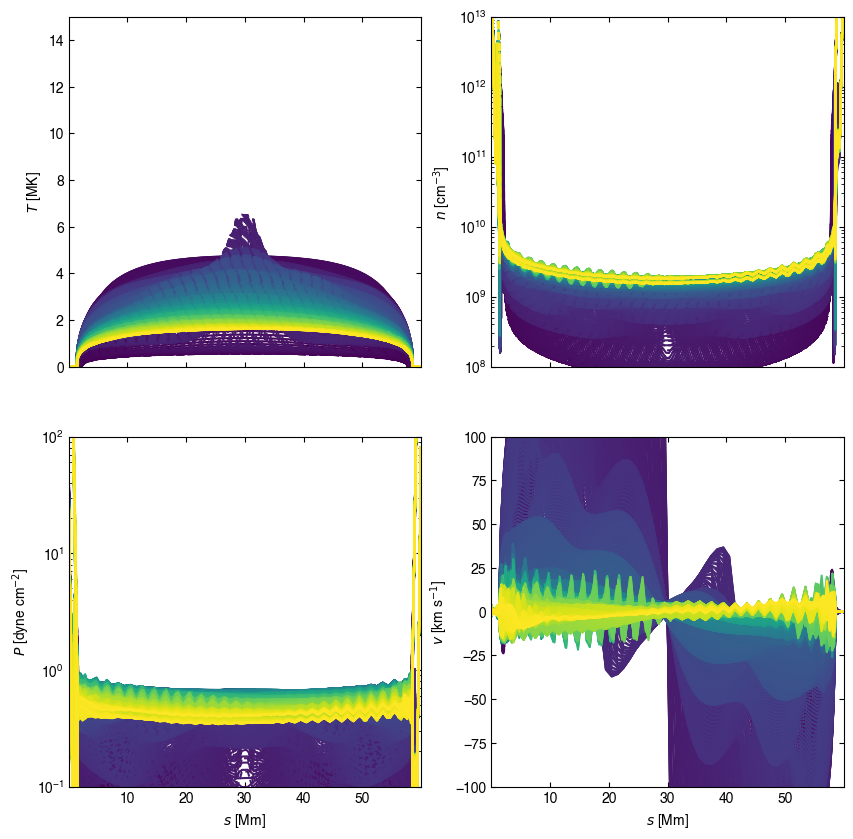

In [163]:

a.peek()




/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_34022/235484553.py:98: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


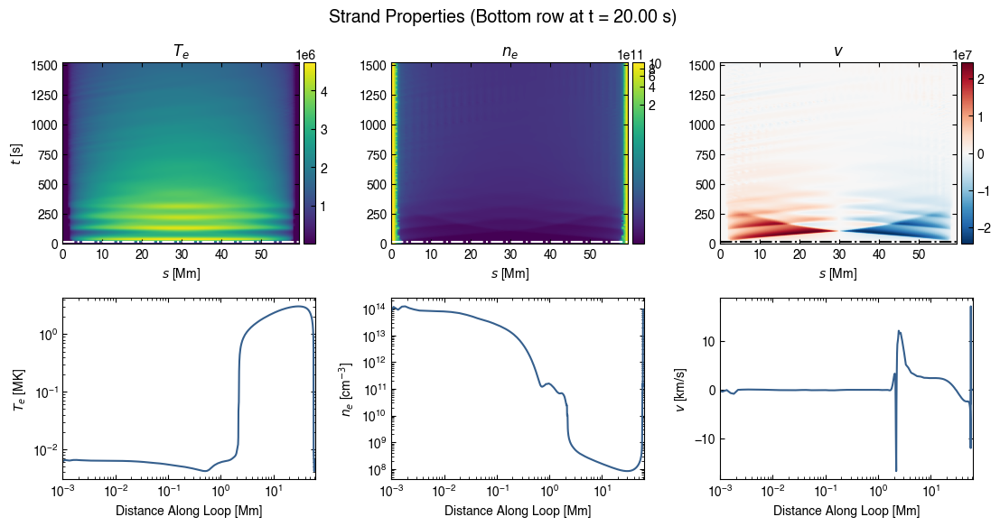

In [176]:
# To load and plot later:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

with open('strand_data.pkl', 'rb') as f:
    data = pickle.load(f)

# Create a mock strand object or use the data directly
quantities = [
    ('electron_temperature', data['electron_temperature']),
    ('electron_density', data['electron_density']),
    ('velocity', data['velocity']),
]
# Create figure with 6 subplots (2 rows, 3 columns)
fig = plt.figure(figsize=(13, 6))
gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)

# Top row: time-distance plots
ax_top = [fig.add_subplot(gs[0, i]) for i in range(3)]

# Bottom row: spatial profiles at specific time
ax_bottom = [fig.add_subplot(gs[1, i]) for i in range(3)]

# Define time index for horizontal line and bottom plots
time_index = 20
time_value = a.time[time_index]

# Plot time-distance diagrams in top row
for i, (label, data_array) in enumerate(quantities):
    # Get time and space arrays
    t_array = data['time'].to(u.s).value
    s_array = data['grid'].to(u.Mm).value
    
    # Set colormap and normalization
    cmap_name = 'RdBu_r' if label == 'velocity' else 'viridis'
    if label == 'electron_density':
        norm = ImageNormalize(vmin=1e8, vmax=1e12, stretch=LogStretch())
    else:
        norm = None
    
    # Plot using imshow - no transpose needed, swap extent to have s on x-axis and t on y-axis
    im = ax_top[i].imshow(data_array.value, 
                         cmap=cmap_name, 
                         norm=norm,
                         aspect='auto',
                         origin='lower',
                         extent=[s_array[0], s_array[-1], t_array[0], t_array[-1]])
    
    # Add colorbar
    cax = make_axes_locatable(ax_top[i]).append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(im, cax=cax)
    
    # Set labels - swap x and y labels
    label_map = {'electron_temperature': r'$T_e$', 'electron_density': r'$n_e$', 'velocity': r'$v$'}
    ax_top[i].set_title(label_map.get(label, label))
    ax_top[i].set_xlabel(r'$s$ [Mm]')
    if i == 0:
        ax_top[i].set_ylabel(r'$t$ [s]')
    # ax_top[i].set_xscale('log')
    
    # Add horizontal line at time_index - now it's a horizontal line since axes are swapped
    t = time_index
    if i != 2:
        ax_top[i].axhline(time_value.to(u.s).value, color='white', linestyle='-.', linewidth=1.5, alpha=1)
    else:
        ax_top[i].axhline(time_value.to(u.s).value, color='black', linestyle='-.', linewidth=1.5, alpha=1)

# Get data at specific time for bottom plots
electron_temp = a[time_index].electron_temperature
electron_dens = a[time_index].electron_density
velocity = a[time_index].velocity
coordinate = a[time_index].coordinate

# Plot electron temperature
ax_bottom[0].plot(coordinate.to(u.Mm), electron_temp.to(u.MK), color=plt.cm.viridis(0.3))
ax_bottom[0].set_ylabel(r'$T_e$ [MK]')
ax_bottom[0].set_yscale('log')
ax_bottom[0].set_xlim(left=1e-3)
ax_bottom[0].set_xlabel('Distance Along Loop [Mm]')
ax_bottom[0].set_xscale('log')

# Plot electron density
ax_bottom[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), color=plt.cm.viridis(0.3))
ax_bottom[1].set_ylabel(r'$n_e$ [cm$^{-3}$]')
ax_bottom[1].set_yscale('log')
ax_bottom[1].set_xlim(left=1e-3)
ax_bottom[1].set_xlabel('Distance Along Loop [Mm]')
ax_bottom[1].set_xscale('log')

# Plot velocity
ax_bottom[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), color=plt.cm.viridis(0.3))
ax_bottom[2].set_ylabel(r'$v$ [km/s]')
ax_bottom[2].set_xlabel('Distance Along Loop [Mm]')
ax_bottom[2].set_xlim(left=1e-3)
ax_bottom[2].set_xscale('log')


fig.suptitle(f'Strand Properties (Bottom row at t = {time_value:.2f})', fontsize=14)
plt.tight_layout()

plt.show()


### Run here

In [1]:
# To load and plot later:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
import pickle
import matplotlib.pyplot as plt
import astropy.units as u
from pydrad.parse import Strand
from astropy.visualization import ImageNormalize, LogStretch
import numpy as np

# Set font to Helvetica and ticks to be inward
plt.rcParams['font.family'] = 'Helvetica'
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['xtick.top'] = True
plt.rcParams['ytick.right'] = True


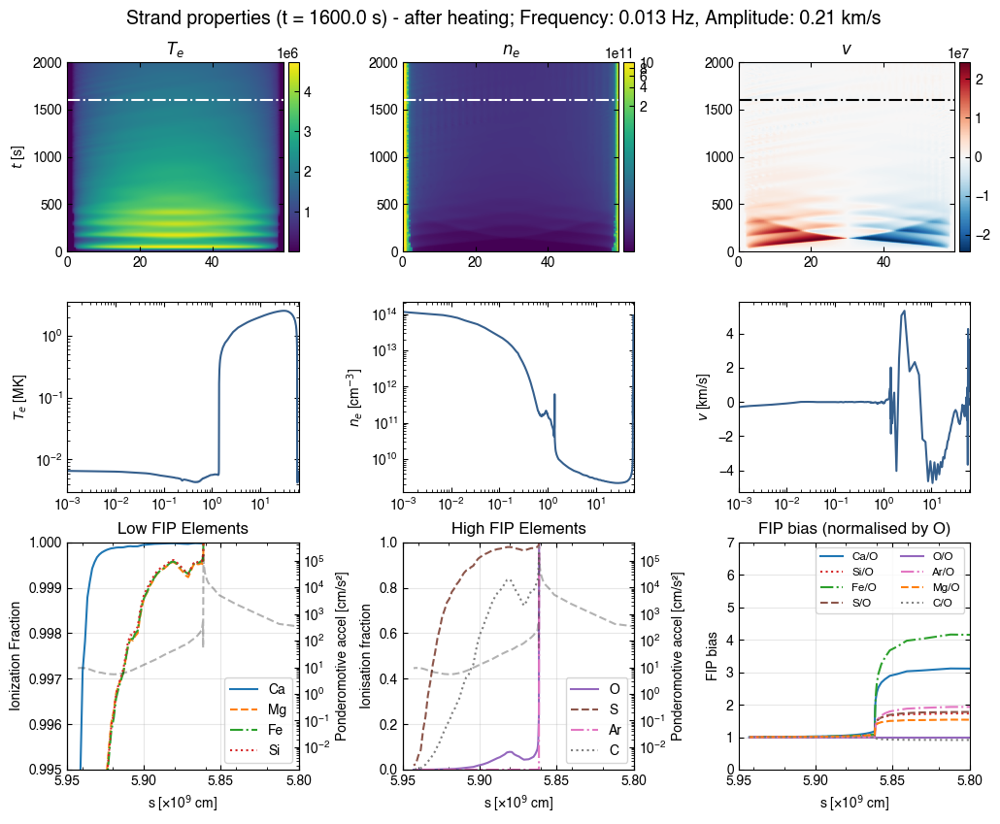

In [2]:
with open('strand_data.pkl', 'rb') as f:
    data = pickle.load(f)

a = Strand('/Users/andysh.to/Script/Python_Script/fip_bias_hydrad/hydards/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H')
time_index = 1600

# Load Alfven data for ionization fractions and FIP bias
frequency = 0.013
amplitude = 0.21
# with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H/v_{frequency:.3f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}.pkl', 'rb') as f:
with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H/v_0.013_A_0.21/test_loop_extra_properties_0.013_0.21_1600.pkl', 'rb') as f:
    alfven_data = pickle.load(f)

# Create a mock strand object or use the data directly
quantities = [
    ('electron_temperature', data['electron_temperature']),
    ('electron_density', data['electron_density']),
    ('velocity', data['velocity']),
]

# Create figure with 6 subplots (2 rows, 3 columns)
fig = plt.figure(figsize=(12, 9))
gs = fig.add_gridspec(3, 3, hspace=0.25, wspace=0.45, height_ratios=[1, 1, 1.2])

# Top row: time-distance plots
ax_top = [fig.add_subplot(gs[0, i]) for i in range(3)]

# Middle row: spatial profiles at specific time
ax_middle = [fig.add_subplot(gs[1, i]) for i in range(3)]

# Bottom row: ionization fractions and FIP bias
ax_bottom = [fig.add_subplot(gs[2, i]) for i in range(3)]

# Define time index for horizontal line and middle plots
time_value = a.time[time_index]

# Plot time-distance diagrams in top row
for i, (label, data_array) in enumerate(quantities):
    # Get coordinate arrays
    t_values = a.time.to(u.s).value
    s_values = data['grid'].to(u.Mm).value
    
    # Set colormap and normalization
    cmap_name = 'RdBu_r' if label == 'velocity' else 'viridis'
    if label == 'electron_density':
        norm = ImageNormalize(vmin=1e8, vmax=1e12, stretch=LogStretch())
    else:
        norm = None
    
    # Create the plot using imshow instead of pcolormesh to avoid dimension issues
    im = ax_top[i].imshow(data_array.value, 
                         cmap=cmap_name, 
                         norm=norm,
                         aspect='auto',
                         origin='lower',
                         extent=[s_values.min(), s_values.max(), t_values.min(), t_values.max()])
    
    # Add colorbar
    cax = make_axes_locatable(ax_top[i]).append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(im, cax=cax)
    
    # Set labels
    label_map = {'electron_temperature': r'$T_e$', 'electron_density': r'$n_e$', 'velocity': r'$v$'}
    ax_top[i].set_title(label_map.get(label, label))
    ax_top[i].set_xlabel('')
    if i == 0:
        ax_top[i].set_ylabel(r'$t$ [s]')
    # ax_top[i].set_yscale('log')
    
    # Add horizontal line at time_index
    t = time_index
    if i != 2:
        ax_top[i].axhline(time_value.to(u.s).value, color='white', linestyle='-.', linewidth=1.5, alpha=1)
    else:
        ax_top[i].axhline(time_value.to(u.s).value, color='black', linestyle='-.', linewidth=1.5, alpha=1)

# Get data at specific time for middle plots
electron_temp = a[time_index].electron_temperature
electron_dens = a[time_index].electron_density
velocity = a[time_index].velocity
coordinate = a[time_index].coordinate

# Plot electron temperature
ax_middle[0].plot(coordinate.to(u.Mm), electron_temp.to(u.MK), color=plt.cm.viridis(0.3))
ax_middle[0].set_ylabel(r'$T_e$ [MK]')
ax_middle[0].set_yscale('log')
ax_middle[0].set_xlim(left=1e-3)
ax_middle[0].set_xlabel('')
ax_middle[0].set_xscale('log')

# Plot electron density
ax_middle[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), color=plt.cm.viridis(0.3))
ax_middle[1].set_ylabel(r'$n_e$ [cm$^{-3}$]')
ax_middle[1].set_yscale('log')
ax_middle[1].set_xlim(left=1e-3)
ax_middle[1].set_xlabel('')
ax_middle[1].set_xscale('log')

# Plot velocity
ax_middle[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), color=plt.cm.viridis(0.3))
ax_middle[2].set_ylabel(r'$v$ [km/s]')
ax_middle[2].set_xlabel('')
ax_middle[2].set_xlim(left=1e-3)
ax_middle[2].set_xscale('log')

# Bottom row: Ionization fractions and FIP bias
s_values = alfven_data['s_values']
ionization_data = alfven_data['ionization_fractions']

# Define consistent colors and line styles for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

element_linestyles = {
    'Ca': '-',      # solid
    'Mg': '--',     # dashed
    'Fe': '-.',     # dash-dot
    'Si': ':',      # dotted
    'O': '-',       # solid
    'S': '--',      # dashed
    'Ar': '-.',     # dash-dot
    'C': ':'        # dotted
}

xmin = 5.95e9
xmax = 5.8e9
ax10_xticks = [5.8e9, 5.85e9, 5.9e9, 5.95e9]

# Plot 1: Ionisation fraction - Low FIP elements (Ca, Mg, Fe, Si)
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
ax_ion_low = ax_bottom[0]
ax_accel_low = ax_ion_low.twinx()

for element in low_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_low.plot(s_values, ionization_data[element], label=element, 
                       color=color, linestyle=linestyle, linewidth=1.5)

ax_accel_low.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                  'k--', alpha=0.3, label='|Pond. Accel|')

ax_ion_low.set_ylabel('Ionization Fraction')
ax_accel_low.set_ylabel('Ponderomotive accel [cm/s²]', color='k')
ax_ion_low.set_xlabel('s [×10$^9$ cm]')
ax_ion_low.set_title('Low FIP Elements')
ax_ion_low.legend(loc='lower right')
# ax_accel_low.legend(loc='upper right')
ax_ion_low.grid(True, alpha=0.3)
ax_ion_low.invert_xaxis()
ax_ion_low.set_xscale('log')
ax_accel_low.set_yscale('log')
ax_accel_low.tick_params(axis='y', labelcolor='k')
from matplotlib.ticker import LogLocator, NullFormatter

# For Low FIP Elements - REMOVE lines 147-148 and replace with:
ax_ion_low.set_xlim(left=xmin, right=xmax)
ax_ion_low.set_ylim(0.995, 1)
ax_ion_low.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_low.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_low.xaxis.set_minor_formatter(NullFormatter())
ax_ion_low.set_xticks(ax10_xticks)
# ax_ion_low.set_yscale('log')
ax_ion_low.set_xticklabels([f'{x/1e9:.2f}' for x in ax10_xticks])


# Plot 2: Ionization fraction - High FIP elements (O, S, Ar, C)
high_fip_elements = ['O', 'S', 'Ar', 'C']
ax_ion_high = ax_bottom[1]
ax_accel_high = ax_ion_high.twinx()

for element in high_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_high.plot(s_values, ionization_data[element], label=element, 
                        color=color, linestyle=linestyle, linewidth=1.5)

ax_accel_high.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                   'k--', alpha=0.3, label='|Pond. Accel|')

ax_ion_high.set_ylabel('Ionisation fraction')
ax_accel_high.set_ylabel('Ponderomotive accel [cm/s²]', color='k')
ax_ion_high.set_xlabel('s [×10$^9$ cm]')
ax_ion_high.set_title('High FIP Elements')
ax_ion_high.legend(loc='lower right')
# ax_accel_high.legend(loc='upper right')
ax_ion_high.grid(True, alpha=0.3)
ax_ion_high.invert_xaxis()
ax_ion_high.set_xscale('log')
ax_accel_high.set_yscale('log')
ax_accel_high.tick_params(axis='y', labelcolor='k')
ax_ion_high.set_xlim(left=xmin, right=xmax)
ax_ion_high.set_ylim(0, 1)

ax_ion_high.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_high.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_high.xaxis.set_minor_formatter(NullFormatter())
ax_ion_high.set_xticks(ax10_xticks)
ax_ion_high.set_xticklabels([f'{x/1e9:.2f}' for x in ax10_xticks])

# Plot 3: FIP Bias Heights (normalized by O)
ax_fip = ax_bottom[2]

# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Plot right footpoint for each element (normalized by oxygen)
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            ax_fip.plot(heights_right, bias_right_normalized, label=f'{element}/O', 
                       linestyle=linestyle, color=color, linewidth=1.5)

ax_fip.set_xlabel('s [×10$^9$ cm]')
ax_fip.set_ylabel('FIP bias')
ax_fip.set_title('FIP bias (normalised by O)')
ax_fip.legend(loc='best', fontsize='small', ncol=2)
ax_fip.grid(True, alpha=0.3)
ax_fip.invert_xaxis()
ax_fip.set_xscale('log')
ax_fip.set_ylim(0, 7)
ax_fip.set_xlim(left=xmin*10, right=xmax*10)
ax_fip.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_fip.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_fip.xaxis.set_minor_formatter(NullFormatter())
ax12_xticks = [x*10 for x in ax10_xticks]

ax_fip.set_xticks(ax12_xticks)
ax_fip.set_xticklabels([f'{x/1e10:.2f}' for x in ax12_xticks])

fig.suptitle(f'Strand properties (t = {time_value:.1f}) - after heating; Frequency: {frequency:.3f} Hz, Amplitude: {amplitude:.2f} km/s', fontsize=14)
# plt.tight_layout()
plt.subplots_adjust(top=0.92)
plt.show()


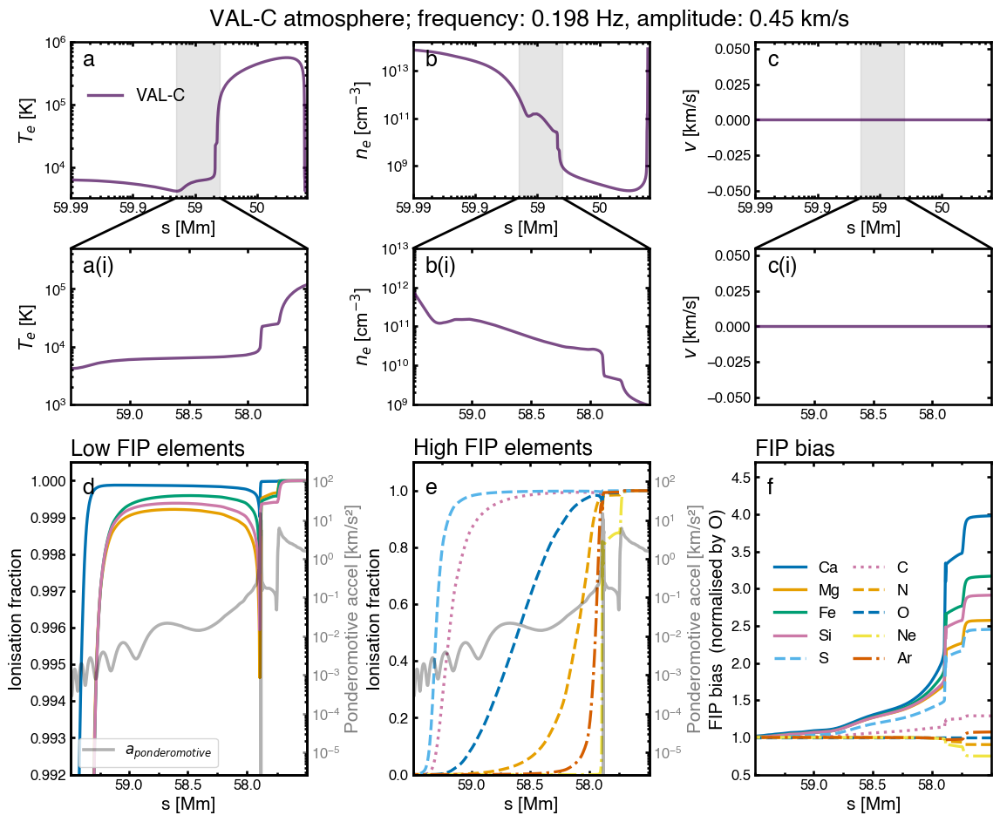

In [5]:
# To load and plot later:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
# Set default line thickness
plt.rcParams['lines.linewidth'] = 2.6
plt.rcParams['axes.linewidth'] = 1.9
plt.rcParams['xtick.major.width'] = 1.9
plt.rcParams['ytick.major.width'] = 1.9
plt.rcParams['xtick.minor.width'] = 1.9
plt.rcParams['ytick.minor.width'] = 1.9
plt.rcParams['grid.linewidth'] = 1.8

with open('strand_data.pkl', 'rb') as f:
    data = pickle.load(f)
linewidths = 2.4
title_size=18
label_size=15
legend_size=12
tick_size=12
time_index = 0
# Load Alfven data for ionization fractions and FIP bias
frequency = 0.198
amplitude = 0.45
acoustic_flux = 1e8*u.erg/u.cm**2/u.s
# print(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/v_{frequency:.4f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.4f}_{amplitude:.2f}_{time_index}_F{acoustic_flux.value:.0e}.pkl')
with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/v_{frequency:.4f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}_F{acoustic_flux.value:.1e}.pkl', 'rb') as f:
    alfven_data = pickle.load(f)


# Create a mock strand object or use the data directly
quantities = [
    ('electron_temperature', data['electron_temperature']),
    ('electron_density', data['electron_density']),
    ('velocity', data['velocity']),
]

# Create figure with 6 subplots (3 rows, 3 columns) - removed top row
fig = plt.figure(figsize=(12, 9.5))
gs = fig.add_gridspec(3, 3, hspace=0.27, wspace=0.45, height_ratios=[0.6, 0.6, 1.2])

# Middle row: spatial profiles at specific time (now first row)
ax_middle = [fig.add_subplot(gs[0, i]) for i in range(3)]

# New row: zoomed-in spatial profiles (now second row)
ax_zoom = [fig.add_subplot(gs[1, i]) for i in range(3)]

# Bottom row: ionization fractions and FIP bias (now third row)
ax_bottom = [fig.add_subplot(gs[2, i]) for i in range(3)]

# Define time index for horizontal line and middle plots
time_value = a.time[time_index]

# Get data at multiple time indices for middle plots
# Define time indices to plot
time_indices = np.linspace(0, len(a.time)-1, 10, dtype=int)  # 10 time snapshots
n_times = len(time_indices)

# Create colormap
cmap = plt.cm.viridis
colors = [cmap(i / (n_times - 1)) for i in range(n_times)]

middle_row_time_indices = time_indices[0:1]

xmin = 5.95e9
xmax = 5.75e9
# xmax = 5.775e9
from matplotlib.patches import ConnectionPatch

# Plot electron temperature evolution
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_temp = a[t_idx].electron_temperature
    coordinate = a[t_idx].coordinate
    ax_middle[0].plot(coordinate.to(u.Mm), electron_temp.to(u.K), 
                     color=colors[idx], alpha=0.7, linewidth=linewidths, label='VAL-C')

ax_middle[0].set_ylabel(r'$T_e$ [K]',fontsize=label_size)
ax_middle[0].set_yscale('log')
ax_middle[0].set_ylim(top=1e6)
ax_middle[0].set_xlim(left=1e-2)
ax_middle[0].set_xlabel('s [Mm]', fontsize=label_size)
ax_middle[0].set_xscale('log')
ax_middle[0].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (a)
ax_middle[0].text(0.05, 0.95, 'a', transform=ax_middle[0].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)
ax_middle[0].legend(frameon=False, fontsize=legend_size+2, loc='upper left', bbox_to_anchor=(0.01, 0.8), columnspacing=0.8)

# Plot electron density evolution
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_dens = a[t_idx].electron_density
    coordinate = a[t_idx].coordinate
    ax_middle[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), 
                     color=colors[idx], alpha=0.7, linewidth=linewidths)

ax_middle[1].set_ylabel(r'$n_e$ [cm$^{-3}$]',fontsize=label_size)
ax_middle[1].set_yscale('log')
ax_middle[1].set_xlim(left=1e-2)
ax_middle[1].set_xlabel('s [Mm]', fontsize=label_size)
ax_middle[1].set_xscale('log')
ax_middle[1].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (b)
ax_middle[1].text(0.05, 0.95, 'b', transform=ax_middle[1].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot velocity evolution
for idx, t_idx in enumerate(middle_row_time_indices):
    velocity = a[t_idx].velocity
    coordinate = a[t_idx].coordinate
    ax_middle[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), 
                     color=colors[idx], alpha=0.7, linewidth=linewidths)

ax_middle[2].set_ylabel(r'$v$ [km/s]',fontsize=label_size)
ax_middle[2].set_xlabel('s [Mm]', fontsize=label_size)
ax_middle[2].set_xlim(left=1e-2)
ax_middle[2].set_xscale('log')
ax_middle[2].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (c)
ax_middle[2].text(0.05, 0.95, 'c', transform=ax_middle[2].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Add grey box highlighting for all middle plots
for ax in ax_middle:
    ax.axvspan(60-xmax/1e8, 60-xmin/1e8, alpha=0.2, color='grey', zorder=0)
    # ax.invert_xaxis()
    # ax.set_xlim(left=60-1e-2)
    ax.set_xticks([0.01, 0.1, 1, 10])
    ax.set_xticklabels([59.99, 59.9, 59, 50])

# New zoomed-in row: Plot the grey-highlighted region
# Plot electron temperature evolution (zoomed)
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_temp = a[t_idx].electron_temperature
    coordinate = a[t_idx].coordinate
    ax_zoom[0].plot(coordinate.to(u.Mm), electron_temp.to(u.K), 
                     color=colors[idx], alpha=0.7, linewidth=linewidths)

ax_zoom[0].set_ylabel(r'$T_e$ [K]',fontsize=label_size)
ax_zoom[0].set_yscale('log')
ax_zoom[0].set_xlabel('s [Mm]', fontsize=label_size)
ax_zoom[0].set_ylim(1e3,5e5)
ax_zoom[0].set_xlim(60-xmax/1e8, 60-xmin/1e8)
ax_zoom[0].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (a(i))
ax_zoom[0].text(0.05, 0.95, 'a(i)', transform=ax_zoom[0].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot electron density evolution (zoomed)
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_dens = a[t_idx].electron_density
    coordinate = a[t_idx].coordinate
    ax_zoom[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), 
                     color=colors[idx], alpha=0.7, linewidth=linewidths)

ax_zoom[1].set_ylabel(r'$n_e$ [cm$^{-3}$]',fontsize=label_size)
ax_zoom[1].set_yscale('log')
ax_zoom[1].set_ylim(1e9,1e13)
ax_zoom[1].set_xlabel('s [Mm]', fontsize=label_size)
ax_zoom[1].set_xlim(60-xmax/1e8, 60-xmin/1e8)
ax_zoom[1].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (b(i))
ax_zoom[1].text(0.05, 0.95, 'b(i)', transform=ax_zoom[1].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot velocity evolution (zoomed)
for idx, t_idx in enumerate(middle_row_time_indices):
    velocity = a[t_idx].velocity
    coordinate = a[t_idx].coordinate
    ax_zoom[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), 
                     color=colors[idx], alpha=0.7, linewidth=linewidths)

ax_zoom[2].set_ylabel(r'$v$ [km/s]',fontsize=label_size)
ax_zoom[2].set_xlabel('s [Mm]', fontsize=label_size)
ax_zoom[2].set_xlim(60-xmax/1e8, 60-xmin/1e8)
ax_zoom[2].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (c(i))
ax_zoom[2].text(0.05, 0.95, 'c(i)', transform=ax_zoom[2].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

for ax in ax_zoom:
    ax.invert_xaxis()

# Add connection patches from grey box in ax_middle to ax_zoom
# Grey box x-coordinates in ax_middle (in Mm)
grey_left = 60 - xmax/1e8  # left edge of grey box
grey_right = 60 - xmin/1e8  # right edge of grey box

for i in range(3):
    # Get y-limits for the middle and zoom axes
    middle_ylim = ax_middle[i].get_ylim()
    zoom_ylim = ax_zoom[i].get_ylim()
    
    # Connection from left edge of grey box (bottom) to left edge of zoom (top)
    con_left = ConnectionPatch(
        xyA=(grey_left, middle_ylim[0]), coordsA=ax_middle[i].transData,
        xyB=(grey_left, zoom_ylim[1]), coordsB=ax_zoom[i].transData,
        color='k', linestyle='-', linewidth=2, alpha=1
    )
    fig.add_artist(con_left)
    
    # Connection from right edge of grey box (bottom) to right edge of zoom (top)
    con_right = ConnectionPatch(
        xyA=(grey_right, middle_ylim[0]), coordsA=ax_middle[i].transData,
        xyB=(grey_right, zoom_ylim[1]), coordsB=ax_zoom[i].transData,
        color='k', linestyle='-', linewidth=2, alpha=1
    )
    fig.add_artist(con_right)

# Bottom row: Ionization fractions and FIP bias
s_values = alfven_data['s_values']
ionization_data = alfven_data['ionization_fractions']

# Define consistent colors and line styles for each element
# Colorblind-friendly palette: Low FIP (solid lines), High FIP (other line styles)
# Using colors that are distinguishable for colorblind viewers
element_colors = {
    # Low FIP elements - solid lines, colorblind-friendly colors
    'Ca': '#0072B2',  # Blue
    'Mg': '#E69F00',  # Orange
    'Fe': '#009E73',  # Teal/Green
    'Si': '#CC79A7',  # Pink/Magenta
    # High FIP elements - various line styles, colorblind-friendly colors
    'O': '#0072B2',   # Blue (dashed)
    'S': '#56B4E9',   # Orange (dashed)
    'Ar': '#D55E00',  # Sky blue (dashdot)
    'C': '#CC79A7',   # Pink/Magenta (dotted)
    'Ne': '#F0E442', # Yellow (solid)
    'N': '#E69F00',   # Vermillion (dashed)
}

element_linestyles = {
    # Low FIP elements - all solid
    'Ca': '-',   'Mg': '-',  'Fe': '-',  'Si': '-',
    # High FIP elements - various styles (avoiding same color+style confusion)
    'O': '--',    'S': '--',   'Ar': '-.',  'C': ':',  'Ne': '-.',  'N': '--'
}

ax10_xticks = [5.8e9, 5.85e9, 5.9e9]

# Plot 1: Ionization fraction - Low FIP elements (Ca, Mg, Fe, Si)
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
ax_ion_low = ax_bottom[0]
ax_accel_low = ax_ion_low.twinx()

for element in low_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_low.plot(s_values, ionization_data[element], label=element, 
                       color=color, linestyle=linestyle, linewidth=linewidths)

ax_accel_low.plot(s_values, -(alfven_data['ponderomotive_acceleration']/1e5), 
                   'k-', alpha=0.3, label='$a_{ponderomotive}$')
acceleration_inverse = alfven_data['ponderomotive_acceleration'][::-1]
# ax_accel_low.plot(s_values, np.abs(acceleration_inverse), 
#                    'r-', alpha=0.3, label='$a_{ponderomotive}$ (inverse)')
ax_ion_low.set_ylabel('Ionisation fraction', fontsize=label_size)
ax_accel_low.set_ylabel('Ponderomotive accel [km/s²]', color='grey',fontsize=label_size)
ax_ion_low.set_xlabel('s [Mm]',fontsize=label_size)
ax_ion_low.set_title('Low FIP elements', fontsize=title_size, loc='left')
# ax_ion_low.legend(loc='lower right', fontsize=legend_size)
ax_accel_low.legend(loc='lower left', fontsize=legend_size)
ax_ion_low.invert_xaxis()
ax_ion_low.set_xscale('log')
ax_accel_low.set_yscale('log')
ax_accel_low.tick_params(axis='y', labelcolor='grey', labelsize=tick_size, color='grey')
ax_ion_low.tick_params(axis='both', labelsize=tick_size)
from matplotlib.ticker import LogLocator, NullFormatter

# For Low FIP Elements - REMOVE lines 147-148 and replace with:
ax_ion_low.set_xlim(left=xmin, right=xmax)
ax_ion_low.set_ylim(0.992, 1.0005)
ax_ion_low.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_low.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_low.xaxis.set_minor_formatter(NullFormatter())
ax_ion_low.set_xticks(ax10_xticks)
# ax_ion_low.set_yscale('log')
ax_ion_low.set_xticklabels([f'{x/1e8:.1f}' for x in ax10_xticks])
# Add subplot label (d)
ax_ion_low.text(0.05, 0.95, 'd', transform=ax_ion_low.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='left',)


# Plot 2: Ionization fraction - High FIP elements (O, S, Ar, C)
high_fip_elements = ['C', 'N', 'O', 'Ne', 'S', 'Ar']
ax_ion_high = ax_bottom[1]
ax_accel_high = ax_ion_high.twinx()

for element in high_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_high.plot(s_values, ionization_data[element], label=element, 
                        color=color, linestyle=linestyle, linewidth=linewidths)

ax_accel_high.plot(s_values, -(alfven_data['ponderomotive_acceleration']/1e5), 
                   'k-', alpha=0.3, label='$a_{ponderomotive}$')

ax_ion_high.set_ylabel('Ionisation fraction',fontsize=label_size)
ax_accel_high.set_ylabel('Ponderomotive accel [km/s²]', color='grey',fontsize=label_size)
ax_ion_high.set_xlabel('s [Mm]',fontsize=label_size)
ax_ion_high.set_title('High FIP elements', fontsize=title_size, loc='left')
# ax_ion_high.legend(loc='lower right', fontsize=legend_size)
# ax_accel_high.legend(loc='lower left', fontsize=legend_size)
ax_ion_high.invert_xaxis()
ax_ion_high.set_xscale('log')
ax_accel_high.set_yscale('log')
ax_accel_high.tick_params(axis='y', labelcolor='grey', labelsize=tick_size)
ax_ion_high.tick_params(axis='both', labelsize=tick_size)
ax_ion_high.set_xlim(left=xmin, right=xmax)
ax_ion_high.set_ylim(0, 1.1)

ax_ion_high.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_high.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_high.xaxis.set_minor_formatter(NullFormatter())
ax_ion_high.set_xticks(ax10_xticks)
ax_ion_high.set_xticklabels([f'{x/1e8:.1f}' for x in ax10_xticks])
# Add subplot label (e)
ax_ion_high.text(0.05, 0.95, 'e', transform=ax_ion_high.transAxes, 
                 fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot 3: FIP Bias Heights (normalized by O)
ax_fip = ax_bottom[2]

# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Plot right footpoint for each element (normalized by oxygen)
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            ax_fip.plot(heights_right, bias_right_normalized, label=f'{element}', 
                       linestyle=linestyle, color=color, linewidth=linewidths)

ax_fip.set_xlabel('s [Mm]',fontsize=label_size)
ax_fip.set_ylabel('FIP bias  (normalised by O)',fontsize=label_size)
ax_fip.set_title('FIP bias', fontsize=title_size, loc='left')
ax_fip.set_ylim(0.5, 4.7)
# ax_fip.set_yticks([1,2,3,4])
# ax_fip.set_yticklabels([1,2,3,4])
# ax_fip.grid(True, alpha=0.3)
ax_fip.invert_xaxis()
ax_fip.set_xscale('log')
ax_fip.legend(loc='lower left', fontsize=legend_size+1, ncol=2, frameon=False, bbox_to_anchor=(0.02, 0.3), columnspacing=0.8)

ax_fip.set_xlim(left=xmin*10, right=xmax*10)
ax_fip.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_fip.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_fip.xaxis.set_minor_formatter(NullFormatter())
ax12_xticks = [x*10 for x in ax10_xticks]

ax_fip.set_xticks(ax12_xticks)
ax_fip.set_xticklabels([f'{x/1e9:.1f}' for x in ax12_xticks])
ax_fip.tick_params(axis='both', labelsize=tick_size)
# Add subplot label (f)
ax_fip.text(0.05, 0.95, 'f', transform=ax_fip.transAxes, 
            fontsize=title_size, fontweight='bold', va='top', ha='left',)

fig.suptitle(f'VAL-C atmosphere; frequency: {frequency:.3f} Hz, amplitude: {amplitude:.2f} km/s', fontsize=title_size+1)
# plt.tight_layout()
plt.subplots_adjust(top=0.93,bottom=0.04,left=0.062,right=0.942)
# plt.tight_layout()
for num, ax_list in enumerate([ax_middle, ax_zoom]):
    if num == 0:
        moving_up = 0.01
    else:
        moving_up = 0.017
    for ax in ax_list:
        pos = ax.get_position()
        ax.set_position([pos.x0, pos.y0 + moving_up, pos.width, pos.height])
for ax in [ax_ion_low,ax_ion_high,ax_fip]:
    pos = ax.get_position()
    ax.set_position([pos.x0, pos.y0 + 0.015, pos.width, pos.height])
    
for ax in ax_zoom:
    ax.set_xticks([1,1.5,2])
    ax.set_xticklabels([59.00,58.50,58.00])
    ax.set_xlabel('')

plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}.png', dpi=400)
plt.show()




In [493]:
# Get delta_B from the alfven_data
delta_B_over_sqrt_4pi_rho = alfven_data['delta_B_over_sqrt_4pi_rho']
rho = alfven_data['rho']

# Calculate delta_B: delta_B = delta_B_over_sqrt_4pi_rho * sqrt(4*pi*rho)
delta_B = delta_B_over_sqrt_4pi_rho * np.sqrt(4 * np.pi * rho)

np.abs(delta_B)/750

<Quantity [0.02817815, 0.02817815, 0.02817815, ..., 0.04991298, 0.04830934,
           0.04811542] g(1/2) / (cm(1/2) s)>

In [53]:
np.mean(alfven_data['VA_s']/3)/(2*60*1e8*u.cm)

<Quantity 0.01008388 1 / s>

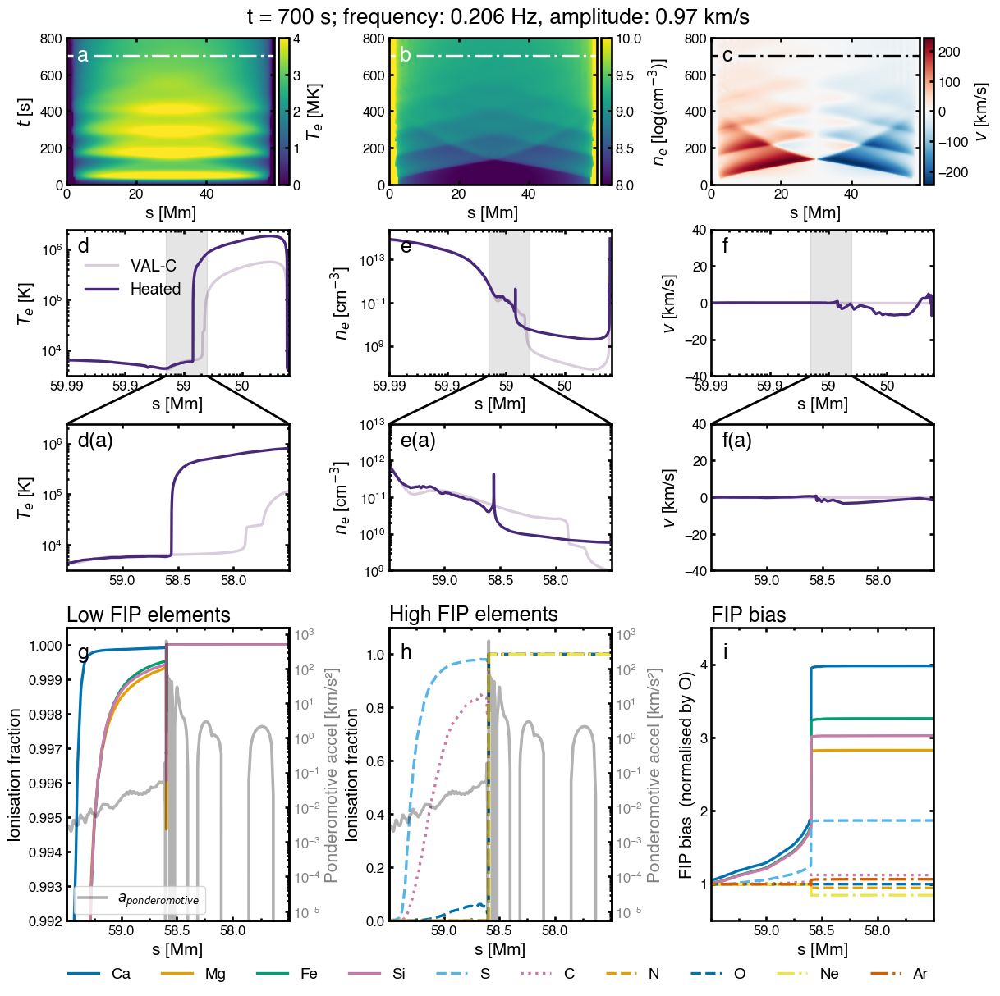

In [6]:
# To load and plot later:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
# Set default line thickness
plt.rcParams['lines.linewidth'] = 2.6
plt.rcParams['axes.linewidth'] = 1.9
plt.rcParams['xtick.major.width'] = 1.9
plt.rcParams['ytick.major.width'] = 1.9
plt.rcParams['xtick.minor.width'] = 1.9
plt.rcParams['ytick.minor.width'] = 1.9
plt.rcParams['grid.linewidth'] = 1.8

with open('strand_data.pkl', 'rb') as f:
    data = pickle.load(f)
linewidths = 2.4
title_size=18
label_size=15
legend_size=12
tick_size=12
time_index = 700
# Load Alfven data for ionization fractions and FIP bias
frequency = 0.206
amplitude = 0.97

acoustic_flux = 1e8*u.erg/u.cm**2/u.s
# print(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/v_{frequency:.4f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.4f}_{amplitude:.2f}_{time_index}_F{acoustic_flux.value:.0e}.pkl')
with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/v_{frequency:.4f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}_F{acoustic_flux.value:.1e}.pkl', 'rb') as f:
    alfven_data = pickle.load(f)


# Create a mock strand object or use the data directly
quantities = [
    ('electron_temperature', data['electron_temperature']),
    ('electron_density', data['electron_density']),
    ('velocity', data['velocity']),
]

# Create figure with 6 subplots (2 rows, 3 columns)
fig = plt.figure(figsize=(12, 12.3))
gs = fig.add_gridspec(4, 3, hspace=0.3, wspace=0.45, height_ratios=[0.6, 0.6, 0.6, 1.2])

# Top row: time-distance plots
ax_top = [fig.add_subplot(gs[0, i]) for i in range(3)]

# Middle row: spatial profiles at specific time
ax_middle = [fig.add_subplot(gs[1, i]) for i in range(3)]

# New row: zoomed-in spatial profiles
ax_zoom = [fig.add_subplot(gs[2, i]) for i in range(3)]

# Bottom row: ionization fractions and FIP bias
ax_bottom = [fig.add_subplot(gs[3, i]) for i in range(3)]

# Define time index for horizontal line and middle plots
time_value = a.time[time_index]

# Plot time-distance diagrams in top row
for i, (label, data_array) in enumerate(quantities):
    # Get coordinate arrays
    t_values = a.time.to(u.s).value
    s_values = data['grid'].to(u.Mm).value
    
    # Set colormap and normalization
    cmap_name = 'RdBu_r' if label == 'velocity' else 'viridis'
    if label == 'electron_density':
        norm = ImageNormalize(vmin=1e8, vmax=10, stretch=LogStretch())
    else:
        norm = None
    
    # Convert temperature to MK for top left plot, take log10 of density for middle plot
    if label == 'electron_temperature':
        plot_data = data_array.to(u.K).value/1e6
    elif label == 'electron_density':
        plot_data = np.log10(data_array.to(u.cm**-3).value)
    else:
        plot_data = data_array.to(u.km/u.s).value
    
    # Create the plot using imshow instead of pcolormesh to avoid dimension issues
    im = ax_top[i].imshow(plot_data, 
                         cmap=cmap_name, 
                         norm=norm if label != 'electron_density' else None,
                         aspect='auto',
                         origin='lower',
                         extent=[s_values.min(), s_values.max(), t_values.min(), t_values.max()])
    
    # Add colorbar
    cax = make_axes_locatable(ax_top[i]).append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(im, cax=cax)
    cbar.ax.tick_params(labelsize=tick_size)
    
    # Set colorbar limits and labels with units
    if i == 1:
        cbar.mappable.set_clim(8, 10)
        cbar.set_label(r'$n_e$ [log(cm$^{-3}$)]', fontsize=label_size)
    elif i == 0:
        cbar.mappable.set_clim(0, 4)
        cbar.set_label(r'$T_e$ [MK]', fontsize=label_size)
    else:
        cbar.set_label(r'$v$ [km/s]', fontsize=label_size)
    
    # Set labels
    label_map = {'electron_temperature': r'$T_e$', 'electron_density': r'$n_e$', 'velocity': r'$v$'}
    # ax_top[i].set_title(label_map.get(label, label), fontsize=title_size, loc='left')
    ax_top[i].set_xlabel('s [Mm]', fontsize=label_size)
    if i == 0:
        ax_top[i].set_ylabel(r'$t$ [s]',fontsize=label_size)
    # ax_top[i].set_yscale('log')
    ax_top[i].tick_params(axis='both', labelsize=tick_size)
    
    # Set y-axis limits to trim from t=0 to t=1000
    ax_top[i].set_ylim(0, 800)
    
    # Add horizontal line at time_index, split to avoid overlapping with subplot label
    t = time_index
    line_y = time_value.to(u.s).value
    line_color = 'white' if i != 2 else 'black'
    
    # Get the x-axis limits to calculate the gap for the label
    xlim = ax_top[i].get_xlim()
    x_range = xlim[1] - xlim[0]
    
    # Leave a gap at the left side where the label is (approximately 0.05 to 0.15 in axes coordinates)
    gap_start = xlim[0]
    gap_end = xlim[0] + 0.13 * x_range  # Gap for the label area
    short_line_end = xlim[0] + 0.03 * x_range  # Short line before the label
    
    # Draw three line segments: short one at left, gap for label, then rest of line
    ax_top[i].hlines(line_y, gap_start, short_line_end, color=line_color, linestyle='-.', linewidth=linewidths, alpha=1)
    ax_top[i].hlines(line_y, gap_end, xlim[1], color=line_color, linestyle='-.', linewidth=linewidths, alpha=1)
    
    # Add subplot label (a, b, c)
    text_color = 'white' if i in [0, 1] else 'black'
    ax_top[i].text(0.05, 0.95, chr(97 + i), transform=ax_top[i].transAxes, 
                   fontsize=title_size, fontweight='bold', va='top', ha='left',
                   color=text_color)

# Get data at multiple time indices for middle plots
# Define time indices to plot
time_indices = np.linspace(0, len(a.time)-1, 2, dtype=int)  # 10 time snapshots
n_times = len(time_indices)

# Create colormap
cmap = plt.cm.viridis
colors = [cmap(i / (10 - 1)) for i in range(n_times)]
# colors = [cmap(i / (n_times - 1)) for i in range(n_times)]

middle_row_time_indices = time_indices[0:1000]

xmin = 5.95e9
xmax = 5.75e9

# Plot electron temperature evolution
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_temp = a[t_idx].electron_temperature
    coordinate = a[t_idx].coordinate
    if idx == 0:
        ax_middle[0].plot(coordinate.to(u.Mm), electron_temp.to(u.K), 
                     color=colors[idx], alpha=0.2, linewidth=linewidths,label='VAL-C')
    else:
        ax_middle[0].plot(coordinate.to(u.Mm), electron_temp.to(u.K), 
                     color=colors[idx], alpha=1, linewidth=linewidths,label='Heated')

ax_middle[0].set_ylabel(r'$T_e$ [K]',fontsize=label_size)
ax_middle[0].set_yscale('log')
ax_middle[0].set_xlim(left=1e-2)
ax_middle[0].set_xlabel('s [Mm]', fontsize=label_size)
ax_middle[0].set_xscale('log')
ax_middle[0].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (d)
ax_middle[0].text(0.05, 0.95, 'd', transform=ax_middle[0].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)
ax_middle[0].legend(frameon=False, fontsize=legend_size+2, loc='upper left', bbox_to_anchor=(0.02, 0.9), columnspacing=0.8)

# Plot electron density evolution
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_dens = a[t_idx].electron_density
    coordinate = a[t_idx].coordinate
    if idx == 0:
        ax_middle[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), 
                     color=colors[idx], alpha=0.2, linewidth=linewidths)
    else:
        ax_middle[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), 
                     color=colors[idx], alpha=1, linewidth=linewidths)

ax_middle[1].set_ylabel(r'$n_e$ [cm$^{-3}$]',fontsize=label_size)
ax_middle[1].set_yscale('log')
ax_middle[1].set_xlim(left=1e-2)
ax_middle[1].set_xlabel('s [Mm]', fontsize=label_size)
ax_middle[1].set_xscale('log')
ax_middle[1].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (e)
ax_middle[1].text(0.05, 0.95, 'e', transform=ax_middle[1].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot velocity evolution
for idx, t_idx in enumerate(middle_row_time_indices):
    velocity = a[t_idx].velocity
    coordinate = a[t_idx].coordinate
    if idx == 0:
        ax_middle[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), 
                     color=colors[idx], alpha=0.2, linewidth=linewidths)
    else:
        ax_middle[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), 
                     color=colors[idx], alpha=1, linewidth=linewidths)

ax_middle[2].set_ylabel(r'$v$ [km/s]',fontsize=label_size)
ax_middle[2].set_xlabel('s [Mm]', fontsize=label_size)
ax_middle[2].set_xlim(left=1e-2)
ax_middle[2].set_xscale('log')
ax_middle[2].set_ylim(-40,40)
ax_middle[2].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (f)
ax_middle[2].text(0.05, 0.95, 'f', transform=ax_middle[2].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Add grey box highlighting for all middle plots
for ax in ax_middle:
    ax.axvspan(60-xmax/1e8, 60-xmin/1e8, alpha=0.2, color='grey', zorder=0)
    # ax.invert_xaxis()
    # ax.set_xlim(left=60-1e-2)
    ax.set_xticks([0.01, 0.1, 1, 10])
    ax.set_xticklabels([59.99, 59.9, 59, 50])



# New zoomed-in row: Plot the grey-highlighted region
# Plot electron temperature evolution (zoomed)
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_temp = a[t_idx].electron_temperature
    coordinate = a[t_idx].coordinate
    if idx == 0:
        ax_zoom[0].plot(coordinate.to(u.Mm), electron_temp.to(u.K), 
                     color=colors[idx], alpha=0.2, linewidth=linewidths)
    else:
        ax_zoom[0].plot(coordinate.to(u.Mm), electron_temp.to(u.K), 
                     color=colors[idx], alpha=1, linewidth=linewidths)

ax_zoom[0].set_ylabel(r'$T_e$ [K]',fontsize=label_size)
ax_zoom[0].set_yscale('log')
ax_zoom[0].set_xlabel('s [Mm]', fontsize=label_size)
ax_zoom[0].set_xlim(60-xmax/1e8, 60-xmin/1e8)
ax_zoom[0].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (d(a))
ax_zoom[0].text(0.05, 0.95, 'd(a)', transform=ax_zoom[0].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot electron density evolution (zoomed)
for idx, t_idx in enumerate(middle_row_time_indices):
    electron_dens = a[t_idx].electron_density
    coordinate = a[t_idx].coordinate
    if idx == 0:
        ax_zoom[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), 
                     color=colors[idx], alpha=0.2, linewidth=linewidths)
    else:
        ax_zoom[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), 
                     color=colors[idx], alpha=1, linewidth=linewidths)

ax_zoom[1].set_ylabel(r'$n_e$ [cm$^{-3}$]',fontsize=label_size)
ax_zoom[1].set_yscale('log')
ax_zoom[1].set_xlabel('s [Mm]', fontsize=label_size)
ax_zoom[1].set_ylim(1e9,1e13)
ax_zoom[1].set_xlim(60-xmax/1e8, 60-xmin/1e8)
ax_zoom[1].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (e(a))
ax_zoom[1].text(0.05, 0.95, 'e(a)', transform=ax_zoom[1].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot velocity evolution (zoomed)
for idx, t_idx in enumerate(middle_row_time_indices):
    velocity = a[t_idx].velocity
    coordinate = a[t_idx].coordinate
    if idx == 0:
        line_valc, = ax_zoom[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), 
                     color=colors[idx], alpha=0.2, linewidth=linewidths)
    else:
        line_heated, = ax_zoom[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), 
                     color=colors[idx], alpha=1, linewidth=linewidths)

ax_zoom[2].set_ylabel(r'$v$ [km/s]',fontsize=label_size)
ax_zoom[2].set_xlabel('s [Mm]', fontsize=label_size)
ax_zoom[2].set_ylim(-40,40)
ax_zoom[2].set_xlim(60-xmax/1e8, 60-xmin/1e8)
ax_zoom[2].tick_params(axis='both', labelsize=tick_size)
# Add subplot label (f(a))
ax_zoom[2].text(0.05, 0.95, 'f(a)', transform=ax_zoom[2].transAxes, 
                  fontsize=title_size, fontweight='bold', va='top', ha='left',)

for i in range(3):
    # Get y-limits for the middle and zoom axes
    middle_ylim = ax_middle[i].get_ylim()
    zoom_ylim = ax_zoom[i].get_ylim()
    
    # Connection from left edge of grey box (bottom) to left edge of zoom (top)
    con_left = ConnectionPatch(
        xyA=(grey_left, middle_ylim[0]), coordsA=ax_middle[i].transData,
        xyB=(grey_left, zoom_ylim[1]), coordsB=ax_zoom[i].transData,
        color='k', linestyle='-', linewidth=2, alpha=1
    )
    fig.add_artist(con_left)
    
    # Connection from right edge of grey box (bottom) to right edge of zoom (top)
    con_right = ConnectionPatch(
        xyA=(grey_right, middle_ylim[0]), coordsA=ax_middle[i].transData,
        xyB=(grey_right, zoom_ylim[1]), coordsB=ax_zoom[i].transData,
        color='k', linestyle='-', linewidth=2, alpha=1
    )
    fig.add_artist(con_right)

for ax in ax_zoom:
    ax.invert_xaxis()
# Bottom row: Ionization fractions and FIP bias
s_values = alfven_data['s_values']
ionization_data = alfven_data['ionization_fractions']


ax10_xticks = [5.8e9, 5.85e9, 5.9e9]

# Plot 1: Ionization fraction - Low FIP elements (Ca, Mg, Fe, Si)
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
ax_ion_low = ax_bottom[0]
ax_accel_low = ax_ion_low.twinx()

for element in low_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_low.plot(s_values, ionization_data[element], label=element, 
                       color=color, linestyle=linestyle, linewidth=linewidths)

ax_accel_low.plot(s_values, -(alfven_data['ponderomotive_acceleration']/1e5), 
                   'k-', alpha=0.3, label='$a_{ponderomotive}$')
# acceleration_inverse = alfven_data['ponderomotive_acceleration'][::-1]
# ax_accel_low.plot(s_values, np.abs(acceleration_inverse), 
#                    'r-', alpha=0.3, label='$a_{ponderomotive}$ (inverse)')
ax_ion_low.set_ylabel('Ionisation fraction', fontsize=label_size)
ax_ion_low.set_xlabel('s [Mm]',fontsize=label_size)
ax_ion_low.set_title('Low FIP elements', fontsize=title_size, loc='left')
# ax_ion_low.legend(loc='lower right', fontsize=legend_size)
ax_accel_low.legend(loc='lower left', fontsize=legend_size)
ax_ion_low.invert_xaxis()
ax_ion_low.set_xscale('log')
ax_accel_low.set_yscale('log')
ax_accel_low.set_ylabel('Ponderomotive accel [km/s²]', color='grey',fontsize=label_size)
ax_accel_low.tick_params(axis='y', labelcolor='grey', labelsize=tick_size)
ax_ion_low.tick_params(axis='both', labelsize=tick_size)
from matplotlib.ticker import LogLocator, NullFormatter

# For Low FIP Elements - REMOVE lines 147-148 and replace with:
ax_ion_low.set_xlim(left=xmin, right=xmax)
ax_ion_low.set_ylim(0.992, 1.0005)
ax_ion_low.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_low.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_low.xaxis.set_minor_formatter(NullFormatter())
ax_ion_low.set_xticks(ax10_xticks)
# ax_ion_low.set_yscale('log')
ax_ion_low.set_xticklabels([f'{x/1e8:.1f}' for x in ax10_xticks])
# Add subplot label (g)
ax_ion_low.text(0.05, 0.95, 'g', transform=ax_ion_low.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='left',)


# Plot 2: Ionization fraction - High FIP elements (O, S, Ar, C)
high_fip_elements = ['C', 'S', 'N', 'O', 'Ar', 'Ne']
ax_ion_high = ax_bottom[1]
ax_accel_high = ax_ion_high.twinx()

for element in high_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_high.plot(s_values, ionization_data[element], label=element, 
                        color=color, linestyle=linestyle, linewidth=linewidths)

ax_accel_high.plot(s_values, -(alfven_data['ponderomotive_acceleration']/1e5), 
                   'k-', alpha=0.3)

ax_ion_high.set_ylabel('Ionisation fraction',fontsize=label_size)
ax_ion_high.set_xlabel('s [Mm]',fontsize=label_size)
ax_ion_high.set_title('High FIP elements', fontsize=title_size, loc='left')
# ax_ion_high.legend(loc='lower right', fontsize=legend_size)
# ax_accel_high.legend(loc='lower left', fontsize=legend_size)
ax_ion_high.invert_xaxis()
ax_ion_high.set_xscale('log')
ax_accel_high.set_yscale('log')
ax_accel_high.set_ylabel('Ponderomotive accel [km/s²]', color='grey',fontsize=label_size)
ax_accel_high.tick_params(axis='y', labelcolor='grey', labelsize=tick_size)
ax_ion_high.tick_params(axis='both', labelsize=tick_size)
ax_ion_high.set_xlim(left=xmin, right=xmax)
ax_ion_high.set_ylim(0, 1.1)

ax_ion_high.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_high.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_high.xaxis.set_minor_formatter(NullFormatter())
ax_ion_high.set_xticks(ax10_xticks)
ax_ion_high.set_xticklabels([f'{x/1e8:.1f}' for x in ax10_xticks])
# Add subplot label (h)
ax_ion_high.text(0.05, 0.95, 'h', transform=ax_ion_high.transAxes, 
                 fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot 3: FIP Bias Heights (normalized by O)
ax_fip = ax_bottom[2]

# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Collect legend handles and labels for the combined legend
legend_handles = []
legend_labels = []

# Plot right footpoint for each element (normalized by oxygen)
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            line, = ax_fip.plot(heights_right, bias_right_normalized, label=f'{element}', 
                       linestyle=linestyle, color=color, linewidth=linewidths)
            legend_handles.append(line)
            legend_labels.append(element)

ax_fip.set_xlabel('s [Mm]',fontsize=label_size)
ax_fip.set_ylabel('FIP bias  (normalised by O)',fontsize=label_size)
ax_fip.set_title('FIP bias', fontsize=title_size, loc='left')
ax_fip.set_ylim(0.5, 4.5)
ax_fip.set_yticks([1,2,3,4])
# ax_fip.set_yticklabels([1,2,3,4])
# ax_fip.grid(True, alpha=0.3)
ax_fip.invert_xaxis()
ax_fip.set_xscale('log')

ax_fip.set_xlim(left=xmin*10, right=xmax*10)
ax_fip.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_fip.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_fip.xaxis.set_minor_formatter(NullFormatter())
ax12_xticks = [x*10 for x in ax10_xticks]

ax_fip.set_xticks(ax12_xticks)
ax_fip.set_xticklabels([f'{x/1e9:.1f}' for x in ax12_xticks])
ax_fip.tick_params(axis='both', labelsize=tick_size)
# Add subplot label (i)
ax_fip.text(0.05, 0.95, 'i', transform=ax_fip.transAxes, 
            fontsize=title_size, fontweight='bold', va='top', ha='left',)

fig.suptitle(f't = {time_value:.0f}; frequency: {frequency:.3f} Hz, amplitude: {amplitude:.2f} km/s', fontsize=title_size+1)
# plt.tight_layout()
plt.subplots_adjust(top=0.95,bottom=0.06,left=0.062,right=0.942)
# plt.tight_layout()
for num, ax_list in enumerate([ax_middle, ax_zoom]):
    if num == 0:
        moving_up = 0.01
    else:
        moving_up = 0.017
    for ax in ax_list:
        pos = ax.get_position()
        ax.set_position([pos.x0, pos.y0 + moving_up, pos.width, pos.height])
for ax in [ax_ion_low,ax_ion_high,ax_fip]:
    pos = ax.get_position()
    ax.set_position([pos.x0, pos.y0 + 0.015, pos.width, pos.height])
    
for ax in ax_zoom:
    ax.set_xticks([1,1.5,2])
    ax.set_xticklabels([59.00,58.50,58.00])
    ax.set_xlabel('')

# Add combined legend at the bottom of the figure
fig.legend(legend_handles, legend_labels, loc='lower center', fontsize=legend_size+1.5, 
           ncol=len(legend_labels), frameon=False, bbox_to_anchor=(0.5, 0.001))

plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}.png', dpi=400)
plt.show()


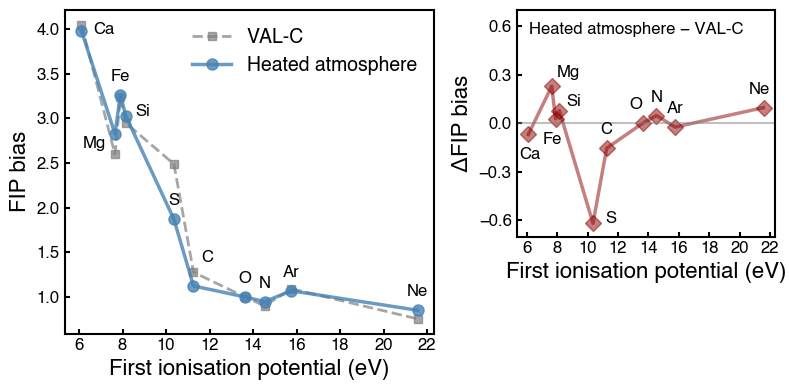

In [7]:
# To load and plot later:
import pickle
import matplotlib.pyplot as plt
import numpy as np

# Set default line thickness
plt.rcParams['lines.linewidth'] = 2.4
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1.5
plt.rcParams['ytick.minor.width'] = 1.5
plt.rcParams['grid.linewidth'] = 1.8

title_size=18
label_size=16
legend_size=14
tick_size=12
time_index = 700
time_index_0 = 0

# Load Alfven data for ionization fractions and FIP bias
frequency = 0.206
amplitude = 0.97
acoustic_flux = 1e8*u.erg/u.cm**2/u.s

with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/v_{frequency:.4f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}_F{acoustic_flux.value:.1e}.pkl', 'rb') as f:
    alfven_data = pickle.load(f)

# Load t=0 data - use frequency 0.198 and amplitude 0.45 which exists
frequency_t0 = 0.198
amplitude_t0 = 0.45
with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/v_{frequency_t0:.4f}_A_{amplitude_t0:.2f}/test_loop_extra_properties_{frequency_t0:.3f}_{amplitude_t0:.2f}_{time_index_0}_F{acoustic_flux.value:.1e}.pkl', 'rb') as f:
    alfven_data_t0 = pickle.load(f)

# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']
fip_bias_heights_t0 = alfven_data_t0['fip_bias_heights']
s_values = alfven_data['s_values']

# Target height for FIP bias extraction
target_height = 5.75e9  # in cm (as stored in the data)

# First ionization potentials (FIP) in eV for sorting
element_fip = {
    'Ca': 6.11, 'Mg': 7.65, 'Fe': 7.90, 'Si': 8.15,
    'S': 10.36, 'C': 11.26, 'N': 14.53, 'O': 13.62, 
    'Ar': 15.76, 'Ne': 21.56
}

# Get oxygen data for normalization (right footpoint) - t=700
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Get oxygen data for normalization (right footpoint) - t=0
oxygen_bias_right_t0 = None
oxygen_heights_right_t0 = None
if 'O' in fip_bias_heights_t0 and 'right' in fip_bias_heights_t0['O']:
    oxygen_heights_right_t0 = np.array(fip_bias_heights_t0['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right_t0 = np.array(fip_bias_heights_t0['O']['right']['bias'])

# Extract FIP bias at target height for each element - t=700
fip_bias_at_target = {}
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        
        # Normalize by oxygen
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            
            # Find the index closest to target height
            idx = np.argmin(np.abs(heights_right - target_height))
            fip_bias_at_target[element] = bias_right_normalized[idx]

# Extract FIP bias at target height for each element - t=0
fip_bias_at_target_t0 = {}
for element, data_fip in fip_bias_heights_t0.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        
        # Normalize by oxygen
        if oxygen_bias_right_t0 is not None and len(bias_right) == len(oxygen_bias_right_t0):
            bias_right_normalized = bias_right / oxygen_bias_right_t0
            
            # Find the index closest to target height
            idx = np.argmin(np.abs(heights_right - target_height))
            fip_bias_at_target_t0[element] = bias_right_normalized[idx]

# Sort elements by FIP
sorted_elements = sorted(fip_bias_at_target.keys(), key=lambda x: element_fip.get(x, 999))
sorted_fip_values = [fip_bias_at_target[el] for el in sorted_elements]
sorted_fip_values_t0 = [fip_bias_at_target_t0[el] for el in sorted_elements]

# Calculate the difference between the two atmospheres
sorted_fip_diff = [fip_bias_at_target[el] - fip_bias_at_target_t0[el] for el in sorted_elements]

# Create figure with two panels using gridspec for different heights
fig = plt.figure(figsize=(8, 4))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 0.7])

# Left panel - full height
ax = fig.add_subplot(gs[0])

# Right panel - 70% height, aligned to top
# Create a nested gridspec for the right side
gs_right = gs[1].subgridspec(2, 1, height_ratios=[0.7, 0.3], hspace=0)
ax_diff = fig.add_subplot(gs_right[0])

# Plot using FIP values (eV) as x-axis positions
x_positions = [element_fip[el] for el in sorted_elements]
ax.plot(x_positions, sorted_fip_values_t0, 's--', markersize=6, linewidth=2, color='grey', label='VAL-C', alpha=0.7)
ax.plot(x_positions, sorted_fip_values, 'o-', markersize=8, linewidth=2.5, color='steelblue', label='Heated atmosphere', alpha=0.8)

# Custom label offsets for each element to avoid overlapping with markers
# Format: (x_offset, y_offset) in points
label_offsets = {
    'Ca': (16, -2),    # Move below the marker
    'Mg': (-15, -10),    # Move to the left
    'Fe': (0, 10),     # Move above
    'Si': (12, 0),     # Move to the right
    'S': (0, 10),      # Move above
    'C': (10, 17),     # Move below
    'N': (0, 10),      # Move above
    'O': (0, 10),      # Move above
    'Ar': (0, 10),     # Move above
    'Ne': (0, 10),     # Move above
}

# Add element labels at each point with custom offsets
for i, el in enumerate(sorted_elements):
    offset = label_offsets.get(el, (0, 10))
    ax.annotate(el, (x_positions[i], sorted_fip_values[i]), textcoords="offset points", 
                xytext=offset, ha='center', fontsize=tick_size)

# Add horizontal line at FIP bias = 1
# ax.axhline(y=1, color='grey', linestyle='--', linewidth=1.5, alpha=0.7)

# Customize axes
ax.set_xlabel('First ionisation potential (eV)', fontsize=label_size)
ax.set_ylabel('FIP bias', fontsize=label_size)

# ax.set_title(f'Predicted FIP bias at s = {target_height/1e9:.2f} Mm', fontsize=title_size)
ax.tick_params(axis='both', labelsize=tick_size)

# Remove ticks on right and top spines
ax.tick_params(axis='both', which='both', top=False, right=False)

# Set x-axis ticks with increment of 2
ax.set_xticks(np.arange(6, max(x_positions) + 2, 2))

ax.legend(loc='best', fontsize=legend_size, frameon=False)
# ax.legend(loc='best', fontsize=legend_size, frameon=False, bbox_to_anchor=(0.37, 0.94))

# # Add panel label
# ax.text(0.05, 0.95, 'a', transform=ax.transAxes, 
#         fontsize=title_size, fontweight='bold', va='top', ha='left')

# Panel b: Difference between the two atmospheres
ax_diff.plot(x_positions, sorted_fip_diff, 'D-', markersize=8, linewidth=2.5, color='darkred', alpha=0.5)

# Add horizontal line at difference = 0
ax_diff.axhline(y=0, color='grey', linestyle='-', linewidth=1.5, alpha=0.5)

# Add element labels at each point
label_offsets_diff = {
    'Ca': (1, -18),
    'Mg': (12, 7),
    'Fe': (-2, -18),
    'Si': (10, 3),
    'S': (13, 0),
    'C': (0, 10),
    'N': (0, 10),
    'O': (-5, 10),
    'Ar': (0, 10),
    'Ne': (-3, 10),
}

for i, el in enumerate(sorted_elements):
    offset = label_offsets_diff.get(el, (0, 10))
    ax_diff.annotate(el, (x_positions[i], sorted_fip_diff[i]), textcoords="offset points", 
                     xytext=offset, ha='center', fontsize=tick_size)

# Customize axes
ax_diff.set_xlabel('First ionisation potential (eV)', fontsize=label_size)
ax_diff.set_ylabel('ΔFIP bias', fontsize=label_size)
ax_diff.text(0.05, 0.95, 'Heated atmosphere − VAL-C', transform=ax_diff.transAxes, 
             fontsize=tick_size, ha='left', va='top')

ax_diff.tick_params(axis='both', labelsize=tick_size)

# Remove ticks on right and top spines
ax_diff.tick_params(axis='both', which='both', top=False, right=False)

ax_diff.set_ylim(-0.7, 0.7)
# Set x-axis ticks with increment of 2
ax_diff.set_xticks(np.arange(6, max(x_positions) + 2, 2))
ax_diff.set_yticks([-0.6,-0.3,0,0.3,0.6])
# Add panel label
# ax_diff.text(0.05, 0.95, 'b', transform=ax_diff.transAxes, 
#              fontsize=title_size, fontweight='bold', va='top', ha='left')

plt.tight_layout()
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/fip_bias_by_element_{time_index}.png', dpi=400)
plt.show()


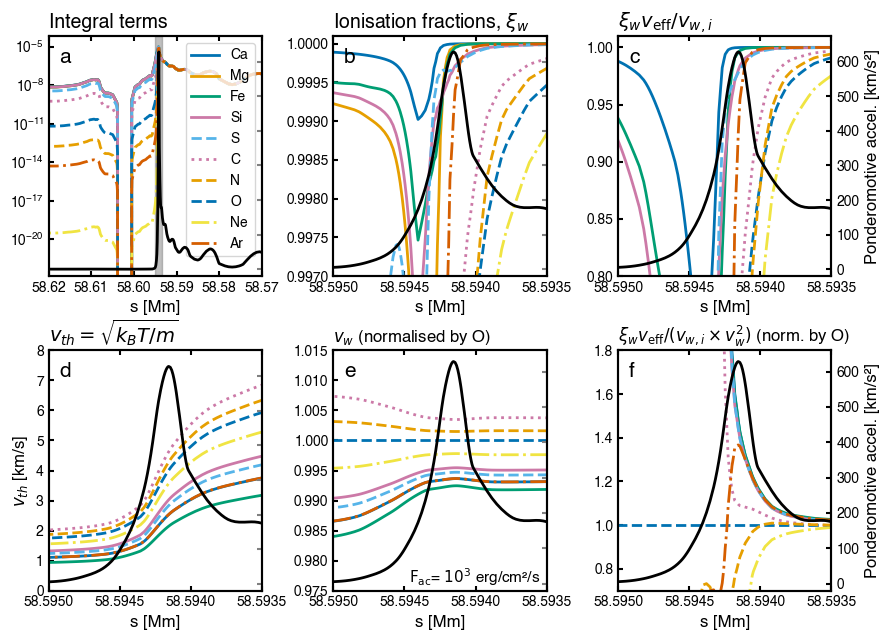

In [8]:
# Set plot parameters (matching your style)
plt.rcParams['lines.linewidth'] = 2.6
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1.5
plt.rcParams['ytick.minor.width'] = 1.5
plt.rcParams['grid.linewidth'] = 1.8


fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(9, 6.5))
title_location = 'left'
s_values_mm = alfven_data['s_values'].to(u.Mm).value
xmin, xmax = 58.62, 58.57
zoom_xmin, zoom_xmax = 58.5935, 58.595

# Panel a: Integral terms (shows the final result)
for element, collision_data in alfven_data['integral_terms'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax1.plot(s_values_mm, -collision_data, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax1.set_xlabel('s [Mm]', fontsize=12)
# ax1.set_ylabel('Integral', fontsize=12)
ax1.set_title('Integral terms', fontsize=14, loc=title_location)
ax1.legend(loc='best', fontsize=10, ncol=1, columnspacing=0.5)
ax1.set_yscale('log')
ax1.set_xlim(xmin, xmax)
ax1_twin = ax1.twinx()
ax1_twin.plot(s_values_mm, -alfven_data['ponderomotive_acceleration']/1e5, 
              linewidth=2, color='black', linestyle='-', alpha=1, zorder=1000)
ax1_twin.set_ylabel('', fontsize=12, color='grey')
ax1_twin.tick_params(axis='y', colors='grey')
ax1_twin.set_yticklabels([])
ax1_twin.set_ylim(bottom=-0.5)
ax1.text(0.05, 0.95, 'a', transform=ax1.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left')

# Panel b: Ionisation fractions (shows when elements ionize)
ionization_fractions = alfven_data['ionization_fractions']
for element, fractions in ionization_fractions.items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax2.plot(s_values_mm, fractions, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax2.set_xlabel('s [Mm]', fontsize=12)
ax2.set_ylabel('', fontsize=12)
ax2.set_title('Ionisation fractions, $\\xi_w$', fontsize=14, loc=title_location)
ax2.set_ylim(0.997, 1.0001 )
ax2.set_xlim(zoom_xmax,zoom_xmin, )
ax2.set_xticks([58.5935, 58.594, 58.5945, 58.595])
# ax2.set_xticklabels(['.5935', '.594', '.5945', '.595'])
ax2.text(0.05, 0.95, 'b', transform=ax2.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left')
ax2_twin = ax2.twinx()
ax2_twin.plot(s_values_mm, -alfven_data['ponderomotive_acceleration']/1e5, 
              linewidth=2, color='black', linestyle='-', alpha=1, zorder=1000)
ax2_twin.set_ylabel('', fontsize=12, color='grey')
ax2_twin.tick_params(axis='y', colors='grey')
ax2_twin.set_yticklabels([])
ax2_twin.set_ylim(bottom=-0.5)

# Panel d: Including thermal velocity (numerator × ξ)
for element in ['Ca', 'Fe', 'Si', 'S', 'O', 'C', 'Ar', 'Ne', 'N']:
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    collision_data = alfven_data['collision_frequencies'][element]
    ionization_fraction = alfven_data['ionization_fractions'][element]
    # Just the numerator part
    numerator = (collision_data.v_eff/collision_data.v_ion * ionization_fraction)
    ax3.plot(s_values_mm, numerator, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax3.set_xlabel('s [Mm]', fontsize=12)
# ax3.set_ylabel('Numerator', fontsize=12)
ax3.set_title(r'$\xi_w v_{\rm eff}/v_{w,i}$', fontsize=14, loc=title_location)
ax3.set_xlim(zoom_xmax,zoom_xmin, )
ax3.set_ylim(0.8, 1.01)
ax3_twin = ax3.twinx()
ax3_twin.plot(s_values_mm, -alfven_data['ponderomotive_acceleration']/1e5, 
              linewidth=2, color='black', linestyle='-', alpha=1, zorder=1000)
ax3_twin.set_ylim(bottom=-0.5)
ax3_twin.set_ylabel('Ponderomotive accel. [km/s²]', fontsize=12, color='k')
ax3_twin.tick_params(axis='y', colors='k')
ax3.text(0.05, 0.95, 'c', transform=ax3.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left')


# Panel c: Thermal speed contribution (KEY for mass dependence)
thermal_speed_squared = alfven_data['thermal_speed_squared']
for element in ['Ca', 'Fe', 'Si', 'S', 'O', 'C', 'Ar', 'Ne','N']:
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    # Plot just the thermal speed squared to show mass dependence
    thermal_term = np.sqrt(thermal_speed_squared[element]) / 1e5  # Convert to km/s
    ax4.plot(s_values_mm, thermal_term, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax4.set_xlabel('s [Mm]', fontsize=12)
ax4.set_ylabel(r'$v_{th}$ [km/s]', fontsize=12)
ax4.set_title(r'$v_{th} = \sqrt{k_B T/m}$', fontsize=14, loc=title_location)
ax4.set_xlim(zoom_xmax,zoom_xmin, )
ax4.set_ylim(0,8)
ax4.text(0.05, 0.95, 'd', transform=ax4.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left')
ax4_twin = ax4.twinx()
ax4_twin.plot(s_values_mm, -alfven_data['ponderomotive_acceleration']/1e5, 
              linewidth=2, color='black', linestyle='-', alpha=1, zorder=1000)
ax4_twin.set_ylabel('', fontsize=12, color='grey')
ax4_twin.tick_params(axis='y', colors='grey')
ax4_twin.set_yticklabels([])
ax4_twin.set_ylim(bottom=-0.5)


# Panel e: Full denominator with thermal speed, normalized by O
# First calculate v_eff for O
v_eff_squared_O = (thermal_speed_squared['O'] + 
                   alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2 +
                   alfven_data['sound_speed']['O']**2)
v_eff_O = np.sqrt(v_eff_squared_O) / 1e5  # Convert to km/s

for element in ['Ca', 'Fe', 'Si', 'S', 'O', 'C', 'Ar', 'Ne', 'N']:
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    # Total effective speed squared
    v_eff_squared = (thermal_speed_squared[element] + 
                     alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2 +
                     alfven_data['sound_speed'][element]**2)
    v_eff = np.sqrt(v_eff_squared) / 1e5  # Convert to km/s
    v_eff_normalized = v_eff / v_eff_O
    ax5.plot(s_values_mm, v_eff_normalized, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax5.set_ylim(0.975, 1.015)

ax5.set_xlabel('s [Mm]', fontsize=12)
ax5.set_ylabel(r'', fontsize=12)
ax5.set_title(r'$v_w$ (normalised by O)', fontsize=12, loc=title_location)
ax5.set_xlim(zoom_xmax,zoom_xmin)
ax5.text(0.05, 0.95, 'e', transform=ax5.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left')
ax5_twin = ax5.twinx()
ax5_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', alpha=1)
ax5_twin.set_ylabel('', fontsize=12, color='grey')
ax5_twin.tick_params(axis='y', colors='grey')
ax5_twin.set_yticklabels([])
ax5.text(0.97, 0.1, r'$\mathrm{F_{ac}}$= $10^3$ erg/cm²/s ', transform=ax5.transAxes, 
        fontsize=11, fontweight='bold', va='top', ha='right')



# Panel f: FIP bias normalized to O (the final fractionation)
collision_data_O = alfven_data['collision_frequencies']['O']
ionization_fraction_O = alfven_data['ionization_fractions']['O']
ratio_O = (collision_data_O.v_eff/collision_data_O.v_ion * ionization_fraction_O / 
           (thermal_speed_squared['O'] + alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2 +
           alfven_data['sound_speed'][element]**2))

for element in ['Ca', 'Fe', 'Si', 'S', 'O', 'C', 'Ar', 'Ne','N']:
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    collision_data = alfven_data['collision_frequencies'][element]
    ionization_fraction = alfven_data['ionization_fractions'][element]
    ratio = (collision_data.v_eff/collision_data.v_ion * ionization_fraction / 
             (thermal_speed_squared[element] + alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2 +
             alfven_data['sound_speed'][element]**2))
    ratio_normalized = ratio / ratio_O
    ax6.plot(s_values_mm, ratio_normalized, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax6.set_xlabel('s [Mm]', fontsize=12)
# ax6.set_ylabel('FIP bias (norm. by O)', fontsize=12)
ax6.set_title(r'$\xi_w v_\mathrm{eff}/(v_{w,i} \times v_{w}^2)$ (norm. by O)', fontsize=12, loc=title_location)
ax6.set_xlim(zoom_xmax,zoom_xmin, )
ax6.set_ylim(0.7, 1.8)
# ax6.set_yscale('log')
# ax6.legend(loc='best', fontsize=9, ncol=2, columnspacing=0.5)
ax6_twin = ax6.twinx()
ax6_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', alpha=1)
ax6_twin.set_ylabel('Ponderomotive accel. [km/s²]', fontsize=12, color='k')
ax6_twin.tick_params(axis='y', colors='k')
ax6.text(0.05, 0.95, 'f', transform=ax6.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left')

for ax in [ax1_twin, ax2_twin, ax3_twin, ax4_twin, ax5_twin, ax6_twin]:
    ax.set_ylim(bottom=-20)

# Disable scientific notation for x-axis on ax2-ax6
from matplotlib.ticker import ScalarFormatter
for ax in [ax2, ax3, ax4, ax5, ax6]:
    ax.xaxis.set_major_formatter(ScalarFormatter(useOffset=False))
    ax.ticklabel_format(style='plain', axis='x')

# Draw a box to indicate the zoom region
from matplotlib.patches import Rectangle
from matplotlib.patches import ConnectionPatch
ylim = ax1.get_ylim()
rect = Rectangle((zoom_xmax, ylim[0]), zoom_xmin - zoom_xmax, ylim[1] - ylim[0],
                 linewidth=1, edgecolor='grey', facecolor='grey', linestyle='-', zorder=-10, alpha=0.5)
ax1.add_patch(rect)

# Draw connection lines from rectangle on ax1 to top x axis of ax4
# Left corner connection
# con1 = ConnectionPatch(xyA=(zoom_xmax, ylim[0]), coordsA=ax1.transData,
#                        xyB=(zoom_xmax, ax4.get_ylim()[1]), coordsB=ax4.transData,
#                        color='grey', linestyle='-', linewidth=1.4,zorder=-10, alpha=0.5)
# fig.add_artist(con1)

# # Right corner connection
# con2 = ConnectionPatch(xyA=(zoom_xmin, ylim[0]), coordsA=ax1.transData,
#                        xyB=(zoom_xmin, ax4.get_ylim()[1]), coordsB=ax4.transData,
#                        color='grey', linestyle='-', linewidth=1.4,zorder=-10, alpha=0.5)
# fig.add_artist(con2)

plt.tight_layout(h_pad=0.1, w_pad=0.5)
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}_collision_frequencies_6panel.png', dpi=400)
plt.show()

/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.97/test_loop_extra_properties_0.206_0.97_700_F1.0e+08.pkl
Successfully loaded and plotted flux = 1e+08, amplitude = 0.97 km/s
/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.85/test_loop_extra_properties_0.206_0.85_700_F1.0e+07.pkl
Successfully loaded and plotted flux = 1e+07, amplitude = 0.85 km/s
/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.43/test_loop_extra_properties_0.206_0.43_700_F1.0e+06.pkl
Successfully loaded and plotted flux = 1e+06, amplitude = 0.43 km/s
/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.17/tes

/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_26719/3297282587.py:218: RuntimeWarning: overflow encountered in power
  return 10**amp_to_flux(x)
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_26719/3297282587.py:218: RuntimeWarning: overflow encountered in power
  return 10**amp_to_flux(x)


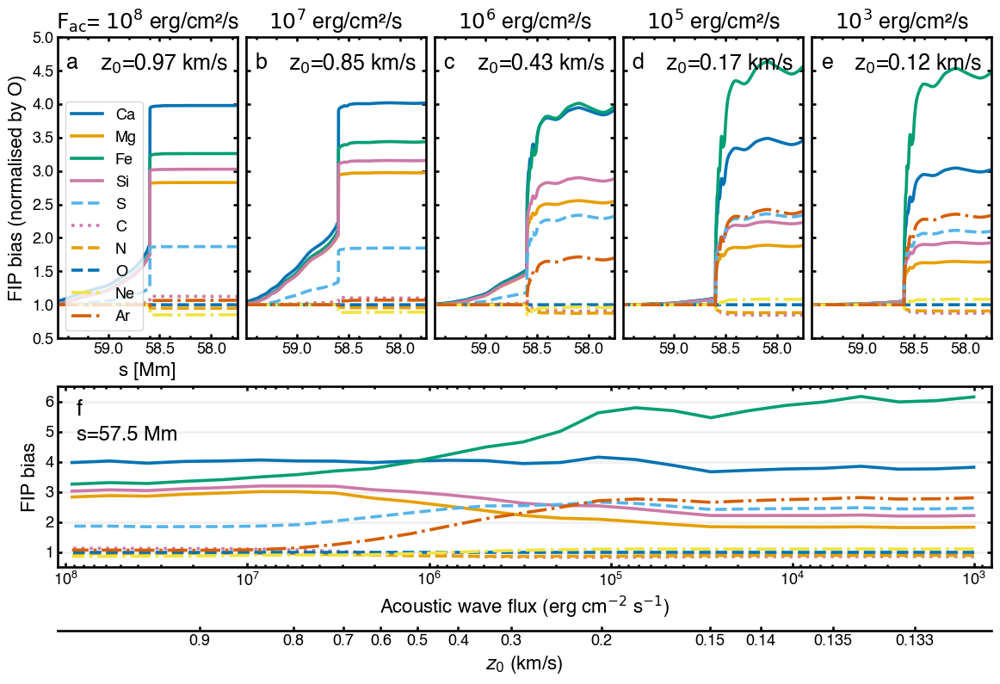


Plot saved to: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//fip_bias_flux_comparison_700.pdf


In [9]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from matplotlib.ticker import LogLocator, NullFormatter
import pandas as pd

# Set plot parameters (matching your style)
plt.rcParams['lines.linewidth'] = 2.6
plt.rcParams['axes.linewidth'] = 1.9
plt.rcParams['xtick.major.width'] = 1.9
plt.rcParams['ytick.major.width'] = 1.9
plt.rcParams['xtick.minor.width'] = 1.9
plt.rcParams['ytick.minor.width'] = 1.9
plt.rcParams['grid.linewidth'] = 1.8

linewidths = 2.6
title_size = 18
label_size = 16
legend_size = 13
tick_size = 13

# Define the flux values you simulated
acoustic_fluxes = [
    # 1e9,
    1e8,
    1e7,
    1e6,
    1e5,
    1e3,
]

# Corresponding amplitudes for each flux (from main_fip_bias_batch.py)
amplitudes = [0.97, 0.85,0.43,0.169476,0.123802]  # km/s

# Simulation parameters
frequency = 0.206
time_index = 700
base_path = '/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/'

# Element colors and linestyles (matching your existing plot)
# element_colors = {
#     'Ca': 'C0',  'Mg': 'C1',  'Fe': 'C2',  'Si': 'C3',
#     'O': 'C4',   'S': 'C5',   'Ar': 'C6',  'C': 'C7',  'Ne': 'C8',  'N': 'C9'
# }

# element_linestyles = {
#     'Ca': '-',   'Mg': '--',  'Fe': '-.',  'Si': ':',
#     'O': '-',    'S': '--',   'Ar': '-.',  'C': ':',  'Ne': '-',  'N': '--'
# }

# Create figure with 5 horizontal subplots on top and 1 wide subplot on bottom
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 5, height_ratios=[1, 0.6], hspace=0.2, wspace=0.05)

# Top row: 5 subplots for individual flux values
axes_top = [fig.add_subplot(gs[0, i]) for i in range(5)]

xmin = 5.95e9
xmax = 5.775e9
ax_xticks = [x*10 for x in [5.8e9, 5.85e9, 5.9e9]]

# Loop over each flux value
for idx, (flux, amplitude) in enumerate(zip(acoustic_fluxes, amplitudes)):
    ax = axes_top[idx]
    
    # Construct the file path
    flux_str = f'_F{flux:.1e}'
    file_path = f'{base_path}/v_{frequency:.4f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}{flux_str}.pkl'
    print(file_path)
    try:
        # Load the data
        with open(file_path, 'rb') as f:
            alfven_data = pickle.load(f)
        
        # Extract FIP bias data
        fip_bias_heights = alfven_data['fip_bias_heights']
        
        # Get oxygen data for normalization (right footpoint)
        oxygen_bias_right = None
        oxygen_heights_right = None
        if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
            oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9
            oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])
        
        # Plot right footpoint for each element (normalized by oxygen)
        for element, data_fip in fip_bias_heights.items():
            if 'right' in data_fip:
                heights_right = np.array(data_fip['right']['heights']) * 1e9
                bias_right = np.array(data_fip['right']['bias'])
                
                if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
                    bias_right_normalized = bias_right / oxygen_bias_right
                    color = element_colors.get(element, None)
                    linestyle = element_linestyles.get(element, '-')
                    ax.plot(heights_right, bias_right_normalized, label=f'{element}', 
                           linestyle=linestyle, color=color, linewidth=linewidths)
        
        # Format the subplot
        if idx == 0:
            ax.set_xlabel('s [Mm]', fontsize=label_size)
        else:
            ax.set_xlabel('')

        # ax.set_xlabel('s [Mm]', fontsize=label_size)
        # Format flux in scientific notation with superscript
        flux_mantissa = flux / 10**int(np.log10(flux))
        flux_exponent = int(np.log10(flux))
        flux_str = f'$10^{{{flux_exponent}}}$'
        if idx == 0:
            ax.set_title(fr'$\mathrm{{F_{{ac}}}}$= {flux_str} erg/cm²/s', fontsize=title_size)
        else:
            ax.set_title(fr'{flux_str} erg/cm²/s', fontsize=title_size)
        ax.set_ylim(0.5, 5)
        ax.invert_xaxis()
        ax.set_xscale('log')
        ax.tick_params(axis='both', labelsize=tick_size)
        
        # Set x-axis formatting
        ax.set_xlim(left=xmin*10, right=xmax*10)
        ax.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
        ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xticks(ax_xticks)
        ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
        
        # Remove y tick labels for all plots except idx=0
        if idx != 0:
            ax.set_yticklabels([])
        
        # Add legend to first subplot only
        if idx == 0:
            ax.set_ylabel('FIP bias (normalised by O)', fontsize=label_size)
            ax.legend(loc='lower left', fontsize=legend_size, ncol=1)
        
        # Add subplot label (left) and amplitude (right)
        ax.text(0.05, 0.95, f'{chr(97 + idx)}', transform=ax.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='left')
        ax.text(0.95, 0.95, fr'$\mathrm{{z_0}}$={amplitude:.2f} km/s', transform=ax.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='right')
        
        print(f"Successfully loaded and plotted flux = {flux:.0e}, amplitude = {amplitude:.2f} km/s")
        
    except FileNotFoundError:
        print(f"Warning: File not found for flux = {flux:.0e}, amplitude = {amplitude:.2f} km/s")
        print(f"  Expected path: {file_path}")
        ax.text(0.5, 0.5, f'Data not found\nF = {flux:.0e}', 
                ha='center', va='center', transform=ax.transAxes, fontsize=14)
        if idx == 0:
            ax.set_ylabel('FIP bias (normalised by O)', fontsize=label_size)
    except Exception as e:
        print(f"Error loading flux = {flux:.0e}, amplitude = {amplitude:.2f} km/s: {e}")
        ax.text(0.5, 0.5, f'Error loading data\nF = {flux:.0e}', 
                ha='center', va='center', transform=ax.transAxes, fontsize=14)

# Bottom row: Wide subplot for flux vs FIP bias
ax_bottom = fig.add_subplot(gs[1, :])

# Load the data for the bottom plot
data_path = '/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/optimized_flux_study/optimal_amplitudes_smooth.csv'
df = pd.read_csv(data_path)

# Sort by flux
df = df.sort_values('flux')

# Filter to only include flux up to 1e8
df = df[df['flux'] <= 1e8]

# Get flux and oxygen bias for normalization
flux = df['flux'].values
o_bias = df['bias_O'].values

# Elements to plot
elements = ['Ca', 'Mg', 'Fe', 'Si', 'S', 'C', 'N', 'O', 'Ne', 'Ar']

# Plot each element
for element in elements:
    col = f'bias_{element}'
    if col in df.columns:
        bias = df[col].values
        bias_normalized = bias / o_bias
        
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        
        ax_bottom.semilogx(flux, bias_normalized, 
                    label=element, 
                    linestyle=linestyle, 
                    color=color, 
                    linewidth=linewidths)

# Format the bottom subplot
ax_bottom.set_xlabel('Acoustic wave flux (erg cm$^{-2}$ s$^{-1}$)', fontsize=label_size)
ax_bottom.set_ylabel('FIP bias', fontsize=label_size)
ax_bottom.tick_params(axis='both', labelsize=tick_size)
ax_bottom.set_xlim(flux.max() * 1.2, flux.min() * 0.8, )
ax_bottom.set_ylim(0.5, 6.5)
ax_bottom.grid(True, alpha=0.2, axis='y')
ax_bottom.set_yticks([1,2,3,4,5,6])
# Add secondary x-axis for amplitude
from scipy.interpolate import interp1d

# Get amplitude data from dataframe (already sorted by flux)
flux_vals = df['flux'].values
amp_vals = df['amplitude'].values
# Create interpolation functions for flux <-> amplitude mapping
# Using log scale for flux since x-axis is logarithmic
flux_to_amp = interp1d(np.log10(flux_vals), amp_vals, kind='linear', fill_value='extrapolate')
amp_to_flux = interp1d(amp_vals, np.log10(flux_vals), kind='linear', fill_value='extrapolate')

# Define forward and inverse functions for secondary axis
def forward(x):
    """Convert flux to amplitude"""
    return flux_to_amp(np.log10(x))

def inverse(x):
    """Convert amplitude to flux"""
    return 10**amp_to_flux(x)

# Create secondary x-axis at bottom with linear scale
secax = ax_bottom.secondary_xaxis(-0.35, functions=(forward, inverse))
secax.set_xlabel('$z_0$ (km/s)', fontsize=label_size)
secax.tick_params(axis='x', labelsize=tick_size)

# Set specific tick locations for amplitude (linear scale)
amp_ticks = [0.133, 0.135, 0.14, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0,1.1]
amp_tick_labels = [f'{x:.3f}' if x <= 0.135 else (f'{x:.2f}' if x < 0.2 else f'{x:.1f}') for x in amp_ticks]
secax.set_xticks(amp_ticks)
secax.set_xticklabels(amp_tick_labels)

# Ensure the secondary axis limits match the primary axis
# This ensures all ticks are visible
secax.set_xlim(forward(ax_bottom.get_xlim()[0]), forward(ax_bottom.get_xlim()[1]))
# ax_bottom.legend(loc='upper center', fontsize=legend_size, ncol=len(elements))

# Add subplot label
ax_bottom.text(0.02, 0.93, 'f', transform=ax_bottom.transAxes, 
               fontsize=title_size, fontweight='bold', va='top', ha='left')
ax_bottom.text(0.02, 0.78, 's=57.5 Mm', transform=ax_bottom.transAxes, 
            fontsize=title_size-1, fontweight='bold', va='top', ha='left')

plt.savefig(f'{base_path}/fip_bias_flux_comparison_{time_index}.pdf', bbox_inches='tight', dpi=300)
plt.savefig(f'{base_path}/fip_bias_flux_comparison_{time_index}.png', bbox_inches='tight', dpi=400)
plt.show()

print(f"\nPlot saved to: {base_path}/fip_bias_flux_comparison_{time_index}.pdf")

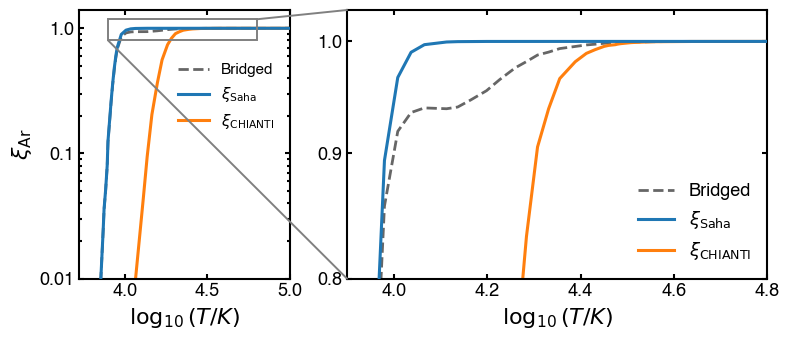

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from plasmapy.formulary.ionization import Saha
from physics.saha import get_element_transition_params, _adaptive_gaussian_smooth
from matplotlib.patches import Rectangle
from matplotlib.patches import ConnectionPatch

plt.rcParams['lines.linewidth'] = 2
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1.5
plt.rcParams['ytick.minor.width'] = 1.5
plt.rcParams['grid.linewidth'] = 1.8

atomic_data = {
    'Ca': {'ionization_energy': 6.1132*u.eV, 'g_i': 1, 'g_j': 2},
    'Mg': {'ionization_energy': 7.6462*u.eV, 'g_i': 1, 'g_j': 2},
    'Fe': {'ionization_energy': 7.9024*u.eV, 'g_i': 25, 'g_j': 30},
    'Si': {'ionization_energy': 8.1517*u.eV, 'g_i': 9, 'g_j': 6},
    'S':  {'ionization_energy': 10.3600*u.eV, 'g_i': 9, 'g_j': 4},
    'C':  {'ionization_energy': 11.2603*u.eV, 'g_i': 9, 'g_j': 6},
    'O':  {'ionization_energy': 13.6181*u.eV, 'g_i': 9, 'g_j': 4},
    'N':  {'ionization_energy': 14.5341*u.eV, 'g_i': 4, 'g_j': 9},
    'Ar': {'ionization_energy': 15.7568*u.eV, 'g_i': 1, 'g_j': 6},
    'Ne': {'ionization_energy': 21.5645*u.eV, 'g_i': 1, 'g_j': 6},
}

# Use the SAME arrays as the 9-panel plot
s_vals = alfven_data['s_values']                  # astropy Quantity in cm
T_vals = alfven_data['T'] * u.K if not hasattr(alfven_data['T'], 'unit') else alfven_data['T'].to(u.K)
ne_vals = alfven_data['ne'] * u.cm**-3 if not hasattr(alfven_data['ne'], 'unit') else alfven_data['ne'].to(u.cm**-3)

# Chromospheric mask (same xmin/xmax as your 9-panel zoom)
s_cm = s_vals.to(u.cm).value if hasattr(s_vals, 'unit') else s_vals
mask = (s_cm >= xmax) & (s_cm <= xmin)

s_raw = (s_vals[mask].to(u.Mm).value if hasattr(s_vals, 'unit')
         else s_vals[mask] / 1e8)
T_raw = T_vals[mask]
ne_raw = ne_vals[mask]
logT_raw = np.log10(T_raw.value)

chianti_file = np.load('chianti/ion_fraction_with_T.npz')

# Pick element -- use O, S, or C for visible bridge effect
element = 'Ar'
props = atomic_data[element]

# --- Saha (density-dependent) ---
xi_saha = Saha(props['g_i'], props['g_j'], ne_raw,
               props['ionization_energy'], T_raw)
xi_saha = 1.0 / (1.0 + 1.0 / np.array(xi_saha))
xi_saha = np.clip(xi_saha, 0.0, 1.0)

# --- CHIANTI (density-independent equilibrium) ---
xi_chianti = np.interp(T_raw.value,
                       chianti_file['temperature'],
                       chianti_file[f'{element}_ioneq'])
xi_chianti = np.clip(xi_chianti, 0.0, 1.0)

# --- Bridge (exact production formula from physics/saha.py) ---
trans_params = get_element_transition_params(element)
logT_trans = trans_params['logT_trans']
width_dex  = trans_params['width_dex']

weights = 0.5 * (1.0 + np.tanh((logT_raw - logT_trans) / width_dex))
eps = 1e-10
log_xi_bridge = ((1.0 - weights) * np.log10(xi_saha + eps)
                 + weights * np.log10(xi_chianti + eps))
xi_bridge = np.clip(10**log_xi_bridge, 0.0, 1.0)
xi_bridge = _adaptive_gaussian_smooth(
    xi_bridge, np.abs(np.gradient(T_raw.value)),
    base_sigma=0.5, max_sigma=2.0)
xi_bridge = np.clip(xi_bridge, 0.0, 1.0)

# --- Verify: production ionisation fraction from alfven_data ---
xi_production = alfven_data['ionization_fractions'][element][mask]

# --- Binned data for plotting ---
nbins = 500
bins = np.linspace(logT_raw.min(), logT_raw.max(), nbins + 1)
centers = 0.5 * (bins[:-1] + bins[1:])
dig = np.digitize(logT_raw, bins) - 1

def bmed(y):
    out = np.full(nbins, np.nan)
    for i in range(nbins):
        m = dig == i
        if np.any(m):
            out[i] = np.median(y[m])
    return out

vs = bmed(xi_saha)
vc = bmed(xi_chianti)
vb = bmed(xi_bridge)
ok = np.isfinite(vs) & np.isfinite(vc) & np.isfinite(vb)

# ===================== PLOT =====================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5), 
                                gridspec_kw={'width_ratios': [1, 2]})

# --- Left: Zoomed out view with broader y-range ---
ax1.plot(centers[ok], np.clip(vb[ok], eps, None),
         color='k', ls='--', lw=2.0, alpha=0.6, label='Bridged', zorder=1)
ax1.plot(centers[ok], np.clip(vs[ok], eps, None),
         color='tab:blue', ls='-', lw=2.2, label=r'$\xi_{\mathrm{Saha}}$', zorder=3)
ax1.plot(centers[ok], np.clip(vc[ok], eps, None),
         color='tab:orange', ls='-', lw=2.2, label=r'$\xi_{\mathrm{CHIANTI}}$', zorder=2)

# ax1.axvline(logT_trans, color='0.5', ls='--', lw=1.2)
# ax1.axvspan(logT_trans - 2*width_dex, logT_trans + 2*width_dex,
#             color='0.85', alpha=0.5)
ax1.set_xlabel(r'$\log_{10}(T/K)$',fontsize=label_size)
ax1.set_ylabel(fr'$\xi_\mathrm{{{element}}}$',fontsize=label_size)
ax1.set_yscale('log')
ax1.set_ylim(1e-2, 1.4)  # Broader y-range
ax1.legend(frameon=False, fontsize=legend_size-2, loc='lower right',bbox_to_anchor=(0.99, 0.5))
ax1.set_yticks([0.01,0.1,1.0])
ax1.set_yticklabels([0.01,0.1,1.0],fontsize=tick_size)
ax1.tick_params(axis='x', labelsize=tick_size)
ax1.set_xlim(logT_raw.min()+0.1, 5)
# ax1.set_title(f'{element}  (full range)')

# Define zoom region
zoom_logT_min = logT_trans - 0.6
zoom_logT_max = logT_trans + 0.3
zoom_xi_min = 0.8
zoom_xi_max = 1.03

# Draw rectangle on left panel to show zoom region
rect = Rectangle((zoom_logT_min, zoom_xi_min), 
                 zoom_logT_max - zoom_logT_min, 
                 zoom_xi_max - zoom_xi_min + 0.15,
                 linewidth=1.4, edgecolor='grey', facecolor='none', 
                 linestyle='-', zorder=10)
ax1.add_patch(rect)

# --- Right: Zoomed in view ---
ax2.plot(centers[ok], np.clip(vb[ok], eps, None),
         color='k', ls='--', lw=2.0, alpha=0.6, label='Bridged', zorder=1)
ax2.plot(centers[ok], np.clip(vs[ok], eps, None),
         color='tab:blue', ls='-', lw=2.2, label=r'$\xi_{\mathrm{Saha}}$', zorder=3)
ax2.plot(centers[ok], np.clip(vc[ok], eps, None),
         color='tab:orange', ls='-', lw=2.2, label=r'$\xi_{\mathrm{CHIANTI}}$', zorder=2)

# ax2.axvline(logT_trans, color='0.5', ls='--', lw=1.2)
# ax2.axvspan(logT_trans - 2*width_dex, logT_trans + 2*width_dex,
#             color='0.85', alpha=0.5)
ax2.set_xlabel(r'$\log_{10}(T/K)$',fontsize=label_size)
# ax2.set_ylabel(f'{element} ionisation fraction')
ax2.set_yscale('log')
ax2.set_xlim(zoom_logT_min, zoom_logT_max)
ax2.set_ylim(zoom_xi_min, zoom_xi_max)
ax2.legend(frameon=False, fontsize=legend_size,loc='lower right')
ax2.set_yticks([0.8,0.9,1.0])
ax2.set_yticklabels([0.8,0.9,1.0],fontsize=tick_size)
ax2.tick_params(axis='x', labelsize=tick_size)
# ax2.set_title(f'{element}  (zoomed transition region)')

# Draw connection lines from rectangle to zoomed panel
# Top-left corner
con1 = ConnectionPatch(xyA=(zoom_logT_max, zoom_xi_max+0.15), coordsA=ax1.transData,
                       xyB=(zoom_logT_min, zoom_xi_max), coordsB=ax2.transData,
                       color='grey', linestyle='-', linewidth=1.4)
fig.add_artist(con1)

# Bottom-left corner
con2 = ConnectionPatch(xyA=(zoom_logT_min, zoom_xi_min), coordsA=ax1.transData,
                       xyB=(zoom_logT_min, zoom_xi_min), coordsB=ax2.transData,
                       color='grey', linestyle='-', linewidth=1.4)
fig.add_artist(con2)

plt.tight_layout()
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/ionisation_fraction_illustration.png', dpi=400)
plt.show()

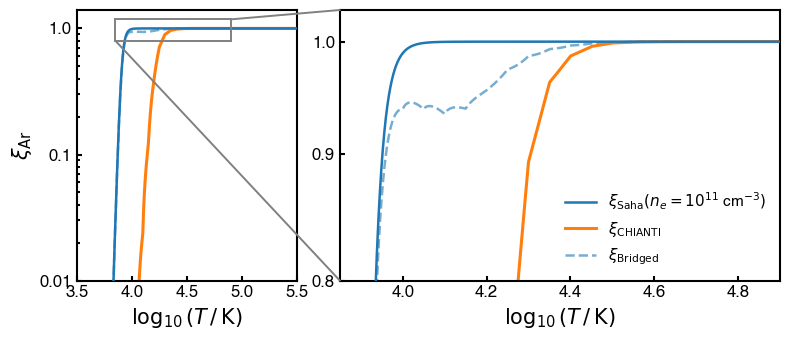

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from plasmapy.formulary.ionization import Saha
from physics.saha import get_element_transition_params, _adaptive_gaussian_smooth
from matplotlib.patches import Rectangle
from matplotlib.patches import ConnectionPatch

plt.rcParams['lines.linewidth'] = 2
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['xtick.major.width'] = 1.5
plt.rcParams['ytick.major.width'] = 1.5
plt.rcParams['xtick.minor.width'] = 1.5
plt.rcParams['ytick.minor.width'] = 1.5
plt.rcParams['grid.linewidth'] = 1.8

label_size = 15
legend_size = 12
tick_size = 12

atomic_data = {
    'Ca': {'ionization_energy': 6.1132*u.eV, 'g_i': 1, 'g_j': 2},
    'Mg': {'ionization_energy': 7.6462*u.eV, 'g_i': 1, 'g_j': 2},
    'Fe': {'ionization_energy': 7.9024*u.eV, 'g_i': 25, 'g_j': 30},
    'Si': {'ionization_energy': 8.1517*u.eV, 'g_i': 9, 'g_j': 6},
    'S':  {'ionization_energy': 10.3600*u.eV, 'g_i': 9, 'g_j': 4},
    'C':  {'ionization_energy': 11.2603*u.eV, 'g_i': 9, 'g_j': 6},
    'O':  {'ionization_energy': 13.6181*u.eV, 'g_i': 9, 'g_j': 4},
    'N':  {'ionization_energy': 14.5341*u.eV, 'g_i': 4, 'g_j': 9},
    'Ar': {'ionization_energy': 15.7568*u.eV, 'g_i': 1, 'g_j': 6},
    'Ne': {'ionization_energy': 21.5645*u.eV, 'g_i': 1, 'g_j': 6},
}

element = 'Ar'
props = atomic_data[element]

# --- Uniform temperature grid (no simulation data needed) ---
T_grid = np.logspace(3.5, 5.5, 5000) * u.K
logT_grid = np.log10(T_grid.value)

# --- Fixed densities to show sensitivity ---
ne_values = [1e11]
ne_colors = ['tab:blue']
ne_labels = [r'$n_e = 10^{11}$']

chianti_file = np.load('chianti/ion_fraction_with_T.npz')

# --- CHIANTI (density-independent) ---
xi_chianti = np.interp(T_grid.value,
                       chianti_file['temperature'],
                       chianti_file[f'{element}_ioneq'])
xi_chianti = np.clip(xi_chianti, 0.0, 1.0)

# --- Transition parameters ---
trans_params = get_element_transition_params(element)
logT_trans = trans_params['logT_trans']
width_dex  = trans_params['width_dex']

weights = 0.5 * (1.0 + np.tanh((logT_grid - logT_trans) / width_dex))
eps = 1e-10

# --- Compute Saha and bridged curves at each fixed density ---
saha_curves = []
bridge_curves = []
for ne_val in ne_values:
    ne_fixed = ne_val * u.cm**-3

    xi_saha = Saha(props['g_i'], props['g_j'], ne_fixed,
                   props['ionization_energy'], T_grid)
    xi_saha = 1.0 / (1.0 + 1.0 / np.array(xi_saha))
    xi_saha = np.clip(xi_saha, 0.0, 1.0)

    log_xi_bridge = ((1.0 - weights) * np.log10(xi_saha + eps)
                     + weights * np.log10(xi_chianti + eps))
    xi_bridge = np.clip(10**log_xi_bridge, 0.0, 1.0)

    saha_curves.append(xi_saha)
    bridge_curves.append(xi_bridge)

# ===================== PLOT =====================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5),
                                gridspec_kw={'width_ratios': [1, 2]})

# --- Left panel: full range ---
for xi_s, xi_b, col, lab in zip(saha_curves, bridge_curves,
                                 ne_colors, ne_labels):
    ax1.plot(logT_grid, np.clip(xi_s, eps, None),
             color=col, ls='-', lw=1.8, label=lab + r' (Saha)', zorder=3)
    ax1.plot(logT_grid, np.clip(xi_b, eps, None),
             color=col, ls='--', lw=1.8, alpha=0.6, zorder=1)

ax1.plot(logT_grid, np.clip(xi_chianti, eps, None),
         color='tab:orange', ls='-', lw=2.2,
         label=r'$\xi_{\mathrm{CHIANTI}}$', zorder=2)

ax1.set_xlabel(r'$\log_{10}(T\,/\,\mathrm{K})$', fontsize=label_size)
ax1.set_ylabel(fr'$\xi_\mathrm{{{element}}}$', fontsize=label_size)
ax1.set_yscale('log')
ax1.set_ylim(1e-2, 1.4)
ax1.set_xlim(3.5, 5.5)
ax1.set_yticks([0.01, 0.1, 1.0])
ax1.set_yticklabels([0.01, 0.1, 1.0], fontsize=tick_size)
ax1.tick_params(axis='x', labelsize=tick_size)
# ax1.legend(frameon=False, fontsize=legend_size - 3, loc='lower right',
#            bbox_to_anchor=(0.99, 0.35))

# Define zoom region
zoom_logT_min = logT_trans - 0.65
zoom_logT_max = logT_trans + 0.4
zoom_xi_min = 0.8
zoom_xi_max = 1.03

rect = Rectangle((zoom_logT_min, zoom_xi_min),
                 zoom_logT_max - zoom_logT_min,
                 zoom_xi_max - zoom_xi_min + 0.15,
                 linewidth=1.4, edgecolor='grey', facecolor='none',
                 linestyle='-', zorder=10)
ax1.add_patch(rect)

# --- Right panel: zoomed transition region ---
for xi_s, xi_b, col, lab in zip(saha_curves, bridge_curves,
                                 ne_colors, ne_labels):
    ax2.plot(logT_grid, np.clip(xi_s, eps, None),
             color=col, ls='-', lw=1.8, label=r'$\xi_{\mathrm{Saha}} ($'+lab+r' cm$^{-3})$', zorder=3)

ax2.plot(logT_grid, np.clip(xi_chianti, eps, None),
         color='tab:orange', ls='-', lw=2.2,
         label=r'$\xi_{\mathrm{CHIANTI}}$', zorder=2)
ax2.plot(logT_grid, np.clip(xi_b, eps, None),
            color=col, ls='--', lw=1.8, alpha=0.6,
            label=r'$\xi_{\mathrm{Bridged}}$', zorder=1)

ax2.set_xlabel(r'$\log_{10}(T\,/\,\mathrm{K})$', fontsize=label_size)
ax2.set_yscale('log')
ax2.set_xlim(zoom_logT_min, zoom_logT_max)
ax2.set_ylim(zoom_xi_min, zoom_xi_max)
ax2.set_yticks([0.8, 0.9, 1.0])
ax2.set_yticklabels([0.8, 0.9, 1.0], fontsize=tick_size)
ax2.tick_params(axis='x', labelsize=tick_size)
ax2.legend(frameon=False, fontsize=legend_size-1, loc='lower right')

# Connection lines between panels
con1 = ConnectionPatch(xyA=(zoom_logT_max, zoom_xi_max + 0.15), coordsA=ax1.transData,
                       xyB=(zoom_logT_min, zoom_xi_max), coordsB=ax2.transData,
                       color='grey', linestyle='-', linewidth=1.4)
fig.add_artist(con1)

con2 = ConnectionPatch(xyA=(zoom_logT_min, zoom_xi_min), coordsA=ax1.transData,
                       xyB=(zoom_logT_min, zoom_xi_min), coordsB=ax2.transData,
                       color='grey', linestyle='-', linewidth=1.4)
fig.add_artist(con2)

ax1.tick_params(axis='both', which='both', top=False, right=False)

ax2.tick_params(axis='both', which='both', top=False, right=False)


plt.tight_layout()
plt.savefig('/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/ionisation_fraction_illustration.png', dpi=400)
plt.show()

In [179]:
ax_bottom.get_xlim()[0]

np.float64(1200000000.0)

Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.97_F_1.0e08/test_loop_extra_properties_0.206_0.97_700_F1.0e+08_v_add_0.0.pkl
Successfully loaded and plotted v_add = 0.0 km/s
Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.97_F_1.0e08/test_loop_extra_properties_0.206_0.97_700_F1.0e+08_v_add_5.0.pkl
Successfully loaded and plotted v_add = 5.0 km/s
Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.97_F_1.0e08/test_loop_extra_properties_0.206_0.97_700_F1.0e+08_v_add_10.0.pkl
Successfully loaded and plotted v_add = 10.0 km/s
Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal

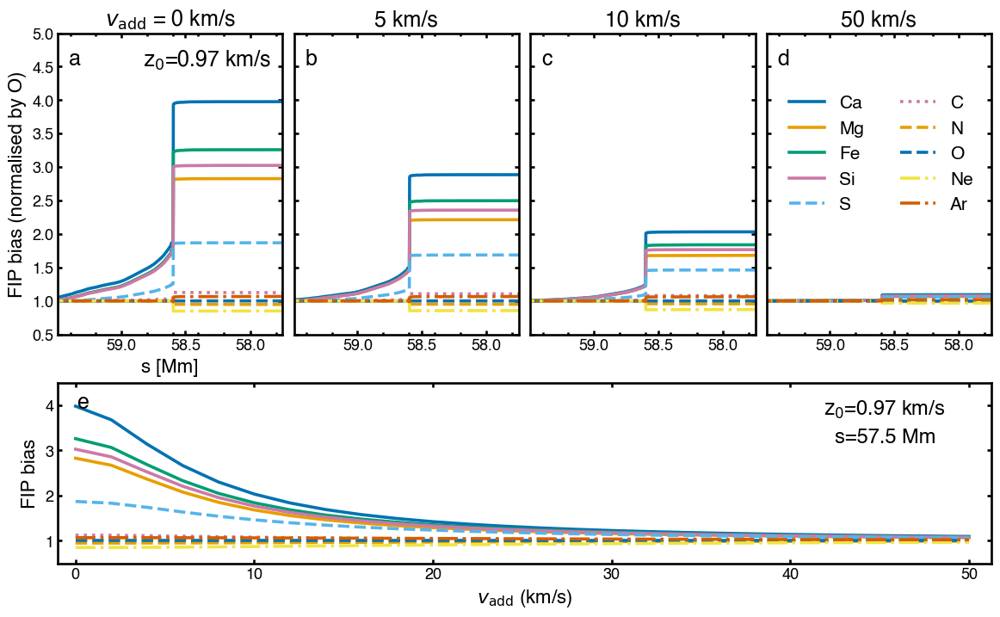


Plot saved to: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//fip_bias_v_add_comparison_700.pdf


In [12]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from matplotlib.ticker import LogLocator, NullFormatter
import pandas as pd

# Set plot parameters (matching your style)
plt.rcParams['lines.linewidth'] = 2.6
plt.rcParams['axes.linewidth'] = 1.9
plt.rcParams['xtick.major.width'] = 1.9
plt.rcParams['ytick.major.width'] = 1.9
plt.rcParams['xtick.minor.width'] = 1.9
plt.rcParams['ytick.minor.width'] = 1.9
plt.rcParams['grid.linewidth'] = 1.8

linewidths = 2.6
title_size = 18
label_size = 16
legend_size = 13
tick_size = 13

# Define the v_add values for top row subplots
v_add_values = [0.0, 5.0, 10.0, 50.0]

# Fixed simulation parameters
frequency = 0.206
amplitude = 0.97  # km/s - fixed
acoustic_flux = 1e8  # erg/cm²/s - fixed
time_index = 700
base_path = '/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/'

# Element colors and linestyles (matching your existing plot)
# element_colors = {
#     'Ca': 'C0',  'Mg': 'C1',  'Fe': 'C2',  'Si': 'C3',
#     'O': 'C4',   'S': 'C5',   'Ar': 'C6',  'C': 'C7',  'Ne': 'C8',  'N': 'C9'
# }

# element_linestyles = {
#     'Ca': '-',   'Mg': '--',  'Fe': '-.',  'Si': ':',
#     'O': '-',    'S': '--',   'Ar': '-.',  'C': ':',  'Ne': '-',  'N': '--'
# }

# Create figure with 4 horizontal subplots on top and 1 wide subplot on bottom
fig = plt.figure(figsize=(14, 8))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 0.6], hspace=0.2, wspace=0.05)

# Top row: 4 subplots for individual v_add values
axes_top = [fig.add_subplot(gs[0, i]) for i in range(4)]

xmin = 5.95e9
xmax = 5.775e9
ax_xticks = [x*10 for x in [5.8e9, 5.85e9, 5.9e9]]

# Loop over each v_add value
for idx, v_add in enumerate(v_add_values):
    ax = axes_top[idx]
    
    # Construct the file path based on your naming convention
    flux_str = f'F_{acoustic_flux:.1e}'.replace('+', '')
    dir_path = f'{base_path}/v_{frequency:.4f}_A_{amplitude:.2f}_{flux_str}'
    file_name = f'test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}_F{acoustic_flux:.1e}_v_add_{v_add:.1f}.pkl'
    file_path = f'{dir_path}/{file_name}'
    print(f"Looking for: {file_path}")
    
    try:
        # Load the data
        with open(file_path, 'rb') as f:
            alfven_data = pickle.load(f)
        
        # Extract FIP bias data
        fip_bias_heights = alfven_data['fip_bias_heights']
        
        # Get oxygen data for normalization (right footpoint)
        oxygen_bias_right = None
        oxygen_heights_right = None
        if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
            oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9
            oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])
        
        # Plot right footpoint for each element (normalized by oxygen)
        for element, data_fip in fip_bias_heights.items():
            if 'right' in data_fip:
                heights_right = np.array(data_fip['right']['heights']) * 1e9
                bias_right = np.array(data_fip['right']['bias'])
                
                if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
                    bias_right_normalized = bias_right / oxygen_bias_right
                    color = element_colors.get(element, None)
                    linestyle = element_linestyles.get(element, '-')
                    ax.plot(heights_right, bias_right_normalized, label=f'{element}', 
                           linestyle=linestyle, color=color, linewidth=linewidths)
        
        # Format the subplot
        if idx == 0:
            ax.set_xlabel('s [Mm]', fontsize=label_size)
        else:
            ax.set_xlabel('')

        # Format title with v_add value
        if idx == 0:
            ax.set_title(fr'$v_{{\mathrm{{add}}}}$ = {v_add:.0f} km/s', fontsize=title_size)
        else:
            ax.set_title(fr'{v_add:.0f} km/s', fontsize=title_size)
        
        ax.set_ylim(0.5, 5)
        ax.invert_xaxis()
        ax.set_xscale('log')
        ax.tick_params(axis='both', labelsize=tick_size)
        
        # Set x-axis formatting
        ax.set_xlim(left=xmin*10, right=xmax*10)
        ax.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
        ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xticks(ax_xticks)
        ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
        
        # Remove y tick labels for all plots except idx=0
        if idx != 0:
            ax.set_yticklabels([])
        
        # Add legend to first subplot only
        if idx == 0:
            ax.set_ylabel('FIP bias (normalised by O)', fontsize=label_size)
            ax.text(0.95, 0.95, fr'$\mathrm{{z_0}}$={amplitude:.2f} km/s', transform=ax.transAxes, 
                    fontsize=title_size, fontweight='bold', va='top', ha='right')

        if idx == 3:
            ax.legend(loc='lower right', fontsize=legend_size+2, ncol=2,frameon=False,bbox_to_anchor=(0.99, 0.35))
        
        # Add subplot label (left) and amplitude (right)
        ax.text(0.05, 0.95, f'{chr(97 + idx)}', transform=ax.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='left')
        
        print(f"Successfully loaded and plotted v_add = {v_add:.1f} km/s")
        
    except FileNotFoundError:
        print(f"Warning: File not found for v_add = {v_add:.1f} km/s")
        print(f"  Expected path: {file_path}")
        ax.text(0.5, 0.5, f'Data not found\n$v_{{add}}$ = {v_add:.1f} km/s', 
                ha='center', va='center', transform=ax.transAxes, fontsize=14)
        if idx == 0:
            ax.set_ylabel('FIP bias (normalised by O)', fontsize=label_size)
    except Exception as e:
        print(f"Error loading v_add = {v_add:.1f} km/s: {e}")
        ax.text(0.5, 0.5, f'Error loading data\n$v_{{add}}$ = {v_add:.1f} km/s', 
                ha='center', va='center', transform=ax.transAxes, fontsize=14)

# Bottom row: Wide subplot for v_add vs FIP bias
ax_bottom = fig.add_subplot(gs[1, :])

# Load the data for the bottom plot (from v_add study CSV)
data_path = '/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/v_add_study/v_add_study_results.csv'

try:
    df = pd.read_csv(data_path)
    
    # Sort by v_add
    df = df.sort_values('v_add')
    
    # Get v_add and oxygen bias for normalization
    v_add_arr = df['v_add'].values
    o_bias = df['bias_O'].values
    
    # Elements to plot
    elements = ['Ca', 'Mg', 'Fe', 'Si', 'S', 'C', 'N', 'O', 'Ne', 'Ar']
    
    # Plot each element
    for element in elements:
        col = f'bias_{element}'
        if col in df.columns:
            bias = df[col].values
            bias_normalized = bias / o_bias
            
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            
            ax_bottom.plot(v_add_arr, bias_normalized, 
                        label=element, 
                        linestyle=linestyle, 
                        color=color, 
                        linewidth=linewidths)
    
    # Format the bottom subplot
    ax_bottom.set_xlabel(r'$v_{\mathrm{add}}$ (km/s)', fontsize=label_size)
    ax_bottom.set_ylabel('FIP bias', fontsize=label_size)
    ax_bottom.tick_params(axis='both', labelsize=tick_size)
    ax_bottom.set_xlim(v_add_arr.min() - 1,v_add_arr.max() * 1.025, )  # Inverted to match top row
    ax_bottom.set_ylim(0.5, 4.5)
    # ax_bottom.grid(True, alpha=0.2, axis='y')
    ax_bottom.text(0.95, 0.91, fr'$\mathrm{{z_0}}$={amplitude:.2f} km/s', transform=ax_bottom.transAxes, 
               fontsize=title_size-1, fontweight='bold', va='top', ha='right')
    ax_bottom.text(0.94, 0.75, 's=57.5 Mm', transform=ax_bottom.transAxes, 
               fontsize=title_size-1, fontweight='bold', va='top', ha='right')

    # ax_bottom.text(0.95, 0.8, r'$F_{\mathrm{ac}}$=$10^8$ erg cm$^{-2}$ s$^{-1}$', transform=ax_bottom.transAxes,
    #     fontsize=title_size, fontweight='bold', va='top', ha='right')

except FileNotFoundError:
    print(f"Warning: CSV file not found at {data_path}")
    ax_bottom.text(0.5, 0.5, 'v_add study data not found', 
                   ha='center', va='center', transform=ax_bottom.transAxes, fontsize=14)

    ax_bottom.set_xlabel(r'$v_{\mathrm{add}}$ (km/s)', fontsize=label_size)
    ax_bottom.set_ylabel('FIP bias', fontsize=label_size)

# Add subplot label
ax_bottom.text(0.02, 0.95, 'e', transform=ax_bottom.transAxes, 
               fontsize=title_size, fontweight='bold', va='top', ha='left')

plt.savefig(f'{base_path}/fip_bias_v_add_comparison_{time_index}.pdf', bbox_inches='tight', dpi=300)
plt.savefig(f'{base_path}/fip_bias_v_add_comparison_{time_index}.png', bbox_inches='tight', dpi=400)
plt.show()

print(f"\nPlot saved to: {base_path}/fip_bias_v_add_comparison_{time_index}.pdf")

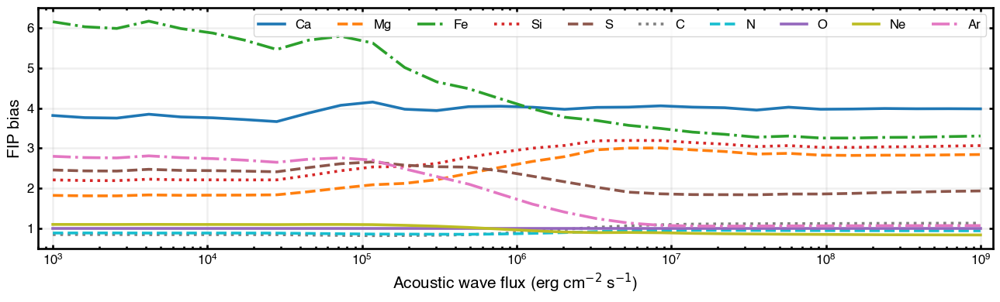

Plot saved to: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/optimized_flux_study//fip_bias_vs_flux_normalized_by_O.pdf


In [327]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set plot parameters (matching your style)
plt.rcParams['lines.linewidth'] = 2.6
plt.rcParams['axes.linewidth'] = 1.9
plt.rcParams['xtick.major.width'] = 1.9
plt.rcParams['ytick.major.width'] = 1.9
plt.rcParams['xtick.minor.width'] = 1.9
plt.rcParams['ytick.minor.width'] = 1.9
plt.rcParams['grid.linewidth'] = 1.8

linewidths = 2.6
title_size = 18
label_size = 15
legend_size = 12
tick_size = 12

# Load the data
data_path = '/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/optimized_flux_study/optimal_amplitudes_smooth.csv'
df = pd.read_csv(data_path)

# Sort by flux
df = df.sort_values('flux')

# Element colors and linestyles (matching your existing plot)
element_colors = {
    'Ca': 'C0',  'Mg': 'C1',  'Fe': 'C2',  'Si': 'C3',
    'O': 'C4',   'S': 'C5',   'Ar': 'C6',  'C': 'C7',  'Ne': 'C8',  'N': 'C9'
}

element_linestyles = {
    'Ca': '-',   'Mg': '--',  'Fe': '-.',  'Si': ':',
    'O': '-',    'S': '--',   'Ar': '-.',  'C': ':',  'Ne': '-',  'N': '--'
}

# Create figure
fig, ax = plt.subplots(figsize=(13, 4))

# Get flux and oxygen bias for normalization
flux = df['flux'].values
o_bias = df['bias_O'].values

# Elements to plot (excluding O since it will be 1 after normalization)
elements = ['Ca', 'Mg', 'Fe', 'Si', 'S', 'C', 'N', 'O', 'Ne', 'Ar']

# Plot each element
for element in elements:
    col = f'bias_{element}'
    if col in df.columns:
        bias = df[col].values
        bias_normalized = bias / o_bias
        
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        
        ax.semilogx(flux, bias_normalized, 
                    label=element, 
                    linestyle=linestyle, 
                    color=color, 
                    linewidth=linewidths)

# Add horizontal line at y=1 (oxygen reference)
# ax.axhline(y=1, color='gray', linestyle=':', linewidth=1.5, alpha=0.7, label='O (reference)')

# Add horizontal line at Ca/O = 4 target
# ax.axhline(y=4, color='red', linestyle='--', linewidth=1.5, alpha=0.5, label='Ca/O = 4 (target)')

# Format axes
ax.set_xlabel('Acoustic wave flux (erg cm$^{-2}$ s$^{-1}$)', fontsize=label_size)
ax.set_ylabel('FIP bias', fontsize=label_size)
# ax.set_title('FIP Bias vs Acoustic Wave Flux\n(Amplitude optimized for Ca/O = 4)', fontsize=title_size)

ax.tick_params(axis='both', labelsize=tick_size)
ax.set_xlim(flux.min() * 0.8, flux.max() * 1.2)
ax.set_ylim(0.5, 6.5)

ax.grid(True, alpha=0.2)
ax.legend(loc='upper right', fontsize=legend_size, ncol=len(elements))

plt.tight_layout()

# Save figure
save_path = '/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/optimized_flux_study/'
plt.savefig(f'{save_path}/fip_bias_vs_flux_normalized_by_O.pdf', bbox_inches='tight', dpi=300)
plt.savefig(f'{save_path}/fip_bias_vs_flux_normalized_by_O.png', bbox_inches='tight', dpi=300)
plt.show()

print(f"Plot saved to: {save_path}/fip_bias_vs_flux_normalized_by_O.pdf")

Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.97_F_1.0e08/test_loop_extra_properties_0.206_0.97_700_F1.0e+08_v_add_0.0.pkl
Successfully loaded and plotted v_add = 0.0 km/s
Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.97_F_1.0e08/test_loop_extra_properties_0.206_0.97_700_F1.0e+08_v_add_2.0.pkl
Successfully loaded and plotted v_add = 2.0 km/s
Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//v_0.2060_A_0.97_F_1.0e08/test_loop_extra_properties_0.206_0.97_700_F1.0e+08_v_add_5.0.pkl
Successfully loaded and plotted v_add = 5.0 km/s
Looking for: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_h

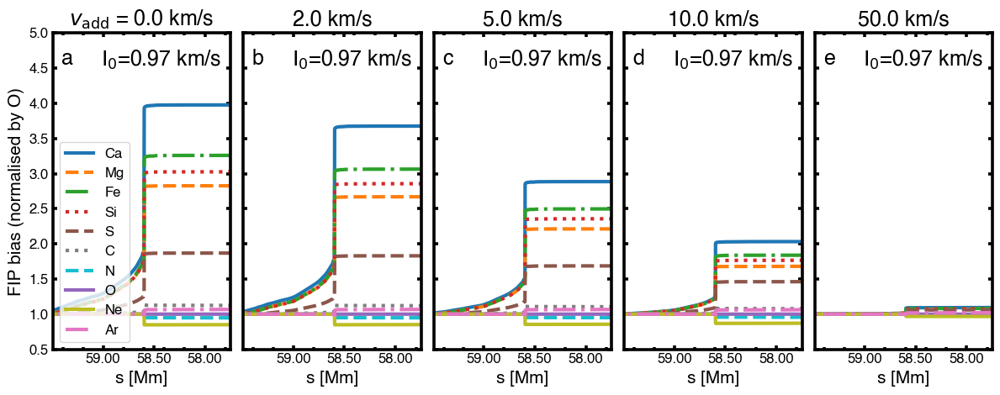


Plot saved to: /Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings//fip_bias_v_add_comparison_700.pdf


In [262]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from matplotlib.ticker import LogLocator, NullFormatter

# Set plot parameters (matching your style)
plt.rcParams['lines.linewidth'] = 2.6
plt.rcParams['axes.linewidth'] = 2.6
plt.rcParams['xtick.major.width'] = 2.6
plt.rcParams['ytick.major.width'] = 2.6
plt.rcParams['xtick.minor.width'] = 2.6
plt.rcParams['ytick.minor.width'] = 2.6
plt.rcParams['grid.linewidth'] = 2

linewidths = 3
title_size = 18
label_size = 15
legend_size = 12
tick_size = 12

# Define the v_add values you simulated (in km/s)
v_add_values = [
    0.0,
    # 1.0,
    2.0,
    5.0,
    10.0,
    # 20.0,
    50.0,
]

# Fixed simulation parameters
frequency = 0.206
amplitude = 0.97  # km/s - fixed
acoustic_flux = 1e8  # erg/cm²/s - fixed
time_index = 700
base_path = '/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/'

# Element colors and linestyles (matching your existing plot)
element_colors = {
    'Ca': 'C0',  'Mg': 'C1',  'Fe': 'C2',  'Si': 'C3',
    'O': 'C4',   'S': 'C5',   'Ar': 'C6',  'C': 'C7',  'Ne': 'C8',  'N': 'C9'
}

element_linestyles = {
    'Ca': '-',   'Mg': '--',  'Fe': '-.',  'Si': ':',
    'O': '-',    'S': '--',   'Ar': '-.',  'C': ':',  'Ne': '-',  'N': '--'
}

# Create figure with subplots for each v_add value
n_plots = len(v_add_values)
fig, axes = plt.subplots(1, n_plots, figsize=(12, 4.8), sharey=True)

# Handle single subplot case
if n_plots == 1:
    axes = [axes]

xmin = 5.95e9
xmax = 5.775e9
ax_xticks = [x*10 for x in [5.8e9, 5.85e9, 5.9e9]]

# Loop over each v_add value
for idx, v_add in enumerate(v_add_values):
    ax = axes[idx]
    
    # Construct the file path based on your naming convention
    flux_str = f'F_{acoustic_flux:.1e}'.replace('+', '')
    dir_path = f'{base_path}/v_{frequency:.4f}_A_{amplitude:.2f}_{flux_str}'
    file_name = f'test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}_F{acoustic_flux:.1e}_v_add_{v_add:.1f}.pkl'
    file_path = f'{dir_path}/{file_name}'
    print(f"Looking for: {file_path}")
    
    try:
        # Load the data
        with open(file_path, 'rb') as f:
            alfven_data = pickle.load(f)
        
        # Extract FIP bias data
        fip_bias_heights = alfven_data['fip_bias_heights']
        
        # Get oxygen data for normalization (right footpoint)
        oxygen_bias_right = None
        oxygen_heights_right = None
        if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
            oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9
            oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])
        
        # Plot right footpoint for each element (normalized by oxygen)
        for element, data_fip in fip_bias_heights.items():
            if 'right' in data_fip:
                heights_right = np.array(data_fip['right']['heights']) * 1e9
                bias_right = np.array(data_fip['right']['bias'])
                
                if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
                    bias_right_normalized = bias_right / oxygen_bias_right
                    color = element_colors.get(element, None)
                    linestyle = element_linestyles.get(element, '-')
                    ax.plot(heights_right, bias_right_normalized, label=f'{element}', 
                           linestyle=linestyle, color=color, linewidth=linewidths)
        
        # Format the subplot
        ax.set_xlabel('s [Mm]', fontsize=label_size)
        
        # Format title with v_add value
        if idx == 0:
            ax.set_title(fr'$v_{{\mathrm{{add}}}}$ = {v_add:.1f} km/s', fontsize=title_size)
        else:
            ax.set_title(fr'{v_add:.1f} km/s', fontsize=title_size)
        
        ax.set_ylim(0.5, 5)
        ax.invert_xaxis()
        ax.set_xscale('log')
        ax.tick_params(axis='both', labelsize=tick_size)
        
        # Set x-axis formatting
        ax.set_xlim(left=xmin*10, right=xmax*10)
        ax.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
        ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_xticks(ax_xticks)
        ax.set_xticklabels([f'{x/1e9:.2f}' for x in ax_xticks])
        
        # Add legend to first subplot only
        if idx == 0:
            ax.set_ylabel('FIP bias (normalised by O)', fontsize=label_size)
            ax.legend(loc='lower left', fontsize=legend_size, ncol=1)
        
        # Add subplot label (left) and v_add info (right)
        ax.text(0.05, 0.95, f'{chr(97 + idx)}', transform=ax.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='left')
        
        ax.text(0.95, 0.95, fr'$\mathrm{{I_0}}$={amplitude:.2f} km/s', transform=ax.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='right')
        
        print(f"Successfully loaded and plotted v_add = {v_add:.1f} km/s")
        
    except FileNotFoundError:
        print(f"Warning: File not found for v_add = {v_add:.1f} km/s")
        print(f"  Expected path: {file_path}")
        ax.text(0.5, 0.5, f'Data not found\n$v_{{add}}$ = {v_add:.1f} km/s', 
                ha='center', va='center', transform=ax.transAxes, fontsize=14)
        ax.set_xlabel('s [Mm]', fontsize=label_size)
        if idx == 0:
            ax.set_ylabel('FIP bias (normalised by O)', fontsize=label_size)
    except Exception as e:
        print(f"Error loading v_add = {v_add:.1f} km/s: {e}")
        ax.text(0.5, 0.5, f'Error loading data\n$v_{{add}}$ = {v_add:.1f} km/s', 
                ha='center', va='center', transform=ax.transAxes, fontsize=14)

# Add overall title (optional)
# fig.suptitle(f'FIP Bias vs Additional Turbulence (t={time_index}s, ν={frequency:.3f} Hz, F_ac={acoustic_flux:.0e} erg/cm²/s)', 
#              fontsize=title_size+2, y=0.98)

plt.tight_layout()
plt.savefig(f'{base_path}/fip_bias_v_add_comparison_{time_index}.pdf', bbox_inches='tight', dpi=300)
plt.savefig(f'{base_path}/fip_bias_v_add_comparison_{time_index}.png', bbox_inches='tight', dpi=300)
plt.show()

print(f"\nPlot saved to: {base_path}/fip_bias_v_add_comparison_{time_index}.pdf")

In [112]:
alfven_data.keys()

dict_keys(['s_values', 'I_plus', 'I_minus', 'delta_B_over_sqrt_4pi_rho', 'delta_v', 'flux_right', 'flux_left', 'normalized_flux_difference', 'ponderomotive_acceleration', 'acceleration_cm_s2', 'VA_s', 'ne', 'nh', 'h_ionisation', 'T', 'thermal_speed_squared', 'B', 'rho', 'collision_components_dict', 'slow_mode_velocity', 'sound_speed', 'acoustic_flux', 'v_add', 'fip_bias_heights', 'ionization_fractions', 'collision_frequencies', 'integral_terms', 'frequency', 'amplitude', 'loop_length'])

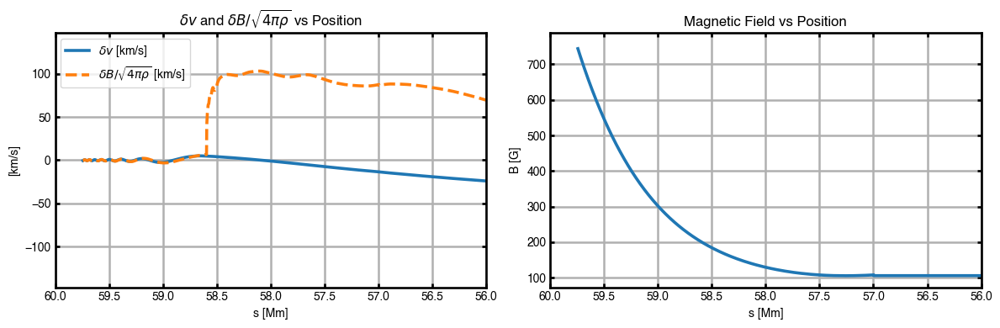

In [120]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left plot: delta_v and delta_B_over_sqrt_4pi_rho
ax1.plot(alfven_data['s_values']/1e8, alfven_data['delta_v']/1e5, label=r'$\delta v$ [km/s]')
ax1.plot(alfven_data['s_values']/1e8, alfven_data['delta_B_over_sqrt_4pi_rho']/1e5, 
         label=r'$\delta B / \sqrt{4\pi\rho}$ [km/s]', linestyle='--')
ax1.set_xlabel('s [Mm]')
ax1.set_ylabel('[km/s]')
ax1.set_title(r'$\delta v$ and $\delta B/\sqrt{4\pi\rho}$ vs Position')
ax1.set_xlim(60, 56)
ax1.grid(True)
ax1.legend(loc='best', fontsize=10)

# Right plot: B
ax2.plot(alfven_data['s_values']/1e8, alfven_data['B'])
ax2.set_xlabel('s [Mm]')
ax2.set_ylabel('B [G]')
ax2.set_title('Magnetic Field vs Position')
ax2.set_xlim(60, 56)
ax2.grid(True)

plt.tight_layout()
plt.show()

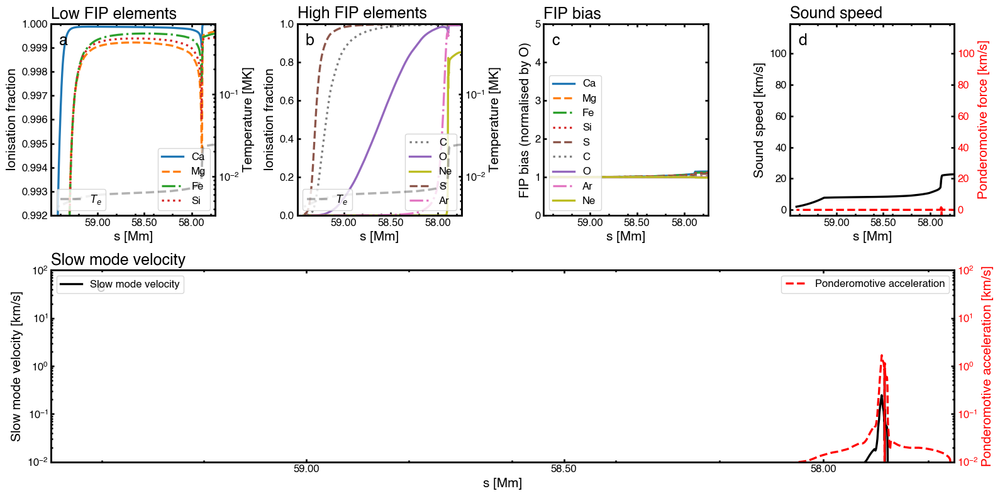

In [40]:
# Bottom row: Ionization fractions and temperature
s_values = alfven_data['s_values']
ionization_data = alfven_data['ionization_fractions']
temperature = alfven_data['T']

# Define consistent colors and line styles for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7',   # gray
    'Ne': 'C8'   # yellow
}

element_linestyles = {
    'Ca': '-',      # solid
    'Mg': '--',     # dashed
    'Fe': '-.',     # dash-dot
    'Si': ':',      # dotted
    'O': '-',       # solid
    'S': '--',      # dashed
    'Ar': '-.',     # dash-dot
    'C': ':',       # dotted
    'Ne': '-'       # solid
}

# Create figure with 5 subplots (4 in first row, 1 in second row)
fig = plt.figure(figsize=(16, 8))
gs = fig.add_gridspec(2, 4, height_ratios=[1, 1])

ax_ion_low = fig.add_subplot(gs[0, 0])
ax_ion_high = fig.add_subplot(gs[0, 1])
ax_fip = fig.add_subplot(gs[0, 2])
ax_sound = fig.add_subplot(gs[0, 3])
ax_slow = fig.add_subplot(gs[1, :])  # Span all columns in second row

ax10_xticks = [5.8e9, 5.85e9, 5.9e9]

# Plot 1: Ionization fraction - Low FIP elements (Ca, Mg, Fe, Si)
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
ax_temp_low = ax_ion_low.twinx()

for element in low_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_low.plot(s_values, ionization_data[element], label=element, 
                       color=color, linestyle=linestyle, linewidth=linewidths)

ax_temp_low.plot(s_values, temperature.to(u.MK).value, 
                 'k--', alpha=0.3, label='$T_e$')

ax_ion_low.set_ylabel('Ionisation fraction', fontsize=label_size)
ax_temp_low.set_ylabel('Temperature [MK]', color='k', fontsize=label_size)
ax_ion_low.set_xlabel('s [Mm]', fontsize=label_size)
ax_ion_low.set_title('Low FIP elements', fontsize=title_size, loc='left')
ax_ion_low.legend(loc='lower right', fontsize=legend_size)
ax_temp_low.legend(loc='lower left', fontsize=legend_size)
ax_ion_low.invert_xaxis()
ax_ion_low.set_xscale('log')
ax_temp_low.set_yscale('log')
ax_temp_low.tick_params(axis='y', labelcolor='k', labelsize=tick_size)
ax_ion_low.tick_params(axis='both', labelsize=tick_size)

from matplotlib.ticker import LogLocator, NullFormatter

ax_ion_low.set_xlim(left=xmin, right=xmax)
ax_ion_low.set_ylim(0.992, 1)
ax_ion_low.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_low.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_low.xaxis.set_minor_formatter(NullFormatter())
ax_ion_low.set_xticks(ax10_xticks)
ax_ion_low.set_xticklabels([f'{x/1e8:.2f}' for x in ax10_xticks])
ax_ion_low.text(0.05, 0.95, 'a', transform=ax_ion_low.transAxes, 
                fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot 2: Ionization fraction - High FIP elements (O, S, Ar, C)
high_fip_elements = ['C', 'O', 'Ne', 'S', 'Ar']
ax_temp_high = ax_ion_high.twinx()

for element in high_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_high.plot(s_values, ionization_data[element], label=element, 
                        color=color, linestyle=linestyle, linewidth=linewidths)

ax_temp_high.plot(s_values, temperature.to(u.MK).value, 
                  'k--', alpha=0.3, label='$T_e$')

ax_ion_high.set_ylabel('Ionisation fraction', fontsize=label_size)
ax_temp_high.set_ylabel('Temperature [MK]', color='k', fontsize=label_size)
ax_ion_high.set_xlabel('s [Mm]', fontsize=label_size)
ax_ion_high.set_title('High FIP elements', fontsize=title_size, loc='left')
ax_ion_high.legend(loc='lower right', fontsize=legend_size)
ax_temp_high.legend(loc='lower left', fontsize=legend_size)
ax_ion_high.invert_xaxis()
ax_ion_high.set_xscale('log')
ax_temp_high.set_yscale('log')
ax_temp_high.tick_params(axis='y', labelcolor='k', labelsize=tick_size)
ax_ion_high.tick_params(axis='both', labelsize=tick_size)
ax_ion_high.set_xlim(left=xmin, right=xmax)
ax_ion_high.set_ylim(0, 1)

ax_ion_high.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_high.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_high.xaxis.set_minor_formatter(NullFormatter())
ax_ion_high.set_xticks(ax10_xticks)
ax_ion_high.set_xticklabels([f'{x/1e8:.2f}' for x in ax10_xticks])
ax_ion_high.text(0.05, 0.95, 'b', transform=ax_ion_high.transAxes, 
                 fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot 3: FIP Bias Heights (normalized by O)
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Plot right footpoint for each element (normalized by oxygen)
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            ax_fip.plot(heights_right, bias_right_normalized, label=f'{element}', 
                       linestyle=linestyle, color=color, linewidth=linewidths)

ax_fip.set_xlabel('s [Mm]', fontsize=label_size)
ax_fip.set_ylabel('FIP bias (normalised by O)', fontsize=label_size)
ax_fip.set_title('FIP bias', fontsize=title_size, loc='left')
ax_fip.set_ylim(0, 5)
ax_fip.invert_xaxis()
ax_fip.set_xscale('log')
ax_fip.legend(loc='lower left', fontsize=legend_size, ncol=1)

ax_fip.set_xlim(left=xmin*10, right=xmax*10)
ax_fip.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_fip.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_fip.xaxis.set_minor_formatter(NullFormatter())
ax12_xticks = [x*10 for x in ax10_xticks]

ax_fip.set_xticks(ax12_xticks)
ax_fip.set_xticklabels([f'{x/1e9:.2f}' for x in ax12_xticks])
ax_fip.tick_params(axis='both', labelsize=tick_size)
ax_fip.text(0.05, 0.95, 'c', transform=ax_fip.transAxes, 
            fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Plot 4: Sound speed
sound_speed_data = alfven_data['sound_speed']
# Get sound speed from any element (it's not element dependent)
first_element = list(sound_speed_data.keys())[0]
sound_speed = sound_speed_data[first_element]

ax_sound.plot(s_values, sound_speed/1e5, 'k-', linewidth=linewidths, label='Sound speed')
ax_sound.set_xlabel('s [Mm]', fontsize=label_size)
ax_sound.set_ylabel('Sound speed [km/s]', fontsize=label_size)
ax_sound.set_title('Sound speed', fontsize=title_size, loc='left')
ax_sound.invert_xaxis()
ax_sound.set_xscale('log')
ax_sound.tick_params(axis='both', labelsize=tick_size)
# ax_sound.set_ylim(0,1)
ax_sound.set_xlim(left=xmin, right=xmax)
ax_sound.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_sound.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_sound.xaxis.set_minor_formatter(NullFormatter())
ax_sound.set_xticks(ax10_xticks)
ax_sound.set_xticklabels([f'{x/1e8:.2f}' for x in ax10_xticks])
ax_sound.text(0.05, 0.95, 'd', transform=ax_sound.transAxes, 
              fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Add ponderomotive force on twin axis with same y scale
ax_sound_twin = ax_sound.twinx()
ponderomotive_accel = alfven_data['ponderomotive_acceleration']
ax_sound_twin.plot(s_values, -ponderomotive_accel/1e5, 'r--', linewidth=linewidths, label='Ponderomotive force')
ax_sound_twin.set_ylabel('Ponderomotive force [km/s]', fontsize=label_size, color='r')
ax_sound_twin.tick_params(axis='y', labelcolor='r', labelsize=tick_size)
ax_sound_twin.set_ylim(ax_sound.get_ylim())

# Plot 5: Slow mode velocity
slow_mode_velocity = alfven_data['slow_mode_velocity']

ax_slow.plot(s_values, slow_mode_velocity.to(u.km/u.s).value, 'k-', linewidth=linewidths, label='Slow mode velocity')
ax_slow.set_xlabel('s [Mm]', fontsize=label_size)
ax_slow.set_ylabel('Slow mode velocity [km/s]', fontsize=label_size)
ax_slow.set_title('Slow mode velocity', fontsize=title_size, loc='left')
ax_slow.invert_xaxis()
ax_slow.set_xscale('log')
ax_slow.set_yscale('log')
ax_slow.set_ylim(1e-2, 1e2)
ax_slow.tick_params(axis='both', labelsize=tick_size)
ax_slow.set_xlim(left=xmin, right=xmax)
ax_slow.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_slow.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_slow.xaxis.set_minor_formatter(NullFormatter())
ax_slow.set_xticks(ax10_xticks)
ax_slow.set_xticklabels([f'{x/1e8:.2f}' for x in ax10_xticks])
ax_slow.text(0.05, 0.95, 'e', transform=ax_slow.transAxes, 
             fontsize=title_size, fontweight='bold', va='top', ha='left',)

# Add ponderomotive acceleration on twin axis
ax_slow_twin = ax_slow.twinx()
ax_slow_twin.plot(s_values, -ponderomotive_accel/1e5, 'r--', linewidth=linewidths, label='Ponderomotive acceleration')
ax_slow_twin.set_ylabel('Ponderomotive acceleration [km/s]', fontsize=label_size, color='r')
ax_slow_twin.set_ylim(ax_slow.get_ylim())
ax_slow_twin.set_yscale('log')
ax_slow_twin.tick_params(axis='y', labelcolor='r', labelsize=tick_size)

# Add legends for both axes
ax_slow.legend(loc='upper left', fontsize=legend_size)
ax_slow_twin.legend(loc='upper right', fontsize=legend_size)

plt.tight_layout()
plt.show()


In [846]:
alfven_data.keys()

dict_keys(['s_values', 'I_plus', 'I_minus', 'delta_B_over_sqrt_4pi_rho', 'delta_v', 'flux_right', 'flux_left', 'normalized_flux_difference', 'ponderomotive_acceleration', 'acceleration_cm_s2', 'VA_s', 'ne', 'nh', 'h_ionisation', 'T', 'thermal_speed_squared', 'B', 'rho', 'collision_components_dict', 'slow_mode_velocity', 'sound_speed', 'fip_bias_heights', 'ionization_fractions', 'collision_frequencies', 'integral_terms', 'frequency', 'amplitude', 'loop_length'])

In [847]:
alfven_data['slow_mode_velocity']

<Quantity [126.10954612, 126.10951008, 126.10947404, ...,  34.05011151,
            54.84775165,  99.80439662] cm / s>

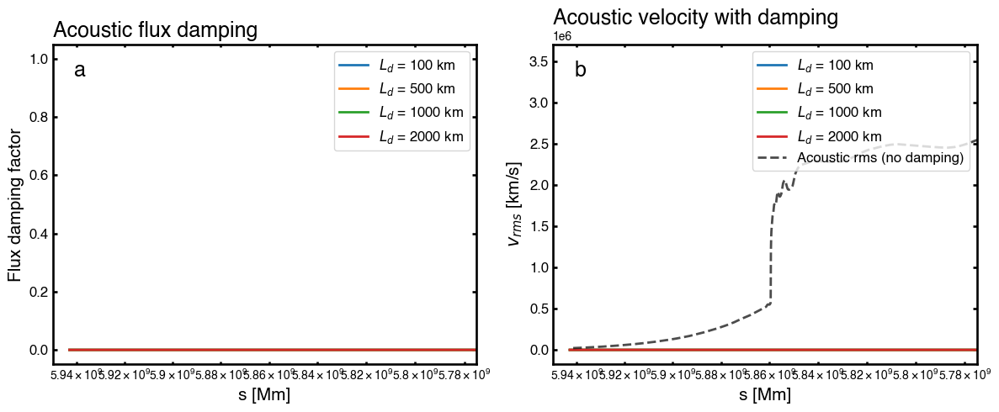

In [838]:
# Test acoustic damping visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Get the acoustic RMS data
sound_speed_data = alfven_data['sound_speed']
first_element = list(sound_speed_data.keys())[0]
sound_speed = sound_speed_data[first_element]

# Define different damping lengths to visualize
damping_lengths = [100, 500, 1000, 2000]  # km
colors_damp = ['C0', 'C1', 'C2', 'C3']

# Plot 1: Sound speed with damping models
for i, Ld in enumerate(damping_lengths):
    Ld_cm = Ld * 1e5  # Convert km to cm
    s_cm = s_values.to(u.cm).value
    z0_cm = s_cm[0]  # Start from first point
    
    # Calculate damped flux (exponential decay)
    flux_damped = np.exp(-(s_cm - z0_cm) / Ld_cm)
    
    ax1.plot(s_values, flux_damped, label=f'$L_d$ = {Ld} km', 
            color=colors_damp[i], linewidth=2)

ax1.set_xlabel('s [Mm]', fontsize=label_size)
ax1.set_ylabel('Flux damping factor', fontsize=label_size)
ax1.set_title('Acoustic flux damping', fontsize=title_size, loc='left')
ax1.legend(loc='upper right', fontsize=legend_size)
ax1.invert_xaxis()
ax1.set_xscale('log')
ax1.set_xlim(left=xmin, right=xmax)
ax1.tick_params(axis='both', labelsize=tick_size)
ax1.text(0.05, 0.95, 'a', transform=ax1.transAxes, 
        fontsize=title_size, fontweight='bold', va='top', ha='left')

# Plot 2: Effective v_rms with damping
# Assume constant photospheric flux for demonstration
flux_phot = 1e6  # erg/cm^2/s (typical value)
rho = alfven_data['rho'].to(u.g/u.cm**3).value
cs = alfven_data['sound_speed'][first_element]

for i, Ld in enumerate(damping_lengths):
    Ld_cm = Ld * 1e5
    s_cm = s_values.to(u.cm).value
    z0_cm = s_cm[0]
    
    # WKB approximation: v_rms^2 = F(z) / (rho * c_s)
    flux_z = flux_phot * np.exp(-(s_cm - z0_cm) / Ld_cm)
    v2 = flux_z / (rho * cs)
    v_rms = np.sqrt(np.clip(v2, 0, None)) / 1e5  # Convert to km/s
    
    ax2.plot(s_values, v_rms, label=f'$L_d$ = {Ld} km', 
            color=colors_damp[i], linewidth=2)

# Plot actual sound speed for comparison
ax2.plot(s_values, sound_speed, 'k--', label='Acoustic rms (no damping)', 
        linewidth=2, alpha=0.7)

ax2.set_xlabel('s [Mm]', fontsize=label_size)
ax2.set_ylabel('$v_{rms}$ [km/s]', fontsize=label_size)
ax2.set_title('Acoustic velocity with damping', fontsize=title_size, loc='left')
ax2.legend(loc='upper right', fontsize=legend_size)
ax2.invert_xaxis()
ax2.set_xscale('log')
ax2.set_xlim(left=xmin, right=xmax)
ax2.tick_params(axis='both', labelsize=tick_size)
ax2.text(0.05, 0.95, 'b', transform=ax2.transAxes, 
        fontsize=title_size, fontweight='bold', va='top', ha='left')

plt.tight_layout()
plt.show()


In [802]:
alfven_data['sound_speed']

{'Ca': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.74094377, 204395.16858494, 203089.95650507]),
 'Mg': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.74094377, 204395.16858494, 203089.95650507]),
 'Fe': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.74094377, 204395.16858494, 203089.95650507]),
 'Si': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.74094377, 204395.16858494, 203089.95650507]),
 'S': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.74094377, 204395.16858494, 203089.95650507]),
 'C': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.74094377, 204395.16858494, 203089.95650507]),
 'O': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.74094377, 204395.16858494, 203089.95650507]),
 'Ar': array([202086.2865254 , 202086.29058239, 202086.29463938, ...,
        205871.7

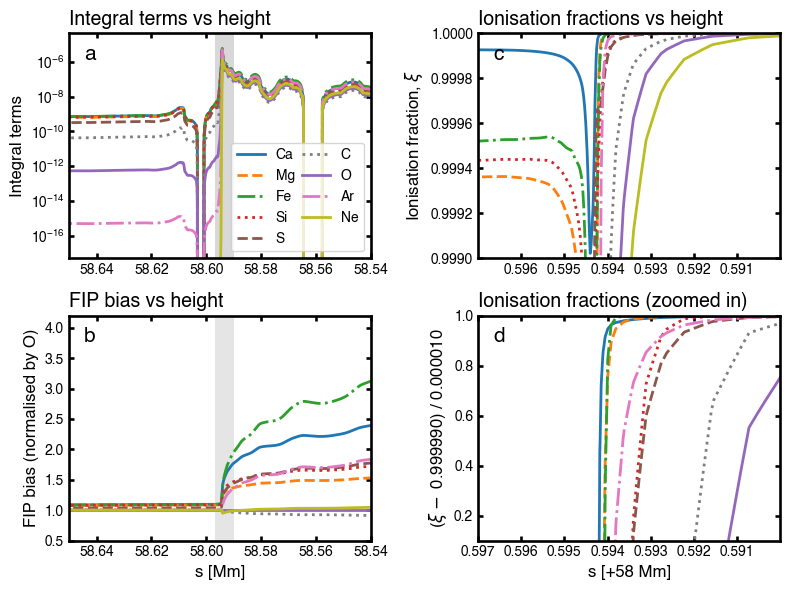

In [756]:
# Plot all integral terms on one plot vs height
fig, ((ax1, ax3), (ax2, ax4)) = plt.subplots(2, 2, figsize=(8, 6))
title_location = 'left'
fip_bias_heights = alfven_data['fip_bias_heights']
s_values_mm = alfven_data['s_values'].to(u.Mm).value
xmin, xmax = 58.65, 58.54

# First subplot: Integral terms
for element, values in alfven_data['integral_terms'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax1.plot(s_values_mm, -values, linewidth=2, label=element,
            color=color, linestyle=linestyle)

# ax1.set_xlabel('Height [Mm]', fontsize=12)
ax1.set_xlabel('', fontsize=12)
ax1.set_ylabel('Integral terms', fontsize=12)
ax1.set_title('Integral terms vs height', fontsize=14, loc=title_location)
ax1.legend(loc='lower right', fontsize=10, ncol=2, columnspacing=0.5)
# ax1.grid(True, alpha=0.3)
ax1.set_yscale('log')
# ax1.set_xlabel('')
ax1.set_ylim(bottom=5e-18)
ax1.set_xlim(xmin, xmax)

# Add a box at the specified region
from matplotlib.patches import Rectangle
box_left = 58.597
box_right = 58.59
box_bottom = ax1.get_ylim()[0]
box_top = ax1.get_ylim()[1]
box_width = box_left - box_right
box_height = box_top - box_bottom

rect = Rectangle((box_right, box_bottom), box_width, box_height, 
                linewidth=2, edgecolor='none', facecolor='grey', alpha=0.3)
ax1.add_patch(rect)

# Add subplot label (a)
ax1.text(0.05, 0.95, 'a', transform=ax1.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

# Second subplot: FIP bias
# Get oxygen FIP bias for normalization
oxygen_bias_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    heights_O = np.array(fip_bias_heights['O']['right']['heights'])  # Convert to cm
    bias_O = np.array(fip_bias_heights['O']['right']['bias'])
    heights_O_mm = heights_O  # Convert to Mm
    oxygen_bias_right = bias_O

# Plot FIP bias normalized by oxygen
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights'])   # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        heights_right_mm = heights_right  # Convert to Mm
        
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            ax2.plot(heights_right_mm, bias_right_normalized, 
                    label=f'{element}', linestyle=linestyle, color=color, 
                    linewidth=2, alpha=1)

ax2.set_xlabel('s [Mm]', fontsize=12)
ax2.set_ylabel('FIP bias (normalised by O)', fontsize=12)
ax2.set_title('FIP bias vs height', fontsize=14, loc=title_location)
# ax2.legend(loc='best', fontsize=10)
# ax2.grid(True, alpha=0.3)
ax2.set_ylim(0.5, 4.2)
ax2.set_xlim(xmin, xmax)

# Add a box at the specified region for FIP bias plot
rect2 = Rectangle((box_right, 0.5), box_width, 4.2-0.5, 
                linewidth=2, edgecolor='none', facecolor='grey', alpha=0.2)
ax2.add_patch(rect2)

# Add subplot label (b)
ax2.text(0.05, 0.95, 'b', transform=ax2.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

# Third subplot: Ionization fractions
ionization_fractions = alfven_data['ionization_fractions']
for element, fractions in ionization_fractions.items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax3.plot(s_values_mm, fractions, linewidth=2, label=element,
            color=color, linestyle=linestyle)

# ax3.set_xlabel('Height [+58 Mm]', fontsize=12)
ax3.set_xlabel('', fontsize=12)
ax3.set_ylabel('Ionisation fraction, $\\xi$', fontsize=12)
ax3.set_title('Ionisation fractions vs height', fontsize=14, loc=title_location)
# ax3.legend(loc='best', fontsize=10, ncol=2, columnspacing=0.5)
# ax3.grid(True, alpha=0.3)
ax3.set_ylim(0.999, 1)
ax3.set_xlim(box_left, box_right)
ax3.set_xticks([58.591, 58.592, 58.593, 58.594, 58.595, 58.596])
ax3.set_xticklabels([.591, .592, .593, .594, .595, .596])
# Add subplot label (c)
ax3.text(0.05, 0.95, 'c', transform=ax3.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

# Fourth subplot: Ionization fractions (offset for visibility)
ionization_fractions = alfven_data['ionization_fractions']
offset = 0.99999   # Offset to shift data down for better visualization
for element, fractions in ionization_fractions.items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax4.plot(s_values_mm, (fractions - offset)/(1-offset), linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax4.set_xlabel('s [+58 Mm]', fontsize=12)
ax4.set_ylabel(f'($\\xi -$ {offset:.6f}) / {1-offset:.6f}', fontsize=12)
ax4.set_title('Ionisation fractions (zoomed in)', fontsize=14, loc=title_location)
# ax3.legend(loc='best', fontsize=10, ncol=2, columnspacing=0.5)
# ax4.grid(True, alpha=0.3)
ax4.set_ylim(0.1, 1)
# ax3.set_yscale('log')
ax4.set_xlim(box_left, box_right)
ax4.set_xticks([58.591, 58.592, 58.593, 58.594, 58.595, 58.596, 58.597])
ax4.set_xticklabels([.591, .592, .593, .594, .595, .596, .597])
# Add subplot label (d)
ax4.text(0.05, 0.95, 'd', transform=ax4.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',
        )
plt.tight_layout()
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}_investigation.pdf')
plt.show()


In [ ]:
alfven_data.keys()

NameError: name 'slow_mode_velocity' is not defined

In [604]:
alfven_data['slow_mode_velocity']

<Quantity [3.03932989e+01, 2.83470251e+00, 3.25734218e+00, 1.83026176e+01,
           1.01211290e+01, 8.97185254e+00, 1.11911723e+01, 1.00742818e+01,
           9.73679465e+00, 8.88003547e+00, 9.08190422e+00, 1.27593533e+01,
           1.74533750e+01, 2.00500564e+01, 2.06774271e+01, 2.11524276e+01,
           2.13529988e+01, 2.05683843e+01, 1.92765956e+01, 1.81351527e+01,
           1.80854368e+01, 1.73269790e+01, 1.58291600e+01, 1.53689856e+01,
           1.41084213e+01, 1.34685760e+01, 1.41279022e+01, 1.56114487e+01,
           1.73739212e+01, 1.92875570e+01, 2.10777294e+01, 2.01091584e+01,
           2.11890162e+01, 2.62386369e+01, 3.29729555e+01, 2.70610613e+01,
           1.09733532e+01, 6.00038342e-01, 2.08642488e+01, 1.90294342e+01,
           8.72159561e+00, 1.90450741e+02, 6.88383221e+02, 7.58167243e+02,
           5.60263436e+02, 3.30084132e+02, 1.74234544e+02, 1.07734933e+02,
           7.57721816e+01, 5.80232500e+01, 4.10865069e+01, 2.96828651e+01,
           2.34487920e+01

In [494]:
alfven_data['acceleration_cm_s2']

<Quantity [ 5.80190805e+00,  3.63639889e+00,  3.43253378e+00,
            6.30826077e+00,  4.86831873e+00,  3.28394727e+00,
            4.23660934e+00,  4.71404578e+00,  5.27062527e+00,
            4.88828289e+00,  4.91015133e+00,  7.07852088e+00,
            1.08465980e+01,  1.40089887e+01,  1.50952895e+01,
            1.57549974e+01,  1.60205001e+01,  1.53070532e+01,
            1.39174000e+01,  1.20506096e+01,  1.06836333e+01,
            1.00218342e+01,  9.65943064e+00,  1.05839113e+01,
            1.10214187e+01,  1.14758505e+01,  1.24781990e+01,
            1.42477688e+01,  1.56412761e+01,  1.63745675e+01,
            1.68804740e+01,  1.57621524e+01,  1.61881888e+01,
            1.98276812e+01,  2.44341890e+01,  1.95890692e+01,
            9.01042104e+00, -1.80614407e+00, -1.50756878e+01,
           -1.16815308e+01,  1.83715007e+01,  2.03761843e+02,
            4.83669472e+02,  5.36367697e+02,  4.26633410e+02,
            2.83143529e+02,  1.51890558e+02,  9.48153127e+01,
        

In [692]:
alfven_data['integral_terms']

{'Ca': array([ 7.66586622e-11,  7.66586441e-11,  7.66586093e-11, ...,
        -1.49931187e-10, -1.44361094e-10, -1.41704485e-10]),
 'Mg': array([ 4.59921190e-11,  4.59921049e-11,  4.59920807e-11, ...,
        -9.76685219e-11, -9.32574416e-11, -9.07893746e-11]),
 'Fe': array([ 4.64413709e-11,  4.64413561e-11,  4.64413311e-11, ...,
        -9.99629759e-11, -9.53285501e-11, -9.26900178e-11]),
 'Si': array([ 4.19684751e-11,  4.19684614e-11,  4.19684385e-11, ...,
        -9.09865628e-11, -8.67131135e-11, -8.42594366e-11]),
 'S': array([ 3.62622058e-13,  3.62621874e-13,  3.62621610e-13, ...,
        -9.67658194e-13, -9.03635272e-13, -8.60761010e-13]),
 'C': array([ 1.78064479e-14,  1.78064384e-14,  1.78064250e-14, ...,
        -4.86161993e-14, -4.53335361e-14, -4.31167882e-14]),
 'O': array([ 4.72289982e-17,  4.72289697e-17,  4.72289309e-17, ...,
        -1.36864844e-16, -1.27167743e-16, -1.20491306e-16]),
 'Ar': array([ 1.96803623e-20,  1.96803525e-20,  1.96803384e-20, ...,
        -5.16471

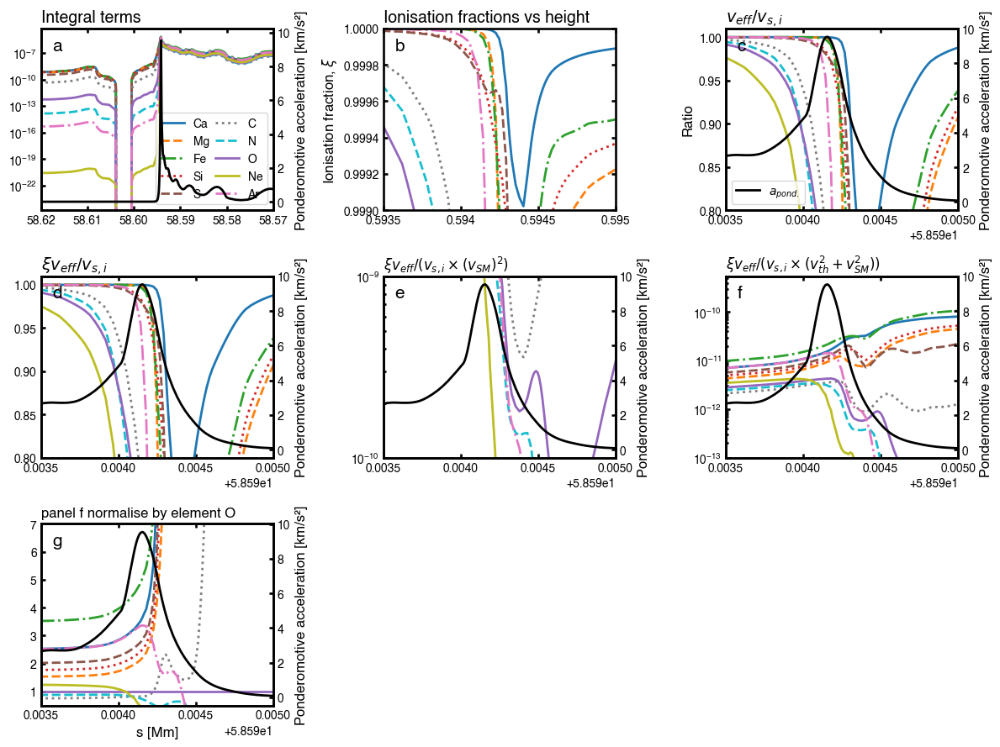

In [129]:
# Plot collision frequencies, neutral hydrogen density, and hydrogen ionization
fig, ((ax1, ax2, ax3), (ax4, ax5, ax6), (ax7, ax8, ax9)) = plt.subplots(3, 3, figsize=(12, 9))
title_location = 'left'
s_values_mm = alfven_data['s_values'].to(u.Mm).value
xmin, xmax = 58.62, 58.57

# First subplot: Ion collision frequencies
for element, collision_data in alfven_data['integral_terms'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax1.plot(s_values_mm, -collision_data, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax1.set_xlabel('', fontsize=12)
ax1.set_ylabel('', fontsize=12)
ax1.set_title('Integral terms', fontsize=14, loc=title_location)
ax1.legend(loc='best', fontsize=10, ncol=2, columnspacing=0.5)
ax1.set_yscale('log')
ax1.set_xlim(xmin, xmax)
ax1_twin = ax1.twinx()
ax1_twin.plot(s_values_mm, -alfven_data['ponderomotive_acceleration']/1e5, 
              linewidth=2, color='black', linestyle='-', label='Ponderomotive accel.',alpha=1,zorder=-1)
ax1_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
ax1_twin.set_ylim(bottom=-0.5)


# Add subplot label (a)
ax1.text(0.05, 0.95, 'a', transform=ax1.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

ax5_6_xmin, ax5_6_xmax = 58.5935, 58.595

# Second subplot: Ionisation fractions (zoomed)
ionization_fractions = alfven_data['ionization_fractions']
for element, fractions in ionization_fractions.items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax2.plot(s_values_mm, fractions, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax2.set_xlabel('', fontsize=12)
ax2.set_ylabel('Ionisation fraction, $\\xi$', fontsize=12)
ax2.set_title('Ionisation fractions vs height', fontsize=14, loc=title_location)
# ax2.legend(loc='best', fontsize=10, ncol=2, columnspacing=0.5)
# ax2.grid(True, alpha=0.3)
ax2.set_ylim(0.999, 1)
ax2.set_xlim(ax5_6_xmin, ax5_6_xmax)
ax2.set_xticks([58.5935, 58.594, 58.5945, 58.595])
ax2.set_xticklabels([.5935, .594, .5945, .595])
# Add subplot label (b)
ax2.text(0.05, 0.95, 'b', transform=ax2.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

# Third subplot: Neutral collision frequencies
for element, collision_data in alfven_data['collision_frequencies'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ax3.plot(s_values_mm, collision_data.v_eff/collision_data.v_ion, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax3.set_xlabel('', fontsize=12)
ax3.set_ylabel('Ratio', fontsize=12)
ax3.set_title(r'$v_{eff}/v_{s,i}$', fontsize=14, loc=title_location)
# ax3.set_yscale('log')
ax3.set_xlim(xmin, xmax)
ax3.set_xlim(ax5_6_xmin, ax5_6_xmax)
ax3.set_ylim(0.8,1.01)

# Add ponderomotive acceleration on twinx
ax3_twin = ax3.twinx()
ax3_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', label=r'$a_{pond.}$')
ax3_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
ax3_twin.legend(loc='lower left', fontsize=10, ncol=1, columnspacing=0.5)

# Add subplot label (c)
ax3.text(0.05, 0.95, 'c', transform=ax3.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

# Fourth subplot: Effective collision frequencies
for element, collision_data in alfven_data['collision_frequencies'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    ionization_fraction = alfven_data['ionization_fractions'][element]
    ax4.plot(s_values_mm, collision_data.v_eff/collision_data.v_ion * ionization_fraction, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax4.set_xlabel('', fontsize=12)
# ax4.set_ylabel('Effective collision frequency [Hz]', fontsize=12)
ax4.set_title(r'$\xi v_{eff}/v_{s,i}$', fontsize=14, loc=title_location)
# ax4.set_yscale('log')
# ax4.set_xlim(xmin, xmax)
ax4.set_xlim(ax5_6_xmin, ax5_6_xmax)
# Add subplot label (d)
ax4.text(0.05, 0.95, 'd', transform=ax4.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)
ax4_twin = ax4.twinx()
ax4_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', label='Ponderomotive accel.',alpha=1)
ax4_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
ax4.set_ylim(0.8,1.01)

# Fifth subplot: Collision frequency ratio with thermal speed

thermal_speed_squared = alfven_data['thermal_speed_squared']
for element, ionization_fraction in alfven_data['ionization_fractions'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    collision_data = alfven_data['collision_frequencies'][element]
    ratio = collision_data.v_eff/collision_data.v_ion * ionization_fraction / (alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2)
    ax5.plot(s_values_mm, ratio, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax5.set_xlabel('', fontsize=12)
ax5.set_xlim(ax5_6_xmin, ax5_6_xmax)
ax5.set_title(r'$\xi v_{eff}/(v_{s,i} \times (v_{SM})^2)$', fontsize=12, loc=title_location)
# ax5.set_title('Collision frequency ratio / thermal speed²', fontsize=14, loc=title_location)
# ax5.set_xlim(xmin, xmax)
ax5.set_ylim(bottom=1e-10,top=1e-9)

ax5.set_yscale('log')

# Add subplot label (e)
ax5.text(0.05, 0.95, 'e', transform=ax5.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)
ax5_twin = ax5.twinx()
ax5_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', label='Ponderomotive accel.',alpha=1)
ax5_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
# Sixth subplot: Same as ax5
for element, ionization_fraction in alfven_data['ionization_fractions'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    collision_data = alfven_data['collision_frequencies'][element]
    ratio = collision_data.v_eff/collision_data.v_ion * ionization_fraction / (thermal_speed_squared[element]+alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2)
    ax6.plot(s_values_mm, ratio, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax6.set_xlabel('', fontsize=12)
ax6.set_title(r'$\xi v_{eff}/(v_{s,i} \times (v_{th}^2+v_{SM}^2))$', fontsize=12, loc=title_location)
ax6.set_xlim(xmin, xmax)
ax6.set_yscale('log')

ax6.set_xlim(ax5_6_xmin, ax5_6_xmax)
ax6.set_ylim(bottom=1e-13)

# Add subplot label (f)
ax6.text(0.05, 0.95, 'f', transform=ax6.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)
ax6_twin = ax6.twinx()
ax6_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', label='Ponderomotive accel.',alpha=1)
ax6_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
# ax6_twin.set_ylim(top=0.7e6)

# Seventh subplot: Ratio of element collision frequency to C collision frequency
# Calculate C ratio for reference
collision_data_C = alfven_data['collision_frequencies']['O']
ionization_fraction_C = alfven_data['ionization_fractions']['O']
ratio_C = collision_data_C.v_eff/collision_data_C.v_ion * ionization_fraction_C / (thermal_speed_squared['O']+alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2)

for element, ionization_fraction in alfven_data['ionization_fractions'].items():
    # if element == 'O':
    #     continue  # Skip C itself
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    collision_data = alfven_data['collision_frequencies'][element]
    ratio = collision_data.v_eff/collision_data.v_ion * ionization_fraction / (thermal_speed_squared[element]+alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2)
    ratio_normalized = ratio / ratio_C
    ax7.plot(s_values_mm, ratio_normalized, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax7.set_xlabel('s [Mm]', fontsize=12)
ax7.set_title(r'panel f normalise by element O', fontsize=12, loc=title_location)
ax7.set_xlim(xmin, xmax)
# ax7.set_yscale('log')
ax7.set_xlim(ax5_6_xmin, ax5_6_xmax)
ax7.set_ylim(5e-1,7)
ax7_twin = ax7.twinx()
ax7_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', label='Ponderomotive accel.',alpha=1)
ax7_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)

# Add subplot label (g)
ax7.text(0.05, 0.95, 'g', transform=ax7.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

# Hide ax8 and ax9 (empty subplots)
ax8.axis('off')
ax9.axis('off')

plt.tight_layout()
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}_collision_frequencies.pdf')
plt.show()


In [179]:
alfven_data.keys()

dict_keys(['s_values', 'I_plus', 'I_minus', 'delta_B_over_sqrt_4pi_rho', 'delta_v', 'flux_right', 'flux_left', 'normalized_flux_difference', 'ponderomotive_acceleration', 'acceleration_cm_s2', 'VA_s', 'ne', 'nh', 'h_ionisation', 'T', 'thermal_speed_squared', 'B', 'rho', 'collision_components_dict', 'slow_mode_velocity', 'sound_speed', 'acoustic_flux', 'fip_bias_heights', 'ionization_fractions', 'collision_frequencies', 'integral_terms', 'frequency', 'amplitude', 'loop_length'])

In [231]:
alfven_data['sound_speed']

{'Ca': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'Mg': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'Fe': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'Si': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'S': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'C': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'N': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'O': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142.67616004]),
 'Ne': array([140.31481464, 140.31481581, 140.31481698, ..., 143.76251666,
        142.93236191, 142

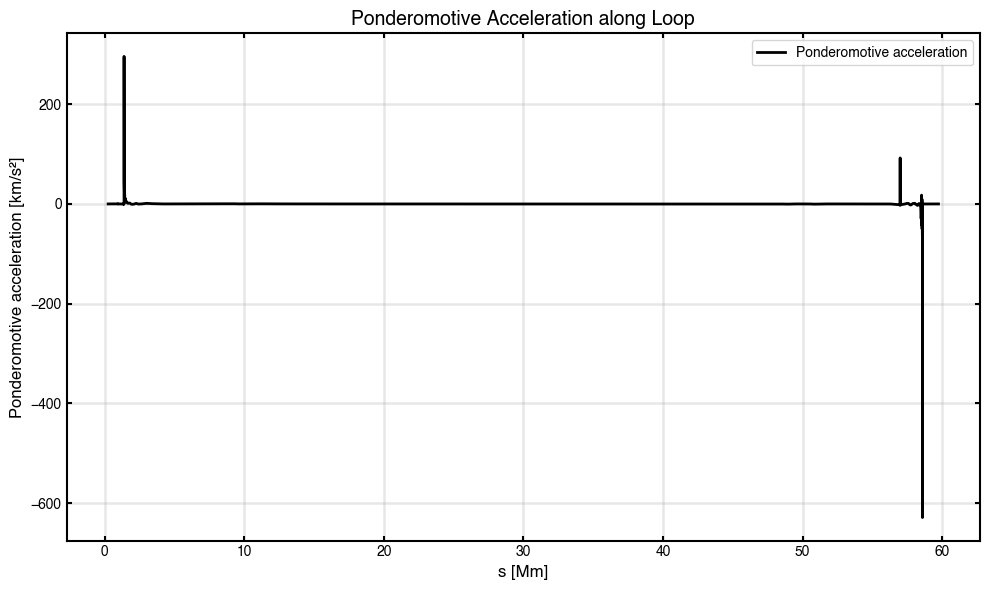

In [301]:
# Plot ponderomotive acceleration
plt.figure(figsize=(10, 6))
s_values_mm = alfven_data['s_values'].to(u.Mm).value
ponderomotive_accel_km_s2 = alfven_data['ponderomotive_acceleration'] / 1e5

plt.plot(s_values_mm, ponderomotive_accel_km_s2, linewidth=2, color='black', label='Ponderomotive acceleration')
plt.xlabel('s [Mm]', fontsize=12)
plt.ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
plt.title('Ponderomotive Acceleration along Loop', fontsize=14)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


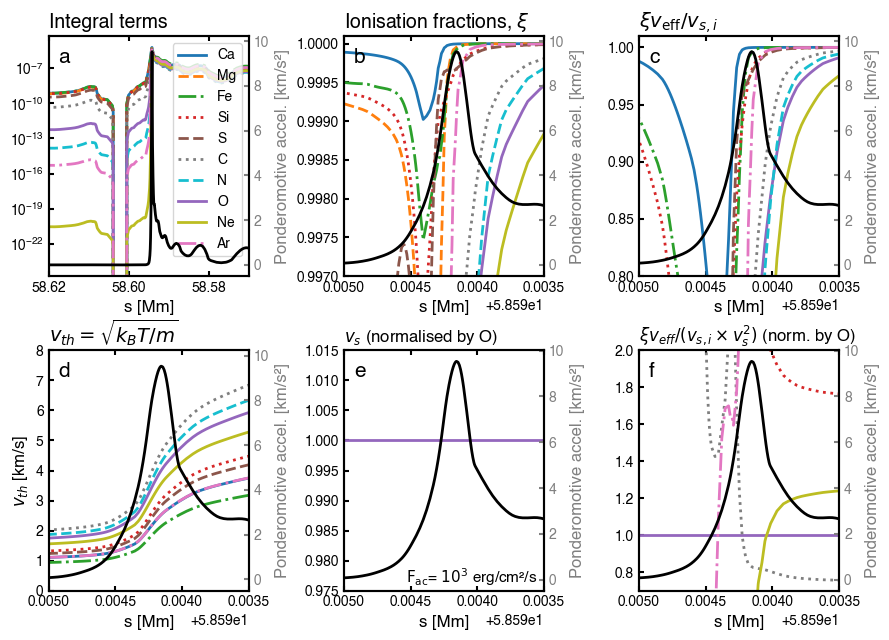

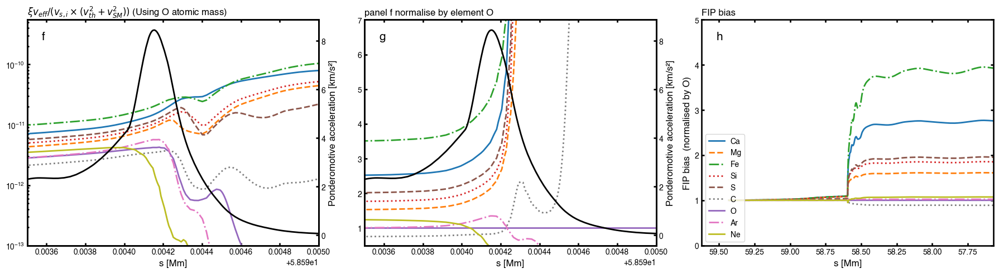

In [782]:
# Plot collision frequencies, neutral hydrogen density, and hydrogen ionization
fig, (ax6, ax7, ax_fip) = plt.subplots(1, 3, figsize=(18, 5))
title_location = 'left'
s_values_mm = alfven_data['s_values'].to(u.Mm).value
xmin, xmax = 58.62, 58.57
ax5_6_xmin, ax5_6_xmax = 58.5935, 58.595

thermal_speed_squared = alfven_data['thermal_speed_squared']

# First subplot: Same as previous ax6
for element, ionization_fraction in alfven_data['ionization_fractions'].items():
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    collision_data = alfven_data['collision_frequencies'][element]
    ratio = collision_data.v_eff/collision_data.v_ion * ionization_fraction / (thermal_speed_squared[element]+alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2)
    ax6.plot(s_values_mm, ratio, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax6.set_xlabel('s [Mm]', fontsize=12)
ax6.set_title(r'$\xi v_{eff}/(v_{s,i} \times (v_{th}^2+v_{SM}^2))$ (Using O atomic mass)', fontsize=12, loc=title_location)
ax6.set_xlim(xmin, xmax)
ax6.set_yscale('log')

ax6.set_xlim(ax5_6_xmin, ax5_6_xmax)
ax6.set_ylim(bottom=1e-13)

# Add subplot label (f)
ax6.text(0.05, 0.95, 'f', transform=ax6.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)
ax6_twin = ax6.twinx()
ax6_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', label='Ponderomotive accel.',alpha=1)
ax6_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
# ax6_twin.set_ylim(top=0.7e6)

# Second subplot: Ratio of element collision frequency to O collision frequency
# Calculate O ratio for reference
collision_data_C = alfven_data['collision_frequencies']['O']
ionization_fraction_C = alfven_data['ionization_fractions']['O']
ratio_C = collision_data_C.v_eff/collision_data_C.v_ion * ionization_fraction_C / (thermal_speed_squared['O']+alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2)

for element, ionization_fraction in alfven_data['ionization_fractions'].items():
    # if element == 'O':
    #     continue  # Skip C itself
    color = element_colors.get(element, None)
    linestyle = element_linestyles.get(element, '-')
    collision_data = alfven_data['collision_frequencies'][element]
    ratio = collision_data.v_eff/collision_data.v_ion * ionization_fraction / (thermal_speed_squared[element]+alfven_data['slow_mode_velocity'].to(u.cm/u.s).value**2)
    ratio_normalized = ratio / ratio_C
    ax7.plot(s_values_mm, ratio_normalized, linewidth=2, label=element,
            color=color, linestyle=linestyle)

ax7.set_xlabel('s [Mm]', fontsize=12)
ax7.set_title(r'panel f normalise by element O', fontsize=12, loc=title_location)
ax7.set_xlim(xmin, xmax)
# ax7.set_yscale('log')
ax7.set_xlim(ax5_6_xmin, ax5_6_xmax)
ax7.set_ylim(5e-1,7)
ax7_twin = ax7.twinx()
ax7_twin.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='black', linestyle='-', label='Ponderomotive accel.',alpha=1)
ax7_twin.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)

# Add subplot label (g)
ax7.text(0.05, 0.95, 'g', transform=ax7.transAxes, 
        fontsize=15, fontweight='bold', va='top', ha='left',)

# Third subplot: FIP bias plot
# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Plot right footpoint for each element (normalized by oxygen)
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights'])  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            ax_fip.plot(heights_right, bias_right_normalized, label=f'{element}', 
                       linestyle=linestyle, color=color, linewidth=2)

ax_fip.set_xlabel('s [Mm]', fontsize=12)
ax_fip.set_ylabel('FIP bias  (normalised by O)', fontsize=12)
ax_fip.set_title('FIP bias', fontsize=12, loc=title_location)
ax_fip.set_ylim(0, 5)
# ax_fip.set_yticks([1,2,3,4])
# ax_fip.set_yticklabels([1,2,3,4])
# ax_fip.grid(True, alpha=0.3)
# ax_fip.invert_xaxis()
# ax_fip.set_xlim(left=xmin*10, right=xmax*10)
# ax_fip.set_xscale('log')
ax_fip.legend(loc='lower left', fontsize=10, ncol=1)

ax_fip.set_xlim(left=xmin+1, right=xmax-1)
# ax_fip.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
# ax_fip.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
# ax_fip.xaxis.set_minor_formatter(NullFormatter())
# ax12_xticks = [x*10 for x in ax10_xticks]

# ax_fip.set_xticks(ax12_xticks)
# ax_fip.set_xticklabels([f'{x/1e9:.2f}' for x in ax12_xticks])
# Add subplot label (h)
ax_fip.text(0.05, 0.95, 'h', transform=ax_fip.transAxes, 
            fontsize=15, fontweight='bold', va='top', ha='left',)

plt.tight_layout()
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}_collision_frequencies.pdf')
plt.show()


In [778]:
data_fip['right']['heights']

array([44.95747087, 45.09048569, 45.2235005 , ..., 59.42701829,
       59.42843645, 59.4296875 ])

In [ ]:
# Plot ponderomotive acceleration, temperature, VA_s, and rho scale height together
# Create figure with 1x2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# First subplot: Ponderomotive acceleration and Temperature (Full Range)
ax1_left = ax1
ax1_left.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='blue', linestyle='-', label='Ponderomotive acceleration')
ax1_left.set_xlabel('s [Mm]', fontsize=12)
ax1_left.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12, color='blue')
ax1_left.tick_params(axis='y', labelcolor='blue')
ax1_left.set_xlim(xmin, xmax)

ax1_right = ax1_left.twinx()
ax1_right.plot(s_values_mm, alfven_data['T'], 
               linewidth=2, color='red', linestyle='-', label='Temperature')
ax1_right.set_ylabel('Temperature [K]', fontsize=12, color='red')
ax1_right.tick_params(axis='y', labelcolor='red')

ax1_left.set_title('Ponderomotive acceleration and Temperature (Full Range)', fontsize=14)
ax1_left.legend(loc='upper left', fontsize=10)
ax1_right.legend(loc='upper right', fontsize=10)

# Second subplot: Ponderomotive acceleration and Temperature (Zoomed)
ax2_left = ax2
ax2_left.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='blue', linestyle='-', label='Ponderomotive acceleration')
ax2_left.set_xlabel('s [Mm]', fontsize=12)
ax2_left.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12, color='blue')
ax2_left.tick_params(axis='y', labelcolor='blue')
ax2_left.set_xlim(ax5_6_xmin, ax5_6_xmax)

ax2_right = ax2_left.twinx()
ax2_right.plot(s_values_mm, alfven_data['T'], 
               linewidth=2, color='red', linestyle='-', label='Temperature')
ax2_right.set_ylabel('Temperature [K]', fontsize=12, color='red')
ax2_right.tick_params(axis='y', labelcolor='red')

ax2_left.set_title('Ponderomotive acceleration and Temperature (Zoomed)', fontsize=14)
ax2_left.legend(loc='upper left', fontsize=10)
ax2_right.legend(loc='upper right', fontsize=10)

plt.tight_layout()
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}_ponderomotive_temperature.pdf')
plt.show()


In [651]:
alfven_data.keys()

dict_keys(['s_values', 'I_plus', 'I_minus', 'delta_B_over_sqrt_4pi_rho', 'delta_v', 'flux_right', 'flux_left', 'normalized_flux_difference', 'ponderomotive_acceleration', 'acceleration_cm_s2', 'VA_s', 'ne', 'nh', 'h_ionisation', 'T', 'thermal_speed_squared', 'B', 'rho', 'collision_components_dict', 'slow_mode_velocity', 'fip_bias_heights', 'ionization_fractions', 'collision_frequencies', 'integral_terms', 'frequency', 'amplitude', 'loop_length'])

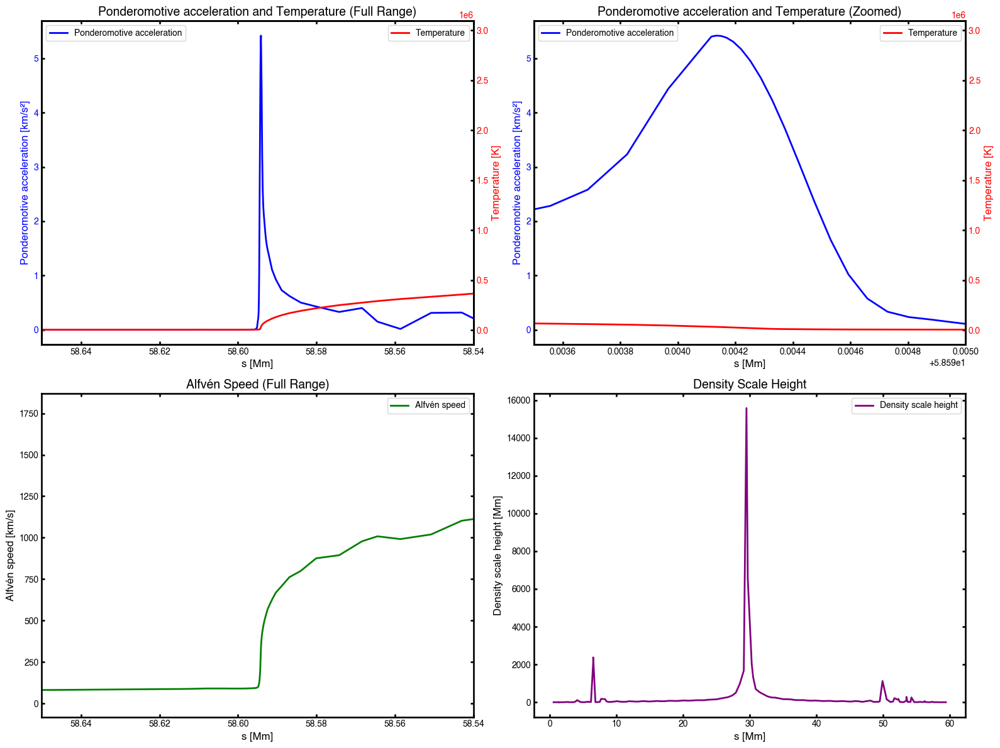

In [665]:
# Plot ponderomotive acceleration, temperature, VA_s, and rho scale height together
# Create figure with 2x2 subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# First subplot: Ponderomotive acceleration and Temperature (Full Range)
ax1_left = ax1
ax1_left.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='blue', linestyle='-', label='Ponderomotive acceleration')
ax1_left.set_xlabel('s [Mm]', fontsize=12)
ax1_left.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12, color='blue')
ax1_left.tick_params(axis='y', labelcolor='blue')
ax1_left.set_xlim(xmin, xmax)

ax1_right = ax1_left.twinx()
ax1_right.plot(s_values_mm, alfven_data['T'], 
               linewidth=2, color='red', linestyle='-', label='Temperature')
ax1_right.set_ylabel('Temperature [K]', fontsize=12, color='red')
ax1_right.tick_params(axis='y', labelcolor='red')

ax1_left.set_title('Ponderomotive acceleration and Temperature (Full Range)', fontsize=14)
ax1_left.legend(loc='upper left', fontsize=10)
ax1_right.legend(loc='upper right', fontsize=10)

# Second subplot: Ponderomotive acceleration and Temperature (Zoomed)
ax2_left = ax2
ax2_left.plot(s_values_mm, np.abs(alfven_data['ponderomotive_acceleration']/1e5), 
              linewidth=2, color='blue', linestyle='-', label='Ponderomotive acceleration')
ax2_left.set_xlabel('s [Mm]', fontsize=12)
ax2_left.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12, color='blue')
ax2_left.tick_params(axis='y', labelcolor='blue')
ax2_left.set_xlim(ax5_6_xmin, ax5_6_xmax)

ax2_right = ax2_left.twinx()
ax2_right.plot(s_values_mm, alfven_data['T'], 
               linewidth=2, color='red', linestyle='-', label='Temperature')
ax2_right.set_ylabel('Temperature [K]', fontsize=12, color='red')
ax2_right.tick_params(axis='y', labelcolor='red')

ax2_left.set_title('Ponderomotive acceleration and Temperature (Zoomed)', fontsize=14)
ax2_left.legend(loc='upper left', fontsize=10)
ax2_right.legend(loc='upper right', fontsize=10)

# Third subplot: Alfvén speed (Full Range)
ax3.plot(s_values_mm, alfven_data['VA_s']/1e5, 
         linewidth=2, color='green', linestyle='-', label='Alfvén speed')
ax3.set_xlabel('s [Mm]', fontsize=12)
ax3.set_ylabel('Alfvén speed [km/s]', fontsize=12)
ax3.set_xlim(xmin, xmax)
ax3.set_title('Alfvén Speed (Full Range)', fontsize=14)
ax3.legend(loc='best', fontsize=10)

# Fourth subplot: Density scale height
# Calculate density scale height: H_rho = -rho / (drho/ds)
# Convert s_values to plain numpy array for gradient calculation
s_values_array = alfven_data['s_values'].to(u.cm).value if hasattr(alfven_data['s_values'], 'unit') else alfven_data['s_values']
rho_array = alfven_data['rho'].to(u.g/u.cm**3).value if hasattr(alfven_data['rho'], 'unit') else alfven_data['rho']

drho_ds = np.gradient(rho_array, s_values_array)
scale_height = -rho_array / drho_ds
# Convert to Mm for better readability
scale_height_mm = scale_height / 1e8  # cm to Mm

ax4.plot(s_values_mm, np.abs(scale_height_mm), 
         linewidth=2, color='purple', linestyle='-', label='Density scale height')
ax4.set_xlabel('s [Mm]', fontsize=12)
ax4.set_ylabel('Density scale height [Mm]', fontsize=12)
# ax4.set_xlim(xmin, xmax)
ax4.set_title('Density Scale Height', fontsize=14)
ax4.legend(loc='best', fontsize=10)
# Set reasonable y-limits to avoid extreme values
# ax4.set_ylim(np.percentile(scale_height_mm[np.isfinite(scale_height_mm)], 1), 
#              np.percentile(scale_height_mm[np.isfinite(scale_height_mm)], 99))

plt.tight_layout()
plt.show()


Peaks in density scale height (excluding middle, above 1000): 2 peaks
Peak locations (s [Mm]): [ 6.5        49.91390467]
Peak values (Mm): [2374.86684472 1122.88116153]

Peaks in ponderomotive acceleration (above 1000): 11 peaks
Peak locations (s [Mm]): [ 1.38128387  1.484375    1.7402541   2.25        3.03125    57.05074179
 57.70833333 58.24021465 58.4921875  58.5683594  58.59413527]
Peak values (cm/s²): [349456.37360019  10639.5401467    2457.86395419   1243.96986215
   1405.58265914   2378.61416179   2318.13116774   3191.18431588
  24387.66520919  40074.43059208 541895.56631755]

Correspondence analysis:
Scale height peak 1 at s=6.50 Mm -> Nearest ponderomotive peak at s=3.03 Mm (distance: 3.47 Mm)
Scale height peak 2 at s=49.91 Mm -> Nearest ponderomotive peak at s=57.05 Mm (distance: 7.14 Mm)


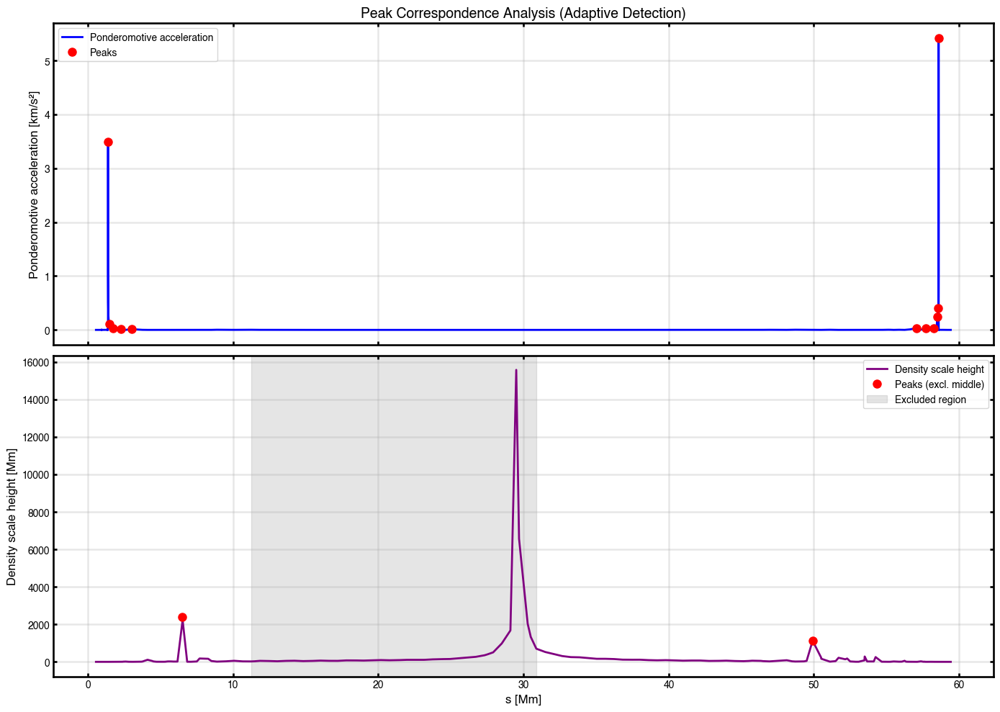

In [670]:
# Check if peaks in density scale height correspond to peaks in ponderomotive force
# Use adaptive mesh refinement approach to better capture peak locations

# Get absolute values for analysis
ponderomotive_abs = np.abs(alfven_data['ponderomotive_acceleration'].to(u.cm/u.s**2).value)
scale_height_abs = np.abs(scale_height_mm)

# Define "middle" region to ignore (e.g., middle 20% of the array)
n_points = len(s_values_mm)
middle_start = int(0.45 * n_points)
middle_end = int(0.55 * n_points)

# Create mask to exclude middle region
mask = np.ones(n_points, dtype=bool)
mask[middle_start:middle_end] = False

# Calculate gradients to identify regions of rapid change
# These regions likely need better resolution for peak detection
s_vals_cm = s_values_array  # Already in cm

# Normalized gradients of key quantities
dpond = np.abs(np.gradient(ponderomotive_abs))
dpond_norm = dpond / (np.max(dpond) + 1e-10)

dscale = np.abs(np.gradient(scale_height_abs))
dscale_norm = dscale / (np.max(dscale) + 1e-10)

# Combined metric to identify critical regions
combined_metric = dpond_norm + dscale_norm

# Find peaks in density scale height (excluding middle region)
from scipy.signal import find_peaks

# Adaptive threshold based on local gradient
# Use lower prominence in regions with high gradients
base_prominence = np.nanpercentile(scale_height_abs[mask], 50)
adaptive_prominence = base_prominence * (1 - 0.5 * combined_metric / np.max(combined_metric))

# Find peaks in scale height (only in non-middle regions and above threshold)
scale_height_masked = scale_height_abs.copy()
scale_height_masked[~mask] = 0  # Set middle region to 0 to ignore peaks there
scale_height_masked[scale_height_abs < 1000] = 0  # Set values below 1000 to 0

peaks_scale_height, properties_scale = find_peaks(scale_height_masked, 
                                                   prominence=base_prominence * 0.5,  # Lower threshold
                                                   distance=5)  # Minimum distance between peaks

# Find peaks in ponderomotive force (only above threshold)
ponderomotive_masked = ponderomotive_abs.copy()
ponderomotive_masked[ponderomotive_abs < 1000] = 0  # Set values below 1000 to 0

peaks_ponderomotive, properties_pond = find_peaks(ponderomotive_masked, 
                                                   prominence=np.nanpercentile(ponderomotive_abs, 50) * 0.5,
                                                   distance=5)

print(f"Peaks in density scale height (excluding middle, above 1000): {len(peaks_scale_height)} peaks")
print(f"Peak locations (s [Mm]): {s_values_mm[peaks_scale_height]}")
print(f"Peak values (Mm): {scale_height_abs[peaks_scale_height]}")
print()
print(f"Peaks in ponderomotive acceleration (above 1000): {len(peaks_ponderomotive)} peaks")
print(f"Peak locations (s [Mm]): {s_values_mm[peaks_ponderomotive]}")
print(f"Peak values (cm/s²): {ponderomotive_abs[peaks_ponderomotive]}")
print()

# Check correspondence: find nearest ponderomotive peak for each scale height peak
print("Correspondence analysis:")
for i, sh_peak_idx in enumerate(peaks_scale_height):
    sh_peak_location = s_values_mm[sh_peak_idx]
    # Find nearest ponderomotive peak
    if len(peaks_ponderomotive) > 0:
        distances = np.abs(s_values_mm[peaks_ponderomotive] - sh_peak_location)
        nearest_pond_idx = peaks_ponderomotive[np.argmin(distances)]
        nearest_pond_location = s_values_mm[nearest_pond_idx]
        distance = np.abs(nearest_pond_location - sh_peak_location)
        print(f"Scale height peak {i+1} at s={sh_peak_location:.2f} Mm -> Nearest ponderomotive peak at s={nearest_pond_location:.2f} Mm (distance: {distance:.2f} Mm)")
    else:
        print(f"Scale height peak {i+1} at s={sh_peak_location:.2f} Mm -> No ponderomotive peaks found")

# Visualize the peaks
fig, (ax_top, ax_bottom) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Top panel: Ponderomotive acceleration with peaks
ax_top.plot(s_values_mm, ponderomotive_abs/1e5, linewidth=2, color='blue', label='Ponderomotive acceleration')
ax_top.plot(s_values_mm[peaks_ponderomotive], ponderomotive_abs[peaks_ponderomotive]/1e5, 
            'ro', markersize=8, label='Peaks')
ax_top.set_ylabel('Ponderomotive acceleration [km/s²]', fontsize=12)
ax_top.set_title('Peak Correspondence Analysis (Adaptive Detection)', fontsize=14)
ax_top.legend(loc='best', fontsize=10)
ax_top.grid(True, alpha=0.3)

# Bottom panel: Density scale height with peaks
ax_bottom.plot(s_values_mm, scale_height_abs, linewidth=2, color='purple', label='Density scale height')
ax_bottom.plot(s_values_mm[peaks_scale_height], scale_height_abs[peaks_scale_height], 
               'ro', markersize=8, label='Peaks (excl. middle)')
# Shade the middle region that was excluded
ax_bottom.axvspan(s_values_mm[middle_start], s_values_mm[middle_end], alpha=0.2, color='gray', label='Excluded region')
ax_bottom.set_xlabel('s [Mm]', fontsize=12)
ax_bottom.set_ylabel('Density scale height [Mm]', fontsize=12)
ax_bottom.legend(loc='best', fontsize=10)
ax_bottom.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [539]:
thermal_speed_squared

{'Ca': array([8.86908486e+09, 8.65609801e+09, 9.05357285e+09, 8.75700205e+09,
        8.65483269e+09, 8.86907677e+09, 9.06847870e+09, 9.23612847e+09,
        9.61631143e+09, 1.00496902e+10, 1.04220771e+10, 1.08303690e+10,
        1.10738383e+10, 1.10859080e+10, 1.08964443e+10, 1.07945640e+10,
        1.07042193e+10, 1.05850657e+10, 1.04501799e+10, 1.03355111e+10,
        1.02867540e+10, 1.02654570e+10, 1.03898846e+10, 1.05632818e+10,
        1.07388105e+10, 1.09674490e+10, 1.10930547e+10, 1.12679633e+10,
        1.14485484e+10, 1.16558268e+10, 1.18203517e+10, 1.19738531e+10,
        1.22222998e+10, 1.23875011e+10, 1.24658469e+10, 1.24901571e+10,
        1.25480989e+10, 1.25976017e+10, 1.26459179e+10, 1.26964038e+10,
        1.27198945e+10, 1.26943619e+10, 1.22765302e+10, 1.18197554e+10,
        1.14521589e+10, 1.12100000e+10, 1.10422213e+10, 1.09121203e+10,
        1.08101768e+10, 1.06805189e+10, 1.05718864e+10, 1.04958635e+10,
        1.04715040e+10, 1.04867048e+10, 1.05673509e+10, 1.

In [ ]:
alfven_data['collision_frequencies']['Ca']

array([9.24288943e+04, 8.30423472e+04, 8.41677546e+04, 6.95211454e+04,
       6.28395067e+04, 5.95502163e+04, 5.34313241e+04, 4.75562647e+04,
       4.43577401e+04, 4.54160111e+04, 5.27065164e+04, 6.06382458e+04,
       5.70265062e+04, 5.75000166e+04, 5.02010961e+04, 4.31658287e+04,
       3.82636364e+04, 3.25888729e+04, 2.70269118e+04, 2.39937274e+04,
       2.40548796e+04, 2.42989674e+04, 2.44072063e+04, 2.43605593e+04,
       2.44263553e+04, 2.65848649e+04, 3.07524611e+04, 3.51614087e+04,
       3.92279825e+04, 4.50910475e+04, 5.09103386e+04, 5.69074732e+04,
       6.27109281e+04, 6.46224568e+04, 6.32901239e+04, 5.99489037e+04,
       6.19102107e+04, 6.46031183e+04, 6.77580950e+04, 7.16055103e+04,
       7.99987030e+04, 9.94484327e+04, 8.67827849e+04, 6.59155339e+04,
       4.55759399e+04, 3.48918635e+04, 2.95031402e+04, 2.69356142e+04,
       2.59233907e+04, 2.57850266e+04, 2.56768409e+04, 2.55539648e+04,
       2.53481072e+04, 2.49072645e+04, 2.40647711e+04, 2.29559256e+04,
      

In [155]:
import astropy.constants as const


In [156]:
const.m_p.cgs

<Quantity 1.67262192e-24 g>

In [ ]:
def calculate_alfven_speed(B, rho):
    """
    Calculate the Alfvén speed.
    
    Parameters:
    -----------
    B : astropy.units.Quantity
        Magnetic field strength (e.g., in Gauss or Tesla)
    rho : astropy.units.Quantity
        Mass density (e.g., in g/cm^3)
    
    Returns:
    --------
    V_A : astropy.units.Quantity
        Alfvén speed in cm/s
    """
    # Alfvén speed: V_A = B / sqrt(4π * rho)
    # Need to ensure proper unit handling
    B_cgs = B.to(u.G)  # Convert to Gauss
    rho_cgs = rho.to(u.g / u.cm**3)  # Convert to g/cm^3
    
    # Calculate V_A with explicit unit handling
    V_A_value = B_cgs.value / np.sqrt(4 * np.pi * rho_cgs.value)
    V_A = V_A_value * (u.cm / u.s)
    
    return V_A


In [509]:
heights_O_mm

array([4450.     , 4550.     , 4650.     , 4750.     , 4850.     ,
       4950.     , 5050.     , 5150.     , 5250.     , 5350.     ,
       5425.     , 5475.     , 5550.     , 5625.     , 5662.5    ,
       5687.5    , 5712.5    , 5737.5    , 5762.5    , 5787.5    ,
       5806.25   , 5818.75   , 5831.25   , 5840.625  , 5845.3125 ,
       5847.65625, 5849.21875, 5850.78125, 5852.34375, 5853.51562,
       5854.29688, 5855.07812, 5855.85938, 5856.44531, 5856.83594,
       5857.42188, 5858.00781, 5858.39844, 5858.69141, 5858.88672,
       5859.0332 , 5859.13086, 5859.22852, 5859.30176, 5859.33838,
       5859.36279, 5859.38721, 5859.41162, 5859.43604, 5859.46045,
       5859.48486, 5859.50928, 5859.53369, 5859.55811, 5859.58252,
       5859.60693, 5859.64355, 5859.7168 , 5859.86328, 5860.05859,
       5860.35156, 5860.64453, 5860.79102, 5860.88867, 5860.98633,
       5861.08398, 5861.23047, 5861.52344, 5862.10938, 5863.28125,
       5864.45312, 5865.23438, 5866.40625, 5867.96875, 5870.31

In [497]:
bias_right_normalized

array([0.88290646, 0.8913915 , 0.88317182, 0.89191095, 0.88385156,
       0.89290726, 0.88484965, 0.89394843, 0.88576253, 0.89438295,
       0.88601331, 0.89446408, 0.88615276, 0.89468442, 0.88686799,
       0.89681203, 0.89023461, 0.8996005 , 0.89064579, 0.90010582,
       0.89075373, 0.90047063, 0.89340793, 0.90276651, 0.89602146,
       0.90692887, 0.90210659, 0.91551468, 0.90822437, 0.91521904,
       0.90938326, 0.9222121 , 0.91644308, 0.92449075, 0.9192222 ,
       0.93221059, 0.92908935, 0.94296645, 0.93939689, 0.95311883,
       0.94905828, 0.96274238, 0.95990813, 0.97575653, 0.9705605 ,
       0.98346012, 0.97843369, 0.99905608, 1.00178234, 1.00080467,
       1.00078768, 1.0007795 , 1.00077245, 1.00076838, 1.00076545,
       1.00076353, 1.00075862, 1.00074892, 1.0007358 , 1.00072945,
       1.00073031, 1.00072898, 1.0007266 , 1.00071852, 1.00071455,
       1.00070724, 1.00070356, 1.00069316, 1.00068279, 1.00065625,
       1.00063341, 1.00061612, 1.0005958 , 1.00056447, 1.00052

In [ ]:

# Calculate maximum ponderomotive acceleration in height range
ponderomotive_accel = alfven_data['ponderomotive_acceleration']
s_values_accel = alfven_data['s_values']

# Define height range (matching the plot range)
# Convert xmax and xmin to the same units as s_values_accel
xmax_with_unit = xmax * 10 * u.cm
xmin_with_unit = xmin * 10 * u.cm

# Ensure s_values_accel has units
if not hasattr(s_values_accel, 'unit'):
    s_values_accel = s_values_accel * u.cm

# Convert to consistent units for comparison
s_values_accel_mm = s_values_accel.to(u.Mm)
height_mask = (s_values_accel_mm >= xmax_with_unit) & (s_values_accel_mm <= xmin_with_unit)
ponderomotive_accel_in_range = ponderomotive_accel[height_mask]
s_values_in_range = s_values_accel[height_mask]

# Check if we have any data in the range
if len(ponderomotive_accel_in_range) > 0:
    # Find maximum ponderomotive acceleration and its location
    max_ponderomotive_idx = np.argmax(np.abs(ponderomotive_accel_in_range))
    max_ponderomotive_accel = ponderomotive_accel_in_range[max_ponderomotive_idx]
    max_ponderomotive_height = s_values_in_range[max_ponderomotive_idx]

    print(f"Maximum ponderomotive acceleration: {max_ponderomotive_accel:.3e} cm/s²")
    print(f"Location: {max_ponderomotive_height.to(u.Mm).value:.3f} Mm")

    # Get ionization fractions at the peak ponderomotive acceleration location
    print(f"\nIonization fractions at peak ponderomotive acceleration location ({max_ponderomotive_height.to(u.Mm).value:.3f} Mm):")

    for element in ionization_data.keys():
        # Find closest height index in s_values
        closest_idx = np.argmin(np.abs(s_values - max_ponderomotive_height))
        fraction_at_peak = ionization_data[element][closest_idx]
        print(f"{element}: {fraction_at_peak:.4f}")

    # Get FIP bias at the peak location
    print(f"\nFIP bias at peak ponderomotive acceleration location ({max_ponderomotive_height.to(u.Mm).value:.3f} Mm):")
    for element, data_fip in fip_bias_heights.items():
        if 'right' in data_fip:
            heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
            bias_right = np.array(data_fip['right']['bias'])
            # Find closest height index
            closest_idx = np.argmin(np.abs(heights_right - max_ponderomotive_height.to(u.cm).value))
            bias_at_peak = bias_right[closest_idx]
            if oxygen_bias_right is not None:
                bias_normalized = bias_at_peak / oxygen_bias_right[closest_idx]
                print(f"{element}: {bias_at_peak:.3f} (normalized: {bias_normalized:.3f})")
            else:
                print(f"{element}: {bias_at_peak:.3f}")
else:
    print(f"No data found in height range [{xmax_with_unit.value:.3f}, {xmin_with_unit.value:.3f}] Mm")
    print(f"Available height range: [{s_values_accel_mm.min().value:.3f}, {s_values_accel_mm.max().value:.3f}] Mm")


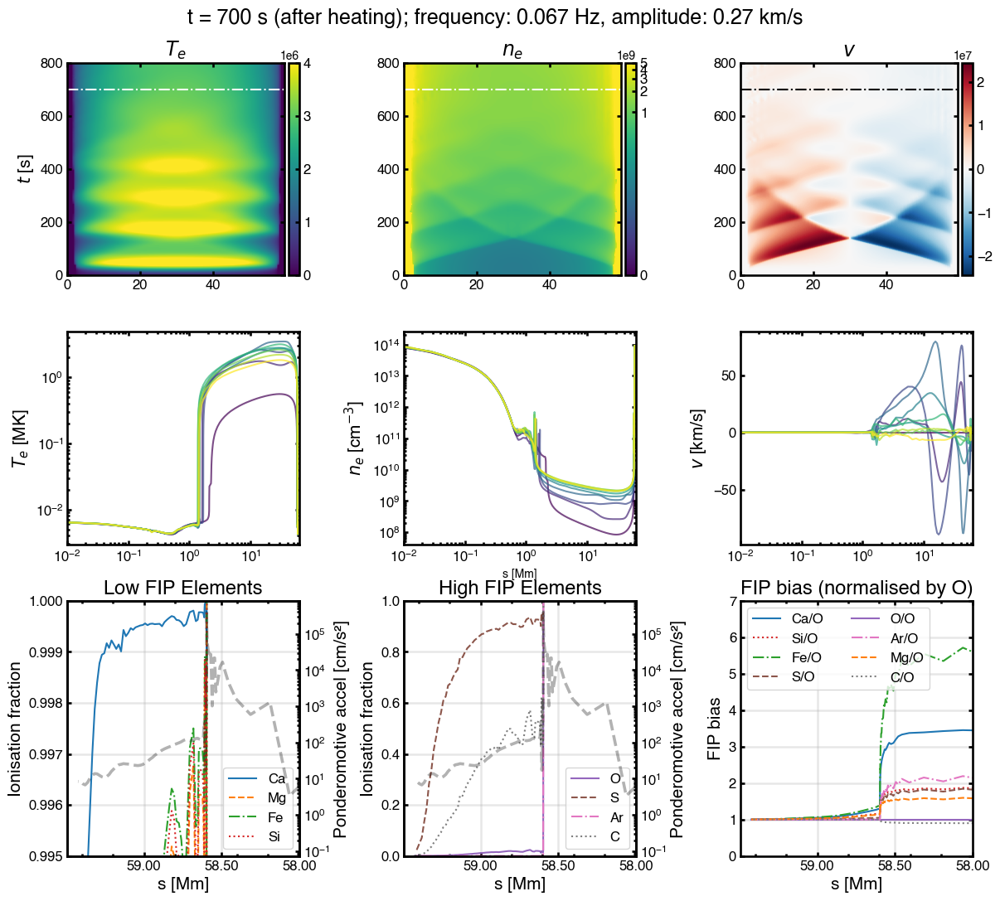

In [435]:
# To load and plot later:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

with open('strand_data.pkl', 'rb') as f:
    data = pickle.load(f)

title_size=17
label_size=15
legend_size=12
tick_size=12
time_index = 700
# Load Alfven data for ionization fractions and FIP bias
frequency = 0.067
amplitude = 0.27
with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/v_{frequency:.3f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_{time_index}.pkl', 'rb') as f:
    alfven_data = pickle.load(f)

# Create a mock strand object or use the data directly
quantities = [
    ('electron_temperature', data['electron_temperature']),
    ('electron_density', data['electron_density']),
    ('velocity', data['velocity']),
]

# Create figure with 6 subplots (2 rows, 3 columns)
fig = plt.figure(figsize=(12, 11))
gs = fig.add_gridspec(3, 3, hspace=0.25, wspace=0.45, height_ratios=[1, 1, 1.2])

# Top row: time-distance plots
ax_top = [fig.add_subplot(gs[0, i]) for i in range(3)]

# Middle row: spatial profiles at specific time
ax_middle = [fig.add_subplot(gs[1, i]) for i in range(3)]

# Bottom row: ionization fractions and FIP bias
ax_bottom = [fig.add_subplot(gs[2, i]) for i in range(3)]

# Define time index for horizontal line and middle plots
time_value = a.time[time_index]

# Plot time-distance diagrams in top row
for i, (label, data_array) in enumerate(quantities):
    # Get coordinate arrays
    t_values = a.time.to(u.s).value
    s_values = data['grid'].to(u.Mm).value
    
    # Set colormap and normalization
    cmap_name = 'RdBu_r' if label == 'velocity' else 'viridis'
    if label == 'electron_density':
        norm = ImageNormalize(vmin=1e8, vmax=1e12, stretch=LogStretch())
    else:
        norm = None
    
    # Create the plot using imshow instead of pcolormesh to avoid dimension issues
    im = ax_top[i].imshow(data_array.value, 
                         cmap=cmap_name, 
                         norm=norm,
                         aspect='auto',
                         origin='lower',
                         extent=[s_values.min(), s_values.max(), t_values.min(), t_values.max()])
    
    # Add colorbar
    cax = make_axes_locatable(ax_top[i]).append_axes("right", size="5%", pad=0.05)
    cbar = fig.colorbar(im, cax=cax)
    cbar.ax.tick_params(labelsize=tick_size)
    
    # Set colorbar limits for electron density
    if i == 1:
        cbar.mappable.set_clim(0, 5e9)
    if i == 0:
        cbar.mappable.set_clim(0, 4e6)
    
    # Set labels
    label_map = {'electron_temperature': r'$T_e$', 'electron_density': r'$n_e$', 'velocity': r'$v$'}
    ax_top[i].set_title(label_map.get(label, label), fontsize=title_size)
    ax_top[i].set_xlabel('')
    if i == 0:
        ax_top[i].set_ylabel(r'$t$ [s]',fontsize=label_size)
    # ax_top[i].set_yscale('log')
    ax_top[i].tick_params(axis='both', labelsize=tick_size)
    
    # Set y-axis limits to trim from t=0 to t=1000
    ax_top[i].set_ylim(0, 800)
    
    # Add horizontal line at time_index
    t = time_index
    if i != 2:
        ax_top[i].axhline(time_value.to(u.s).value, color='white', linestyle='-.', linewidth=1.5, alpha=1)
    else:
        ax_top[i].axhline(time_value.to(u.s).value, color='black', linestyle='-.', linewidth=1.5, alpha=1)

# Get data at multiple time indices for middle plots
# Define time indices to plot
time_indices = np.linspace(0, len(a.time)-1, 10, dtype=int)  # 10 time snapshots
n_times = len(time_indices)

# Create colormap
cmap = plt.cm.viridis
colors = [cmap(i / (n_times - 1)) for i in range(n_times)]

# Plot electron temperature evolution
for idx, t_idx in enumerate(time_indices):
    electron_temp = a[t_idx].electron_temperature
    coordinate = a[t_idx].coordinate
    ax_middle[0].plot(coordinate.to(u.Mm), electron_temp.to(u.MK), 
                     color=colors[idx], alpha=0.7, linewidth=1.5)

ax_middle[0].set_ylabel(r'$T_e$ [MK]',fontsize=label_size)
ax_middle[0].set_yscale('log')
ax_middle[0].set_xlim(left=1e-2)
ax_middle[0].set_xlabel('')
ax_middle[0].set_xscale('log')
ax_middle[0].tick_params(axis='both', labelsize=tick_size)

# Plot electron density evolution
for idx, t_idx in enumerate(time_indices):
    electron_dens = a[t_idx].electron_density
    coordinate = a[t_idx].coordinate
    ax_middle[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3), 
                     color=colors[idx], alpha=0.7, linewidth=1.5)

ax_middle[1].set_ylabel(r'$n_e$ [cm$^{-3}$]',fontsize=label_size)
ax_middle[1].set_yscale('log')
ax_middle[1].set_xlim(left=1e-2)
ax_middle[1].set_xlabel('s [Mm]')
ax_middle[1].set_xscale('log')
ax_middle[1].tick_params(axis='both', labelsize=tick_size)

# Plot velocity evolution
for idx, t_idx in enumerate(time_indices):
    velocity = a[t_idx].velocity
    coordinate = a[t_idx].coordinate
    ax_middle[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s), 
                     color=colors[idx], alpha=0.7, linewidth=1.5)

ax_middle[2].set_ylabel(r'$v$ [km/s]',fontsize=label_size)
ax_middle[2].set_xlabel('')
ax_middle[2].set_xlim(left=1e-2)
ax_middle[2].set_xscale('log')
ax_middle[2].tick_params(axis='both', labelsize=tick_size)

# Bottom row: Ionization fractions and FIP bias
s_values = alfven_data['s_values']
ionization_data = alfven_data['ionization_fractions']

# Define consistent colors and line styles for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

element_linestyles = {
    'Ca': '-',      # solid
    'Mg': '--',     # dashed
    'Fe': '-.',     # dash-dot
    'Si': ':',      # dotted
    'O': '-',       # solid
    'S': '--',      # dashed
    'Ar': '-.',     # dash-dot
    'C': ':'        # dotted
}

xmin = 5.95e9
xmax = 5.8e9
ax10_xticks = [5.8e9, 5.85e9, 5.9e9]

# Plot 1: Ionization fraction - Low FIP elements (Ca, Mg, Fe, Si)
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
ax_ion_low = ax_bottom[0]
ax_accel_low = ax_ion_low.twinx()

for element in low_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_low.plot(s_values, ionization_data[element], label=element, 
                       color=color, linestyle=linestyle, linewidth=1.5)

ax_accel_low.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                  'k--', alpha=0.3, label='|Pond. Accel|')

ax_ion_low.set_ylabel('Ionisation fraction', fontsize=label_size)
ax_accel_low.set_ylabel('Ponderomotive accel [cm/s²]', color='k',fontsize=label_size)
ax_ion_low.set_xlabel('s [Mm]',fontsize=label_size)
ax_ion_low.set_title('Low FIP Elements', fontsize=title_size)
ax_ion_low.legend(loc='lower right', fontsize=legend_size)
# ax_accel_low.legend(loc='upper right')
ax_ion_low.grid(True, alpha=0.3)
ax_ion_low.invert_xaxis()
ax_ion_low.set_xscale('log')
ax_accel_low.set_yscale('log')
ax_accel_low.tick_params(axis='y', labelcolor='k', labelsize=tick_size)
ax_ion_low.tick_params(axis='both', labelsize=tick_size)
from matplotlib.ticker import LogLocator, NullFormatter

# For Low FIP Elements - REMOVE lines 147-148 and replace with:
ax_ion_low.set_xlim(left=xmin, right=xmax)
ax_ion_low.set_ylim(0.995, 1)
ax_ion_low.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_low.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_low.xaxis.set_minor_formatter(NullFormatter())
ax_ion_low.set_xticks(ax10_xticks)
# ax_ion_low.set_yscale('log')
ax_ion_low.set_xticklabels([f'{x/1e8:.2f}' for x in ax10_xticks])


# Plot 2: Ionization fraction - High FIP elements (O, S, Ar, C)
high_fip_elements = ['O', 'S', 'Ar', 'C']
ax_ion_high = ax_bottom[1]
ax_accel_high = ax_ion_high.twinx()

for element in high_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion_high.plot(s_values, ionization_data[element], label=element, 
                        color=color, linestyle=linestyle, linewidth=1.5)

ax_accel_high.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                   'k--', alpha=0.3, label='|Pond. Accel|')

ax_ion_high.set_ylabel('Ionisation fraction',fontsize=label_size)
ax_accel_high.set_ylabel('Ponderomotive accel [cm/s²]', color='k',fontsize=label_size)
ax_ion_high.set_xlabel('s [Mm]',fontsize=label_size)
ax_ion_high.set_title('High FIP Elements', fontsize=title_size)
ax_ion_high.legend(loc='lower right', fontsize=legend_size)
# ax_accel_high.legend(loc='upper right')
ax_ion_high.grid(True, alpha=0.3)
ax_ion_high.invert_xaxis()
ax_ion_high.set_xscale('log')
ax_accel_high.set_yscale('log')
ax_accel_high.tick_params(axis='y', labelcolor='k', labelsize=tick_size)
ax_ion_high.tick_params(axis='both', labelsize=tick_size)
ax_ion_high.set_xlim(left=xmin, right=xmax)
ax_ion_high.set_ylim(0, 1)

ax_ion_high.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_ion_high.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_ion_high.xaxis.set_minor_formatter(NullFormatter())
ax_ion_high.set_xticks(ax10_xticks)
ax_ion_high.set_xticklabels([f'{x/1e8:.2f}' for x in ax10_xticks])

# Plot 3: FIP Bias Heights (normalized by O)
ax_fip = ax_bottom[2]

# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Plot right footpoint for each element (normalized by oxygen)
for element, data_fip in fip_bias_heights.items():
    if 'right' in data_fip:
        heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data_fip['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            ax_fip.plot(heights_right, bias_right_normalized, label=f'{element}/O', 
                       linestyle=linestyle, color=color, linewidth=1.5)

ax_fip.set_xlabel('s [Mm]',fontsize=label_size)
ax_fip.set_ylabel('FIP bias',fontsize=label_size)
ax_fip.set_title('FIP bias (normalised by O)', fontsize=title_size)
ax_fip.legend(loc='best', fontsize=legend_size, ncol=2)
ax_fip.grid(True, alpha=0.3)
ax_fip.invert_xaxis()
ax_fip.set_xscale('log')
ax_fip.set_ylim(0, 7)
ax_fip.set_xlim(left=xmin*10, right=xmax*10)
ax_fip.xaxis.set_major_locator(LogLocator(base=10.0, numticks=5))
ax_fip.xaxis.set_minor_locator(LogLocator(base=10.0, subs='auto', numticks=12))
ax_fip.xaxis.set_minor_formatter(NullFormatter())
ax12_xticks = [x*10 for x in ax10_xticks]

ax_fip.set_xticks(ax12_xticks)
ax_fip.set_xticklabels([f'{x/1e9:.2f}' for x in ax12_xticks])
ax_fip.tick_params(axis='both', labelsize=tick_size)

fig.suptitle(f't = {time_value:.0f} (after heating); frequency: {frequency:.3f} Hz, amplitude: {amplitude:.2f} km/s', fontsize=title_size+1)
# plt.tight_layout()
plt.subplots_adjust(top=0.92,bottom=0.05,left=0.07,right=0.98)
# plt.tight_layout()
plt.savefig(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_0.009_train_with_H_thermal_heating_2000s_1s_step_4_heatings/{time_index}.pdf')
plt.show()


First location where ponderomotive acceleration reaches 10³ cm/s²: -1.048e+02 cm / s2
Location: 5.876 ×10⁹ cm

Plasma parameters when acceleration first reaches 10³ cm/s² (5.876 ×10⁹ cm):
Electron density (ne): 7.934e+10 1 / cm3 cm⁻³
Temperature (T): 5.717e+03 K K
Magnetic field (B): 7.806e+01 G G
Density (rho): 6.261e-12 g / cm3 g/cm³
Alfvén velocity (VA): 8.800e+06 cm / s cm/s

Ionization fractions when acceleration first reaches 10³ cm/s² (5.876 ×10⁹ cm):
Ca: 1.0000
Si: 0.9994
Fe: 0.9994
S: 0.9662
O: 0.0430
Ar: 0.0001
Mg: 0.9994
C: 0.7446

Collision frequencies when acceleration first reaches 10³ cm/s² (5.876 ×10⁹ cm):
Ca:
  v_ion: 1.958e+06 s⁻¹
  v_neutral: 1.163e+03 s⁻¹
  v_eff: 1.868e+06 s⁻¹
  vst (cm/s): 1.805e+05
Si:
  v_ion: 1.362e+06 s⁻¹
  v_neutral: 1.050e+03 s⁻¹
  v_eff: 7.870e+05 s⁻¹
  vst (cm/s): 2.157e+05
Fe:
  v_ion: 2.383e+06 s⁻¹
  v_neutral: 6.023e+02 s⁻¹
  v_eff: 7.129e+05 s⁻¹
  vst (cm/s): 1.522e+05
S:
  v_ion: 1.562e+06 s⁻¹
  v_neutral: 7.240e+02 s⁻¹
  v_eff: 2.114

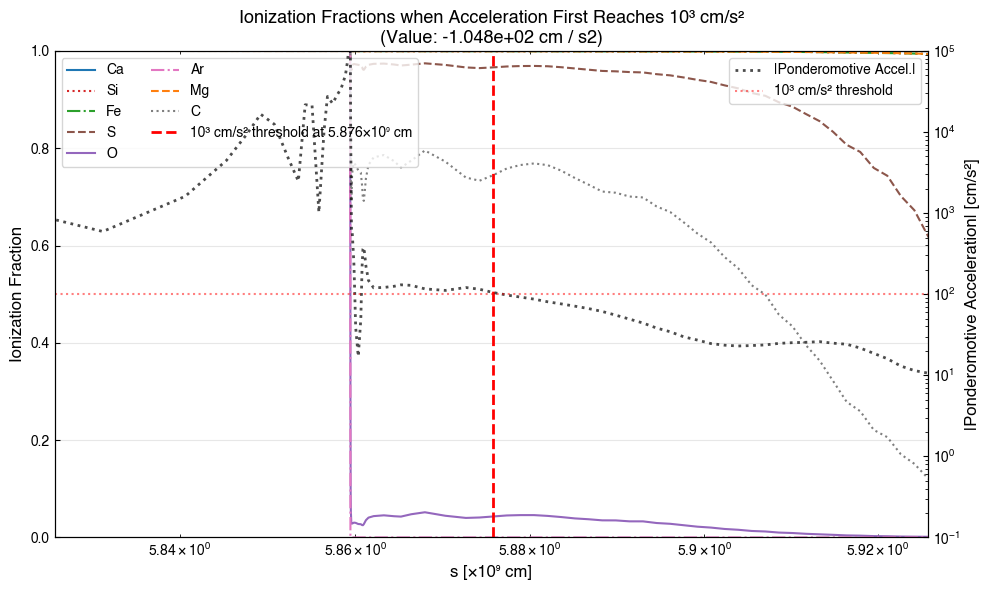

In [366]:
# Calculate maximum ponderomotive acceleration in height range
ponderomotive_accel = alfven_data['ponderomotive_acceleration']
s_values_accel = alfven_data['s_values']

# Define height range (matching the plot range)
# Convert xmax and xmin to cm (they are already in cm from the plot)
xmax_cm = xmax  # 5.8e9 cm
xmin_cm = xmin  # 5.95e9 cm

# Ensure s_values_accel has units
if not hasattr(s_values_accel, 'unit'):
    s_values_accel = s_values_accel * u.cm

# Convert to consistent units for comparison (keep in cm)
s_values_accel_cm = s_values_accel.to(u.cm).value
height_mask = (s_values_accel_cm >= xmax_cm) & (s_values_accel_cm <= xmin_cm)
ponderomotive_accel_in_range = ponderomotive_accel[height_mask]
s_values_in_range = s_values_accel[height_mask]

# Check if we have any data in the range
if len(ponderomotive_accel_in_range) > 0:
    # Find first location where acceleration reaches 10^3 cm/s², starting from xmin
    # Sort indices by s_values in descending order (start from xmin, highest s value)
    sorted_indices = np.argsort(s_values_in_range.to(u.cm).value)[::-1]
    
    # Find the first location where |acceleration| >= 10^3 cm/s²
    threshold_accel = 1e2  # cm/s²
    first_threshold_accel = None
    first_threshold_height = None
    first_threshold_idx = None
    
    # Convert ponderomotive acceleration to dimensionless values for comparison
    if hasattr(ponderomotive_accel_in_range, 'unit'):
        abs_accel = np.abs(ponderomotive_accel_in_range.to(u.cm/u.s**2).value)
    else:
        abs_accel = np.abs(ponderomotive_accel_in_range)
    
    for i in sorted_indices:
        if abs_accel[i] >= threshold_accel:
            first_threshold_accel = ponderomotive_accel_in_range[i]
            first_threshold_height = s_values_in_range[i]
            first_threshold_idx = i
            break
    
    if first_threshold_accel is not None:
        print(f"First location where ponderomotive acceleration reaches 10³ cm/s²: {first_threshold_accel:.3e}")
        print(f"Location: {first_threshold_height.to(u.cm).value/1e9:.3f} ×10⁹ cm")

        # Convert first_threshold_height to same units as s_values for comparison
        first_threshold_height_cm = first_threshold_height.to(u.cm).value
        
        # Ensure s_values is in cm (convert if it has units, otherwise assume it's already in cm)
        if hasattr(s_values, 'unit'):
            s_values_cm_for_comparison = s_values.to(u.cm).value
        else:
            s_values_cm_for_comparison = s_values

        # Find closest height index in s_values for all parameters
        closest_idx = np.argmin(np.abs(s_values_cm_for_comparison - first_threshold_height_cm))

        # Get plasma parameters at the threshold location
        print(f"\nPlasma parameters when acceleration first reaches 10³ cm/s² ({first_threshold_height.to(u.cm).value/1e9:.3f} ×10⁹ cm):")
        
        # Extract plasma parameters from alfven_data
        ne_values = alfven_data['ne']
        T_values = alfven_data['T']
        B_values = alfven_data['B']
        rho_values = alfven_data['rho']
        VA_values = alfven_data['VA_s']
        
        print(f"Electron density (ne): {ne_values[closest_idx]:.3e} cm⁻³")
        print(f"Temperature (T): {T_values[closest_idx]:.3e} K")
        print(f"Magnetic field (B): {B_values[closest_idx]:.3e} G")
        print(f"Density (rho): {rho_values[closest_idx]:.3e} g/cm³")
        print(f"Alfvén velocity (VA): {VA_values[closest_idx]:.3e} cm/s")

        # Get ionization fractions at the threshold location
        print(f"\nIonization fractions when acceleration first reaches 10³ cm/s² ({first_threshold_height.to(u.cm).value/1e9:.3f} ×10⁹ cm):")

        for element in ionization_data.keys():
            fraction_at_threshold = ionization_data[element][closest_idx]
            print(f"{element}: {fraction_at_threshold:.4f}")
        # Get collision frequencies at the threshold location
        print(f"\nCollision frequencies when acceleration first reaches 10³ cm/s² ({first_threshold_height.to(u.cm).value/1e9:.3f} ×10⁹ cm):")
        collision_frequencies = alfven_data['collision_frequencies']
        for element in collision_frequencies.keys():
            collision_components = collision_frequencies[element]
            # Access the collision frequency arrays from the CollisionComponents object
            v_ion_at_threshold = collision_components.v_ion[closest_idx]
            v_neutral_at_threshold = getattr(collision_components, 'v_neutral', None)
            v_eff_at_threshold = getattr(collision_components, 'v_eff', None)
            # Calculate vst^2 = slow_mode_velocity^2 + vs^2 + (k_B * T / (mass_number * amu))
            # slow_mode_velocity from alfven_data['slow_mode_velocity']
            # vs from collision_components.v_s
            # mass number from collision_components.mass_number
            k_B_cgs = 1.380649e-16  # erg/K (CGS units)
            amu_cgs = 1.66053906660e-24  # g

            # Get slow_mode_velocity for this location (in cm/s)
            slow_mode_velocity = alfven_data['slow_mode_velocity'][closest_idx]
            vs = collision_components.v_s
            # vs might be a scalar or array; if array, grab the value at this location
            if isinstance(vs, (np.ndarray, list)):
                vs_at_threshold = vs
                if len(vs) == len(s_values):
                    vs_at_threshold = vs[closest_idx]
                else:
                    vs_at_threshold = vs
            else:
                vs_at_threshold = vs

            # Get mass_number (dimensionless, per element)
            mass_number = collision_components.mass_number
            # Get temperature (in K) at threshold
            if isinstance(T_values, (np.ndarray, list)):
                T_at_threshold = T_values[closest_idx]
            else:
                T_at_threshold = T_values

            # Strip units from all quantities before calculation
            if hasattr(slow_mode_velocity, 'value'):
                slow_mode_velocity_val = slow_mode_velocity.value
            else:
                slow_mode_velocity_val = slow_mode_velocity
            
            if hasattr(vs_at_threshold, 'value'):
                vs_at_threshold_val = vs_at_threshold.value
            else:
                vs_at_threshold_val = vs_at_threshold
            
            if hasattr(T_at_threshold, 'value'):
                T_at_threshold_val = T_at_threshold.value
            else:
                T_at_threshold_val = T_at_threshold

            vst_squared = (
                slow_mode_velocity_val ** 2 +
                vs_at_threshold_val ** 2 +
                (k_B_cgs * T_at_threshold_val) / (mass_number * amu_cgs)
            )
            vst = np.sqrt(vst_squared)

            print(f"{element}:")
            print(f"  v_ion: {v_ion_at_threshold:.3e} s⁻¹")
            if v_neutral_at_threshold is not None:
                print(f"  v_neutral: {v_neutral_at_threshold[closest_idx]:.3e} s⁻¹")
            else:
                print("  v_neutral: N/A")
            if v_eff_at_threshold is not None:
                print(f"  v_eff: {v_eff_at_threshold[closest_idx]:.3e} s⁻¹")
            else:
                print("  v_eff: N/A")
            print(f"  vst (cm/s): {vst:.3e}")

        # Get FIP bias at the threshold location
        print(f"\nFIP bias when acceleration first reaches 10³ cm/s² ({first_threshold_height.to(u.cm).value/1e9:.3f} ×10⁹ cm):")
        for element, data_fip in fip_bias_heights.items():
            if 'right' in data_fip:
                heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
                bias_right = np.array(data_fip['right']['bias'])
                # Find closest height index
                closest_idx_fip = np.argmin(np.abs(heights_right - first_threshold_height_cm))
                bias_at_threshold = bias_right[closest_idx_fip]
                if oxygen_bias_right is not None:
                    bias_normalized = bias_at_threshold / oxygen_bias_right[closest_idx_fip]
                    print(f"{element}: {bias_at_threshold:.3f} (normalized: {bias_normalized:.3f})")
                else:
                    print(f"{element}: {bias_at_threshold:.3f}")

        # Plot ionization fractions and ponderomotive acceleration around the threshold
        fig_ion, ax_ion = plt.subplots(figsize=(10, 6))
        
        # Define a range around the threshold for better visualization
        threshold_height_cm = first_threshold_height.to(u.cm).value
        plot_min_cm = max(xmax_cm, threshold_height_cm - 0.05e9)  # ±0.05×10⁹ cm around threshold
        plot_max_cm = min(xmin_cm, threshold_height_cm + 0.05e9)
        
        # Convert s_values to cm for plotting (handle units properly)
        if hasattr(s_values, 'unit'):
            s_values_cm = s_values.to(u.cm).value
        else:
            s_values_cm = s_values
        
        # Plot ionization fractions for each element
        for element in ionization_data.keys():
            color = element_colors.get(element, None)
            linestyle = element_linestyles.get(element, '-')
            ax_ion.plot(s_values_cm/1e9, ionization_data[element], 
                       label=element, color=color, linestyle=linestyle, linewidth=1.5)
        
        # Mark the threshold location
        ax_ion.axvline(threshold_height_cm/1e9, color='red', linestyle='--', linewidth=2, 
                       label=f'10³ cm/s² threshold at {threshold_height_cm/1e9:.3f}×10⁹ cm')
        
        ax_ion.set_xlabel('s [×10⁹ cm]', fontsize=12)
        ax_ion.set_ylabel('Ionization Fraction', fontsize=12)
        ax_ion.set_title(f'Ionization Fractions when Acceleration First Reaches 10³ cm/s²\n(Value: {first_threshold_accel:.3e})', 
                         fontsize=13)
        ax_ion.legend(loc='upper left', fontsize=10, ncol=2)
        ax_ion.grid(True, alpha=0.3)
        ax_ion.set_xlim(plot_min_cm/1e9, plot_max_cm/1e9)
        ax_ion.set_ylim(0, 1)
        ax_ion.invert_xaxis()
        ax_ion.set_xscale('log')
        
        # Create second y-axis for ponderomotive acceleration
        ax_accel = ax_ion.twinx()
        
        # Plot ponderomotive acceleration (use absolute value to match the plot)
        # Convert to dimensionless values for plotting
        if hasattr(ponderomotive_accel, 'unit'):
            ponderomotive_accel_values = np.abs(ponderomotive_accel.to(u.cm/u.s**2).value)
        else:
            ponderomotive_accel_values = np.abs(ponderomotive_accel)
        
        ax_accel.plot(s_values_accel_cm/1e9, ponderomotive_accel_values, 
                      color='black', linewidth=2, linestyle=':', alpha=0.7,
                      label='|Ponderomotive Accel.|')
        
        # Add horizontal line at 10³ threshold
        ax_accel.axhline(threshold_accel, color='red', linestyle=':', alpha=0.5, 
                        label='10³ cm/s² threshold')
        
        ax_accel.set_ylabel('|Ponderomotive Acceleration| [cm/s²]', fontsize=12)
        ax_accel.legend(loc='upper right', fontsize=10)
        ax_accel.set_xlim(plot_min_cm/1e9, plot_max_cm/1e9)
        ax_accel.set_yscale('log')
        ax_accel.set_ylim(1e-1, 1e5)
        
        plt.tight_layout()
        plt.show()

    else:
        print(f"Ponderomotive acceleration never reaches 10³ cm/s² in the height range [{xmax_cm/1e9:.3f}, {xmin_cm/1e9:.3f}] ×10⁹ cm")
        # Convert to dimensionless values for max calculation
        if hasattr(ponderomotive_accel_in_range, 'unit'):
            max_accel_in_range = np.max(np.abs(ponderomotive_accel_in_range.to(u.cm/u.s**2).value))
        else:
            max_accel_in_range = np.max(np.abs(ponderomotive_accel_in_range))
        print(f"Maximum acceleration in range: {max_accel_in_range:.3e} cm/s²")

else:
    print(f"No data found in height range [{xmax_cm/1e9:.3f}, {xmin_cm/1e9:.3f}] ×10⁹ cm")
    print(f"Available height range: [{s_values_accel_cm.min()/1e9:.3f}, {s_values_accel_cm.max()/1e9:.3f}] ×10⁹ cm")


In [360]:
collision_components

CollisionComponents(v_ion=array([2.86753153e+05, 2.59324093e+05, 2.62128240e+05, 2.16686276e+05,
       1.96505082e+05, 1.85741986e+05, 1.68875708e+05, 1.55907067e+05,
       1.80250503e+05, 3.27294965e+05, 6.62732918e+05, 1.07666595e+06,
       1.11640962e+06, 1.35209161e+06, 1.20905461e+06, 9.89034561e+05,
       8.33314218e+05, 6.61273900e+05, 5.00006954e+05, 4.52003469e+05,
       5.27436739e+05, 5.96208824e+05, 6.42747918e+05, 6.74727066e+05,
       7.09537935e+05, 8.15135437e+05, 9.97873708e+05, 1.19654033e+06,
       1.38839283e+06, 1.64990345e+06, 1.90360641e+06, 2.15821909e+06,
       2.40241230e+06, 2.48655896e+06, 2.43701469e+06, 2.30496019e+06,
       2.38635867e+06, 2.49657651e+06, 2.62527727e+06, 2.78201695e+06,
       3.12553382e+06, 3.92342915e+06, 3.41501851e+06, 2.57075967e+06,
       1.74585905e+06, 1.31355391e+06, 1.09660143e+06, 9.94424095e+05,
       9.55529108e+05, 9.53706505e+05, 9.52775891e+05, 9.51068700e+05,
       9.46912036e+05, 9.33119660e+05, 9.03751079e+

In [357]:
alfven_data.keys()

dict_keys(['s_values', 'I_plus', 'I_minus', 'delta_B_over_sqrt_4pi_rho', 'delta_v', 'flux_right', 'flux_left', 'normalized_flux_difference', 'ponderomotive_acceleration', 'acceleration_cm_s2', 'VA_s', 'ne', 'T', 'B', 'rho', 'slow_mode_velocity', 'fip_bias_heights', 'ionization_fractions', 'collision_frequencies', 'frequency', 'amplitude', 'loop_length'])

Maximum ponderomotive acceleration: -3.900e+05 cm / s2 cm/s²
Location: 5.859 ×10⁹ cm

Ionization fractions at peak ponderomotive acceleration location (5.859 ×10⁹ cm):
Ca: 1.0000
Si: 1.0000
Fe: 1.0000
S: 1.0000
O: 1.0000
Ar: 1.0000
Mg: 1.0000
C: 1.0000

FIP bias at peak ponderomotive acceleration location (5.859 ×10⁹ cm):
Ca: 5.894 (normalized: 3.442)
Si: 3.078 (normalized: 1.797)
Fe: 8.085 (normalized: 4.721)
S: 3.024 (normalized: 1.766)
O: 1.713 (normalized: 1.000)
Ar: 3.806 (normalized: 2.222)
Mg: 2.691 (normalized: 1.572)
C: 1.512 (normalized: 0.883)


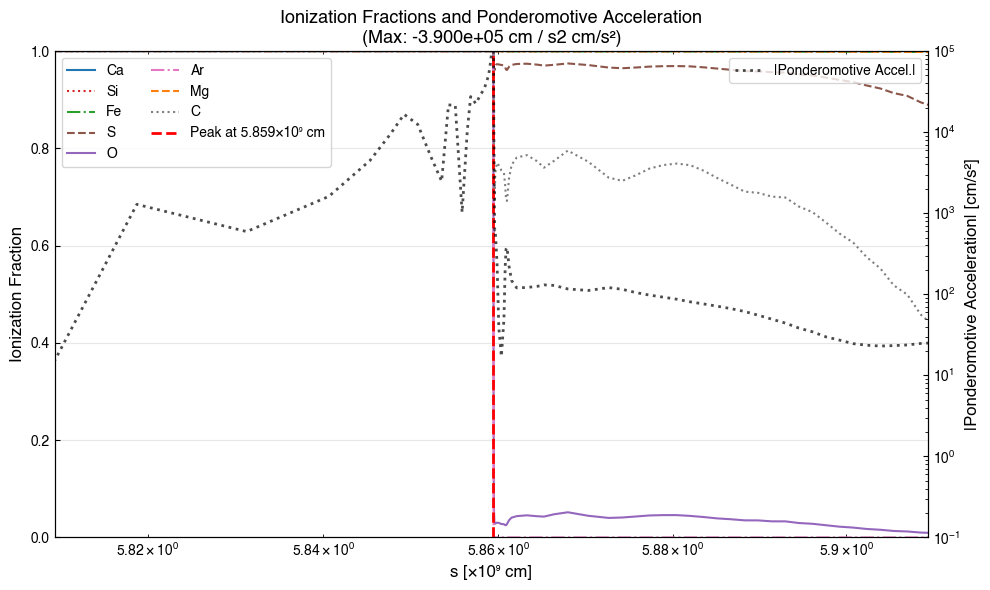

In [338]:
# Calculate maximum ponderomotive acceleration in height range
ponderomotive_accel = alfven_data['ponderomotive_acceleration']
s_values_accel = alfven_data['s_values']

# Define height range (matching the plot range)
# Convert xmax and xmin to cm (they are already in cm from the plot)
xmax_cm = xmax  # 5.8e9 cm
xmin_cm = xmin  # 5.95e9 cm

# Ensure s_values_accel has units
if not hasattr(s_values_accel, 'unit'):
    s_values_accel = s_values_accel * u.cm

# Convert to consistent units for comparison (keep in cm)
s_values_accel_cm = s_values_accel.to(u.cm).value
height_mask = (s_values_accel_cm >= xmax_cm) & (s_values_accel_cm <= xmin_cm)
ponderomotive_accel_in_range = ponderomotive_accel[height_mask]
s_values_in_range = s_values_accel[height_mask]

# Check if we have any data in the range
if len(ponderomotive_accel_in_range) > 0:
    # Find maximum ponderomotive acceleration and its location
    max_ponderomotive_idx = np.argmax(np.abs(ponderomotive_accel_in_range))
    max_ponderomotive_accel = ponderomotive_accel_in_range[max_ponderomotive_idx]
    max_ponderomotive_height = s_values_in_range[max_ponderomotive_idx]

    print(f"Maximum ponderomotive acceleration: {max_ponderomotive_accel:.3e} cm/s²")
    print(f"Location: {max_ponderomotive_height.to(u.cm).value/1e9:.3f} ×10⁹ cm")

    # Get ionization fractions at the peak ponderomotive acceleration location
    print(f"\nIonization fractions at peak ponderomotive acceleration location ({max_ponderomotive_height.to(u.cm).value/1e9:.3f} ×10⁹ cm):")

    # Convert max_ponderomotive_height to same units as s_values for comparison
    max_ponderomotive_height_cm = max_ponderomotive_height.to(u.cm).value
    
    # Ensure s_values is in cm (convert if it has units, otherwise assume it's already in cm)
    if hasattr(s_values, 'unit'):
        s_values_cm_for_comparison = s_values.to(u.cm).value
    else:
        s_values_cm_for_comparison = s_values

    for element in ionization_data.keys():
        # Find closest height index in s_values
        closest_idx = np.argmin(np.abs(s_values_cm_for_comparison - max_ponderomotive_height_cm))
        fraction_at_peak = ionization_data[element][closest_idx]
        print(f"{element}: {fraction_at_peak:.4f}")

    # Get FIP bias at the peak location
    print(f"\nFIP bias at peak ponderomotive acceleration location ({max_ponderomotive_height.to(u.cm).value/1e9:.3f} ×10⁹ cm):")
    for element, data_fip in fip_bias_heights.items():
        if 'right' in data_fip:
            heights_right = np.array(data_fip['right']['heights']) * 1e9  # Convert to cm
            bias_right = np.array(data_fip['right']['bias'])
            # Find closest height index
            closest_idx = np.argmin(np.abs(heights_right - max_ponderomotive_height_cm))
            bias_at_peak = bias_right[closest_idx]
            if oxygen_bias_right is not None:
                bias_normalized = bias_at_peak / oxygen_bias_right[closest_idx]
                print(f"{element}: {bias_at_peak:.3f} (normalized: {bias_normalized:.3f})")
            else:
                print(f"{element}: {bias_at_peak:.3f}")

    # Plot ionization fractions and ponderomotive acceleration around the peak
    fig_ion, ax_ion = plt.subplots(figsize=(10, 6))
    
    # Define a range around the peak for better visualization
    peak_height_cm = max_ponderomotive_height.to(u.cm).value
    plot_min_cm = max(xmax_cm, peak_height_cm - 0.05e9)  # ±0.05×10⁹ cm around peak
    plot_max_cm = min(xmin_cm, peak_height_cm + 0.05e9)
    
    # Convert s_values to cm for plotting (handle units properly)
    if hasattr(s_values, 'unit'):
        s_values_cm = s_values.to(u.cm).value
    else:
        s_values_cm = s_values
    
    # Plot ionization fractions for each element
    for element in ionization_data.keys():
        color = element_colors.get(element, None)
        linestyle = element_linestyles.get(element, '-')
        ax_ion.plot(s_values_cm/1e9, ionization_data[element], 
                   label=element, color=color, linestyle=linestyle, linewidth=1.5)
    
    # Mark the peak location
    ax_ion.axvline(peak_height_cm/1e9, color='red', linestyle='--', linewidth=2, 
                   label=f'Peak at {peak_height_cm/1e9:.3f}×10⁹ cm')
    
    ax_ion.set_xlabel('s [×10⁹ cm]', fontsize=12)
    ax_ion.set_ylabel('Ionization Fraction', fontsize=12)
    ax_ion.set_title(f'Ionization Fractions and Ponderomotive Acceleration\n(Max: {max_ponderomotive_accel:.3e} cm/s²)', 
                     fontsize=13)
    ax_ion.legend(loc='upper left', fontsize=10, ncol=2)
    ax_ion.grid(True, alpha=0.3)
    ax_ion.set_xlim(plot_min_cm/1e9, plot_max_cm/1e9)
    ax_ion.set_ylim(0, 1)
    ax_ion.invert_xaxis()
    ax_ion.set_xscale('log')
    
    # Create second y-axis for ponderomotive acceleration
    ax_accel = ax_ion.twinx()
    
    # Plot ponderomotive acceleration (use absolute value to match the plot)
    ax_accel.plot(s_values_accel_cm/1e9, np.abs(ponderomotive_accel), 
                  color='black', linewidth=2, linestyle=':', alpha=0.7,
                  label='|Ponderomotive Accel.|')
    
    ax_accel.set_ylabel('|Ponderomotive Acceleration| [cm/s²]', fontsize=12)
    ax_accel.legend(loc='upper right', fontsize=10)
    ax_accel.set_xlim(plot_min_cm/1e9, plot_max_cm/1e9)
    ax_accel.set_yscale('log')
    ax_accel.set_ylim(1e-1, 1e5)
    
    plt.tight_layout()
    plt.show()

else:
    print(f"No data found in height range [{xmax_cm/1e9:.3f}, {xmin_cm/1e9:.3f}] ×10⁹ cm")
    print(f"Available height range: [{s_values_accel_cm.min()/1e9:.3f}, {s_values_accel_cm.max()/1e9:.3f}] ×10⁹ cm")


In [ ]:
with open('/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e9_SI_5_CF_15_with_H/test_loop_extra_properties_0.060_0.10_68.pkl', 'rb') as f:
    alfven_data = pickle.load(f)


In [430]:
frequency_of_wave = 0.353



/Users/andysh.to/miniconda3/envs/hydrad-fip/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2133864847.py:129: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_ion_low.set_xticklabels([f'{x/1e9:.1f}' for x in ax9_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2133864847.py:159: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_ion_high.set_xticklabels([f'{x/1e9:.1f}' for x in ax10_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2133864847.py:206: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_fip.set_xticklabels

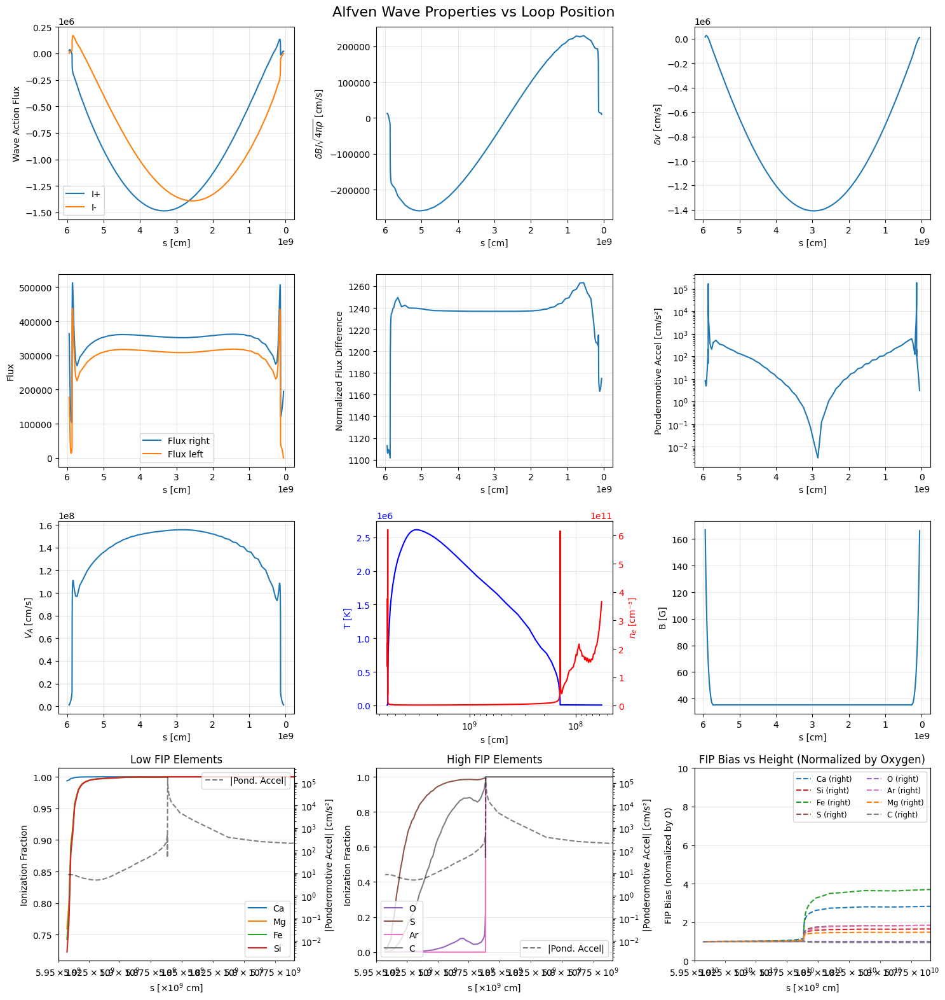

In [480]:
with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H/v_0.013_A_0.20/test_loop_extra_properties_0.013_0.20_1600.pkl', 'rb') as f:
    alfven_data = pickle.load(f)

# Plot various Alfven wave properties vs loop position
# Create a 4x3 grid to include ionization fraction plots
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

s_values = alfven_data['s_values']

# Plot 1: I_plus and I_minus
axes[0].plot(s_values, alfven_data['I_plus'], label='I+')
axes[0].plot(s_values, alfven_data['I_minus'], label='I-')
axes[0].set_ylabel('Wave Action Flux')
axes[0].set_xlabel('s [cm]')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].invert_xaxis()

# Plot 2: delta_B
axes[1].plot(s_values, alfven_data['delta_B_over_sqrt_4pi_rho'])
axes[1].set_ylabel(r'$\delta B / \sqrt{4\pi\rho}$ [cm/s]')
axes[1].set_xlabel('s [cm]')
axes[1].grid(True, alpha=0.3)
axes[1].invert_xaxis()

# Plot 3: delta_v
axes[2].plot(s_values, alfven_data['delta_v'])
axes[2].set_ylabel(r'$\delta v$ [cm/s]')
axes[2].set_xlabel('s [cm]')
axes[2].grid(True, alpha=0.3)
axes[2].invert_xaxis()

# Plot 4: Flux comparison
axes[3].plot(s_values, alfven_data['flux_right'], label='Flux right')
axes[3].plot(s_values, alfven_data['flux_left'], label='Flux left')
axes[3].set_ylabel('Flux')
axes[3].set_xlabel('s [cm]')
axes[3].legend()
axes[3].grid(True, alpha=0.3)
axes[3].invert_xaxis()

# Plot 5: Normalized flux difference
axes[4].plot(s_values, alfven_data['normalized_flux_difference'])
axes[4].set_ylabel('Normalized Flux Difference')
axes[4].set_xlabel('s [cm]')
axes[4].grid(True, alpha=0.3)
axes[4].invert_xaxis()

# Plot 6: Ponderomotive acceleration
axes[5].plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']))
axes[5].set_ylabel('Ponderomotive Accel [cm/s²]')
axes[5].set_xlabel('s [cm]')
axes[5].grid(True, alpha=0.3)
axes[5].set_yscale('log')
axes[5].invert_xaxis()
# axes[5].set_xsca/le('log')

# Plot 7: Alfven speed
axes[6].plot(s_values, alfven_data['VA_s'])
axes[6].set_ylabel(r'$V_A$ [cm/s]')
axes[6].set_xlabel('s [cm]')
axes[6].grid(True, alpha=0.3)
axes[6].invert_xaxis()

# Plot 8: Temperature and density
ax_temp = axes[7]
ax_dens = ax_temp.twinx()
ax_temp.plot(s_values, alfven_data['T'], 'b-', label='T')
ax_dens.plot(s_values, alfven_data['ne'], 'r-', label='ne')
ax_temp.set_ylabel('T [K]', color='b')
ax_dens.set_ylabel(r'$n_e$ [cm⁻³]', color='r')
ax_temp.set_xlabel('s [cm]')
ax_temp.set_xscale('log')
ax_temp.tick_params(axis='y', labelcolor='b')
ax_dens.tick_params(axis='y', labelcolor='r')
ax_temp.grid(True, alpha=0.3)
ax_temp.invert_xaxis()

# Plot 9: Magnetic field
axes[8].plot(s_values, alfven_data['B'])
axes[8].set_ylabel('B [G]')
axes[8].set_xlabel('s [cm]')
axes[8].grid(True, alpha=0.3)
axes[8].invert_xaxis()

# Plot 10: Ionization fraction - Low FIP elements (Ca, Mg, Fe, Si)
ionization_data = alfven_data['ionization_fractions']
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
ax_ion_low = axes[9]
ax_accel_low = ax_ion_low.twinx()

for element in low_fip_elements:
    if element in ionization_data:
        ax_ion_low.plot(s_values, ionization_data[element], label=element)

ax_accel_low.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                  'k--', alpha=0.5, label='|Pond. Accel|')


# Define consistent colors for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

xmin=5.95e9
xmax=5.76e9
ax_ion_low.set_ylabel('Ionization Fraction')
ax_accel_low.set_ylabel('|Ponderomotive Accel| [cm/s²]', color='k')
ax_ion_low.set_xlabel('s [×10$^9$ cm]')
ax_ion_low.set_title('Low FIP Elements')
ax_ion_low.legend(loc='best')
ax_accel_low.legend(loc='best')
ax_ion_low.grid(True, alpha=0.3)
ax_ion_low.invert_xaxis()
ax_ion_low.set_xscale('log')
ax_accel_low.set_yscale('log')
ax_accel_low.tick_params(axis='y', labelcolor='k')
ax_ion_low.set_xlim(left=xmin, right=xmax)  # Zoom into last 1 Mm (1e8 cm)
# Format x-axis ticks to show values divided by 1e9
ax9_xticks = ax_ion_low.get_xticks()
ax_ion_low.set_xticklabels([f'{x/1e9:.1f}' for x in ax9_xticks])

# Plot 11: Ionization fraction - High FIP elements (O, S, Ar)
high_fip_elements = ['O', 'S', 'Ar','C']
ax_ion_high = axes[10]
ax_accel_high = ax_ion_high.twinx()

for element in high_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        ax_ion_high.plot(s_values, ionization_data[element], label=element, color=color)

ax_accel_high.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                   'k--', alpha=0.5, label='|Pond. Accel|')

ax_ion_high.set_ylabel('Ionization Fraction')
ax_accel_high.set_ylabel('|Ponderomotive Accel| [cm/s²]', color='k')
ax_ion_high.set_xlabel('s [×10$^9$ cm]')
ax_ion_high.set_title('High FIP Elements')
ax_ion_high.legend(loc='lower left')
ax_accel_high.legend(loc='lower right')
ax_ion_high.grid(True, alpha=0.3)
ax_ion_high.invert_xaxis()
ax_ion_high.set_xscale('log')
ax_accel_high.set_yscale('log')
ax_accel_high.tick_params(axis='y', labelcolor='k')
ax_ion_high.set_xlim(left=xmin, right=xmax)  # Zoom into last 1 Mm (1e8 cm)
# ax_ion_high.set_ylim(0.99,1)
# Format x-axis ticks to show values divided by 1e9
ax10_xticks = ax_ion_high.get_xticks()
ax_ion_high.set_xticklabels([f'{x/1e9:.1f}' for x in ax10_xticks])
# Hide the last unused subplot
# Plot 12: FIP Bias Heights
ax_fip = axes[11]

# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Plot left footpoint for each element (normalized by oxygen)
# for element, data in fip_bias_heights.items():
#     if 'left' in data:
#         heights_left = np.array(data['left']['heights']) * 1e9  # Convert to cm
#         bias_left = np.array(data['left']['bias'])
#         if oxygen_bias_left is not None and len(bias_left) == len(oxygen_bias_left):
#             bias_left_normalized = bias_left / oxygen_bias_left
#             ax_fip.plot(heights_left, bias_left_normalized, label=f'{element} (left)', linestyle='-')

# Plot right footpoint for each element (normalized by oxygen)
for element, data in fip_bias_heights.items():
    if 'right' in data:
        heights_right = np.array(data['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            ax_fip.plot(heights_right, bias_right_normalized, label=f'{element} (right)', linestyle='--', color=color)

ax_fip.set_xlabel('s [×10$^9$ cm]')
ax_fip.set_ylabel('FIP Bias (normalized by O)')
ax_fip.set_title('FIP Bias vs Height (Normalized by Oxygen)')
ax_fip.legend(loc='best', fontsize='small', ncol=2)
ax_fip.grid(True, alpha=0.3)
# ax_fip.set_yscale('log')
ax_fip.invert_xaxis()
ax_fip.set_xscale('log')
ax_fip.set_ylim(0,10)
# ax_fip.set_xlim(left=59.2e9, right=58e9)  # Zoom into last 1 Mm (1e8 cm)
ax_fip.set_xlim(left=xmin*10, right=xmax*10)  # Zoom into last 1 Mm (1e8 cm)
# Format x-axis ticks to show values divided by 1e9
ax_fip_xticks = ax_fip.get_xticks()
ax_fip.set_xticklabels([f'{x/1e9:.1f}' for x in ax_fip_xticks])

plt.suptitle('Alfven Wave Properties vs Loop Position', fontsize=16)
plt.tight_layout()
plt.show()


/Users/andysh.to/miniconda3/envs/hydrad-fip/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2171211199.py:131: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_ion_low.set_xticklabels([f'{x/1e9:.1f}' for x in ax9_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2171211199.py:161: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_ion_high.set_xticklabels([f'{x/1e9:.1f}' for x in ax10_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2171211199.py:208: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_fip.set_xticklabels

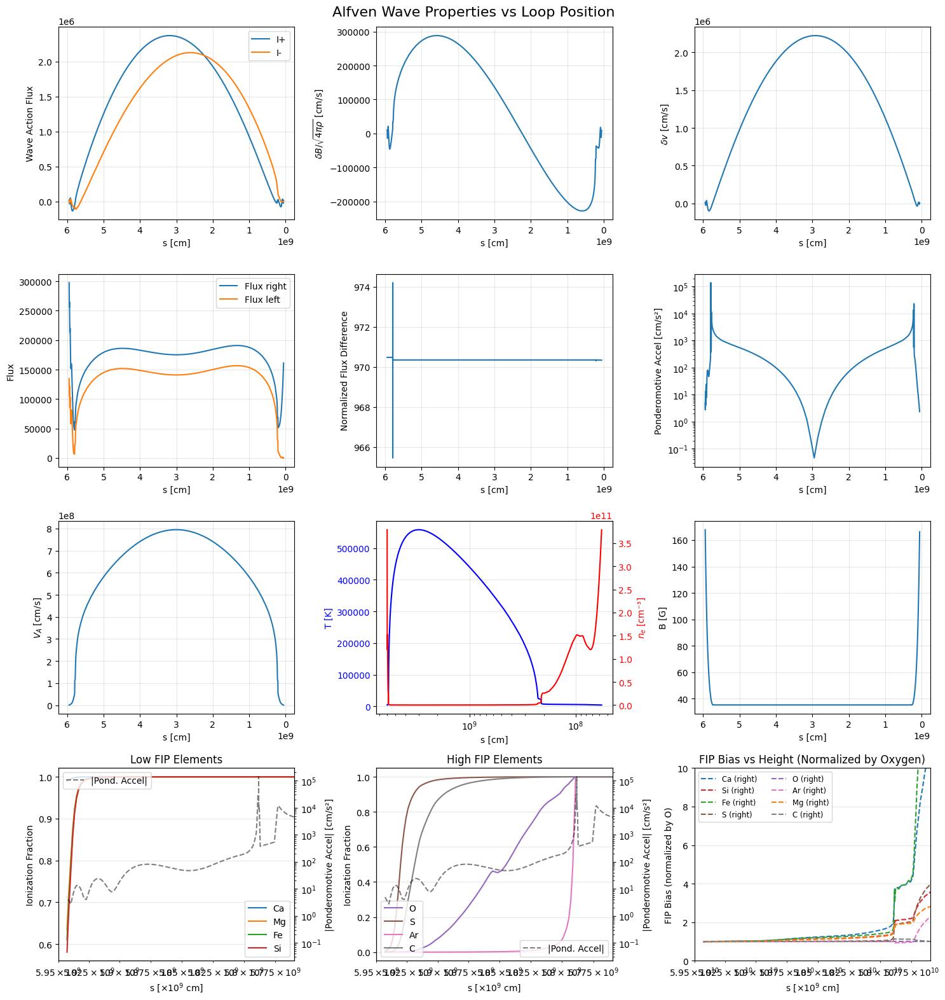

In [508]:
frequency = 0.065
amplitude = 0.18
with open(f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H/v_{frequency:.3f}_A_{amplitude:.2f}/test_loop_extra_properties_{frequency:.3f}_{amplitude:.2f}_0.pkl', 'rb') as f:
    alfven_data = pickle.load(f)

# Plot various Alfven wave properties vs loop position
# Create a 4x3 grid to include ionization fraction plots
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

s_values = alfven_data['s_values']

# Plot 1: I_plus and I_minus
axes[0].plot(s_values, alfven_data['I_plus'], label='I+')
axes[0].plot(s_values, alfven_data['I_minus'], label='I-')
axes[0].set_ylabel('Wave Action Flux')
axes[0].set_xlabel('s [cm]')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].invert_xaxis()

# Plot 2: delta_B
axes[1].plot(s_values, alfven_data['delta_B_over_sqrt_4pi_rho'])
axes[1].set_ylabel(r'$\delta B / \sqrt{4\pi\rho}$ [cm/s]')
axes[1].set_xlabel('s [cm]')
axes[1].grid(True, alpha=0.3)
axes[1].invert_xaxis()

# Plot 3: delta_v
axes[2].plot(s_values, alfven_data['delta_v'])
axes[2].set_ylabel(r'$\delta v$ [cm/s]')
axes[2].set_xlabel('s [cm]')
axes[2].grid(True, alpha=0.3)
axes[2].invert_xaxis()

# Plot 4: Flux comparison
axes[3].plot(s_values, alfven_data['flux_right'], label='Flux right')
axes[3].plot(s_values, alfven_data['flux_left'], label='Flux left')
axes[3].set_ylabel('Flux')
axes[3].set_xlabel('s [cm]')
axes[3].legend()
axes[3].grid(True, alpha=0.3)
axes[3].invert_xaxis()

# Plot 5: Normalized flux difference
axes[4].plot(s_values, alfven_data['normalized_flux_difference'])
axes[4].set_ylabel('Normalized Flux Difference')
axes[4].set_xlabel('s [cm]')
axes[4].grid(True, alpha=0.3)
axes[4].invert_xaxis()

# Plot 6: Ponderomotive acceleration
axes[5].plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']))
axes[5].set_ylabel('Ponderomotive Accel [cm/s²]')
axes[5].set_xlabel('s [cm]')
axes[5].grid(True, alpha=0.3)
axes[5].set_yscale('log')
axes[5].invert_xaxis()
# axes[5].set_xsca/le('log')

# Plot 7: Alfven speed
axes[6].plot(s_values, alfven_data['VA_s'])
axes[6].set_ylabel(r'$V_A$ [cm/s]')
axes[6].set_xlabel('s [cm]')
axes[6].grid(True, alpha=0.3)
axes[6].invert_xaxis()

# Plot 8: Temperature and density
ax_temp = axes[7]
ax_dens = ax_temp.twinx()
ax_temp.plot(s_values, alfven_data['T'], 'b-', label='T')
ax_dens.plot(s_values, alfven_data['ne'], 'r-', label='ne')
ax_temp.set_ylabel('T [K]', color='b')
ax_dens.set_ylabel(r'$n_e$ [cm⁻³]', color='r')
ax_temp.set_xlabel('s [cm]')
ax_temp.set_xscale('log')
ax_temp.tick_params(axis='y', labelcolor='b')
ax_dens.tick_params(axis='y', labelcolor='r')
ax_temp.grid(True, alpha=0.3)
ax_temp.invert_xaxis()

# Plot 9: Magnetic field
axes[8].plot(s_values, alfven_data['B'])
axes[8].set_ylabel('B [G]')
axes[8].set_xlabel('s [cm]')
axes[8].grid(True, alpha=0.3)
axes[8].invert_xaxis()

# Plot 10: Ionization fraction - Low FIP elements (Ca, Mg, Fe, Si)
ionization_data = alfven_data['ionization_fractions']
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
ax_ion_low = axes[9]
ax_accel_low = ax_ion_low.twinx()

for element in low_fip_elements:
    if element in ionization_data:
        ax_ion_low.plot(s_values, ionization_data[element], label=element)

ax_accel_low.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                  'k--', alpha=0.5, label='|Pond. Accel|')


# Define consistent colors for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

xmin=5.95e9
xmax=5.76e9
ax_ion_low.set_ylabel('Ionization Fraction')
ax_accel_low.set_ylabel('|Ponderomotive Accel| [cm/s²]', color='k')
ax_ion_low.set_xlabel('s [×10$^9$ cm]')
ax_ion_low.set_title('Low FIP Elements')
ax_ion_low.legend(loc='best')
ax_accel_low.legend(loc='best')
ax_ion_low.grid(True, alpha=0.3)
ax_ion_low.invert_xaxis()
ax_ion_low.set_xscale('log')
ax_accel_low.set_yscale('log')
ax_accel_low.tick_params(axis='y', labelcolor='k')
ax_ion_low.set_xlim(left=xmin, right=xmax)  # Zoom into last 1 Mm (1e8 cm)
# Format x-axis ticks to show values divided by 1e9
ax9_xticks = ax_ion_low.get_xticks()
ax_ion_low.set_xticklabels([f'{x/1e9:.1f}' for x in ax9_xticks])

# Plot 11: Ionization fraction - High FIP elements (O, S, Ar)
high_fip_elements = ['O', 'S', 'Ar','C']
ax_ion_high = axes[10]
ax_accel_high = ax_ion_high.twinx()

for element in high_fip_elements:
    if element in ionization_data:
        color = element_colors.get(element, None)
        ax_ion_high.plot(s_values, ionization_data[element], label=element, color=color)

ax_accel_high.plot(s_values, np.abs(alfven_data['ponderomotive_acceleration']), 
                   'k--', alpha=0.5, label='|Pond. Accel|')

ax_ion_high.set_ylabel('Ionization Fraction')
ax_accel_high.set_ylabel('|Ponderomotive Accel| [cm/s²]', color='k')
ax_ion_high.set_xlabel('s [×10$^9$ cm]')
ax_ion_high.set_title('High FIP Elements')
ax_ion_high.legend(loc='lower left')
ax_accel_high.legend(loc='lower right')
ax_ion_high.grid(True, alpha=0.3)
ax_ion_high.invert_xaxis()
ax_ion_high.set_xscale('log')
ax_accel_high.set_yscale('log')
ax_accel_high.tick_params(axis='y', labelcolor='k')
ax_ion_high.set_xlim(left=xmin, right=xmax)  # Zoom into last 1 Mm (1e8 cm)
# ax_ion_high.set_ylim(0.99,1)
# Format x-axis ticks to show values divided by 1e9
ax10_xticks = ax_ion_high.get_xticks()
ax_ion_high.set_xticklabels([f'{x/1e9:.1f}' for x in ax10_xticks])
# Hide the last unused subplot
# Plot 12: FIP Bias Heights
ax_fip = axes[11]

# Extract the fip_bias_heights data
fip_bias_heights = alfven_data['fip_bias_heights']

# Get oxygen data for normalization (right footpoint)
oxygen_bias_right = None
oxygen_heights_right = None
if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
    oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
    oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])

# Plot left footpoint for each element (normalized by oxygen)
# for element, data in fip_bias_heights.items():
#     if 'left' in data:
#         heights_left = np.array(data['left']['heights']) * 1e9  # Convert to cm
#         bias_left = np.array(data['left']['bias'])
#         if oxygen_bias_left is not None and len(bias_left) == len(oxygen_bias_left):
#             bias_left_normalized = bias_left / oxygen_bias_left
#             ax_fip.plot(heights_left, bias_left_normalized, label=f'{element} (left)', linestyle='-')

# Plot right footpoint for each element (normalized by oxygen)
for element, data in fip_bias_heights.items():
    if 'right' in data:
        heights_right = np.array(data['right']['heights']) * 1e9  # Convert to cm
        bias_right = np.array(data['right']['bias'])
        if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
            bias_right_normalized = bias_right / oxygen_bias_right
            color = element_colors.get(element, None)
            ax_fip.plot(heights_right, bias_right_normalized, label=f'{element} (right)', linestyle='--', color=color)

ax_fip.set_xlabel('s [×10$^9$ cm]')
ax_fip.set_ylabel('FIP Bias (normalized by O)')
ax_fip.set_title('FIP Bias vs Height (Normalized by Oxygen)')
ax_fip.legend(loc='best', fontsize='small', ncol=2)
ax_fip.grid(True, alpha=0.3)
# ax_fip.set_yscale('log')
ax_fip.invert_xaxis()
ax_fip.set_xscale('log')
ax_fip.set_ylim(0,10)
# ax_fip.set_xlim(left=59.2e9, right=58e9)  # Zoom into last 1 Mm (1e8 cm)
ax_fip.set_xlim(left=xmin*10, right=xmax*10)  # Zoom into last 1 Mm (1e8 cm)
# Format x-axis ticks to show values divided by 1e9
ax_fip_xticks = ax_fip.get_xticks()
ax_fip.set_xticklabels([f'{x/1e9:.1f}' for x in ax_fip_xticks])

plt.suptitle('Alfven Wave Properties vs Loop Position', fontsize=16)
plt.tight_layout()
plt.show()


In [432]:
import glob

In [433]:
files = sorted(glob.glob('/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e9_SI_5_CF_15_with_H/v_*_A_0.10/'))

In [437]:
[f.replace('/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e9_SI_5_CF_15_with_H/','').replace('_A_0.10/','').replace('v_','') for f in files]

['0.010',
 '0.030',
 '0.050',
 '0.071',
 '0.091',
 '0.111',
 '0.131',
 '0.151',
 '0.172',
 '0.192',
 '0.212',
 '0.232',
 '0.252',
 '0.273',
 '0.293',
 '0.313',
 '0.333',
 '0.353',
 '0.374',
 '0.394',
 '0.414',
 '0.434',
 '0.454',
 '0.475']

/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4165298964.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4165298964.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4165298964.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4165298964.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or usin

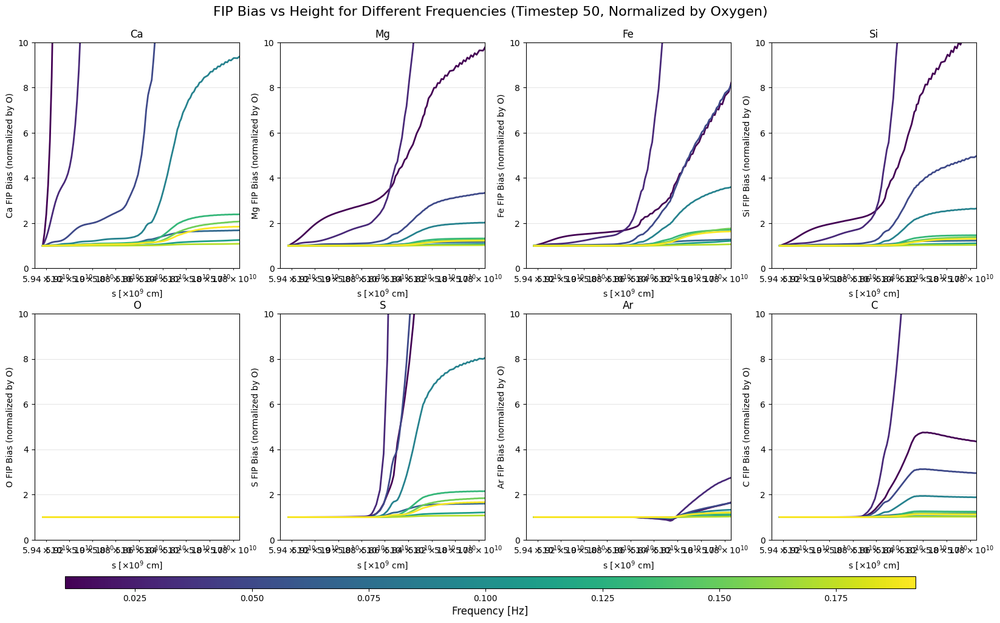

In [464]:
# Plot FIP bias for different frequencies at final timestep
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np

# Define frequencies to plot
frequencies = [float(f.replace('/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e9_SI_5_CF_15_with_H/','').replace('_A_0.10/','').replace('v_','')) for f in files][0:10]  # 50 frequencies from 0.01 to 1.0 Hz
n_frequencies = len(frequencies)

# Create colormap for frequencies
freq_colors = cm.viridis(np.linspace(0, 1, n_frequencies))

# Define consistent colors for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

# Define element groups
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
high_fip_elements = ['O', 'S', 'Ar', 'C']
all_elements = low_fip_elements + high_fip_elements

# Create figure with separate subplot for each element
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

xmin = 5.95e9
xmax = 5.775e9

# Plot each element in its own subplot
for elem_idx, element in enumerate(all_elements):
    ax = axes[elem_idx]
    
    for freq_idx, frequency in enumerate(frequencies):
        # Load data for this frequency at timestep 50
        file_path = f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e9_SI_5_CF_15_with_H/v_{frequency:.3f}_A_0.10/test_loop_extra_properties_{frequency:.3f}_0.10_54.pkl'
        
        try:
            with open(file_path, 'rb') as f:
                alfven_data = pickle.load(f)
            
            # Extract FIP bias data
            fip_bias_heights = alfven_data['fip_bias_heights']
            
            # Get oxygen data for normalization (right footpoint)
            oxygen_bias_right = None
            if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
                oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])
            
            # Plot this element's FIP bias (normalized by oxygen)
            if element in fip_bias_heights and 'right' in fip_bias_heights[element]:
                heights_right = np.array(fip_bias_heights[element]['right']['heights']) * 1e9  # Convert to cm
                bias_right = np.array(fip_bias_heights[element]['right']['bias'])
                
                if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
                    bias_right_normalized = bias_right / oxygen_bias_right
                    ax.plot(heights_right, bias_right_normalized, 
                           color=freq_colors[freq_idx], alpha=1, linewidth=2)
        
        except FileNotFoundError:
            continue
    
    # Format subplot
    ax.set_xlabel('s [×10$^9$ cm]')
    ax.set_ylabel(f'{element} FIP Bias (normalized by O)')
    ax.set_title(f'{element}')
    ax.grid(True, alpha=0.3)
    ax.invert_xaxis()
    ax.set_xscale('log')
    ax.set_ylim(0, 10)
    ax.set_xlim(left=xmin*10, right=xmax*10)
    
    # Format x-axis ticks
    ax_xticks = ax.get_xticks()
    ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])

# Add colorbar for frequencies at the bottom
sm = cm.ScalarMappable(cmap=cm.viridis, norm=plt.Normalize(vmin=frequencies[0], vmax=frequencies[-1]))
sm.set_array([])
cbar_ax = fig.add_axes([0.15, 0.02, 0.7, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Frequency [Hz]', fontsize=12)

plt.suptitle('FIP Bias vs Height for Different Frequencies (Timestep 50, Normalized by Oxygen)', fontsize=16)
plt.subplots_adjust(bottom=0.1, top=0.92)  # Leave space for colorbar at bottom
plt.show()


/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4082896163.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4082896163.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4082896163.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/4082896163.py:82: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or usin

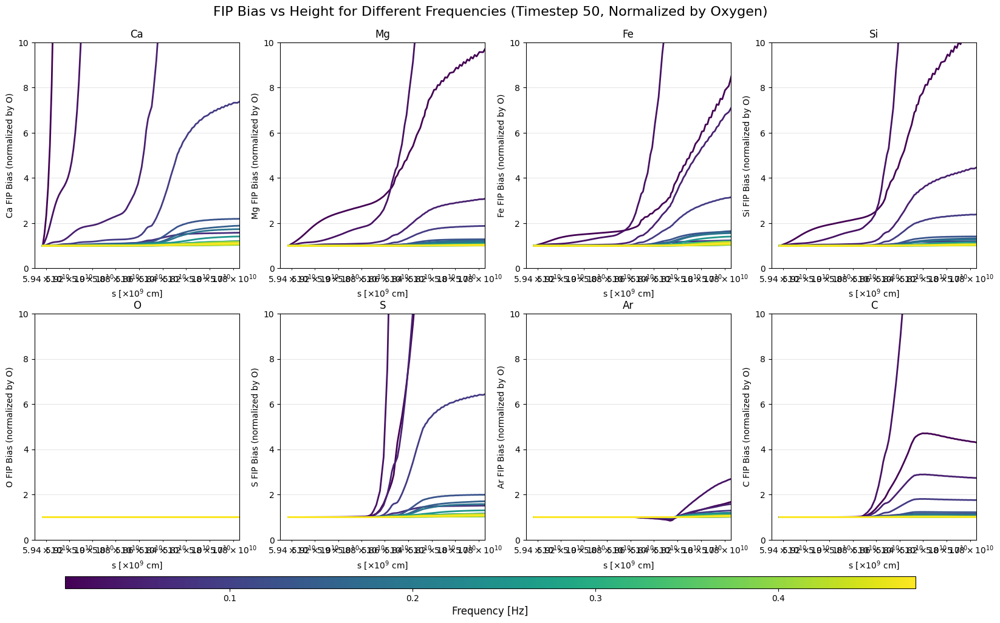

In [450]:
# Plot FIP bias for different frequencies at final timestep
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np

# Define frequencies to plot
frequencies = [float(f.replace('/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e9_SI_5_CF_15_with_H/','').replace('_A_0.10/','').replace('v_','')) for f in files]  # 50 frequencies from 0.01 to 1.0 Hz
n_frequencies = len(frequencies)

# Create colormap for frequencies
freq_colors = cm.viridis(np.linspace(0, 1, n_frequencies))

# Define consistent colors for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

# Define element groups
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
high_fip_elements = ['O', 'S', 'Ar', 'C']
all_elements = low_fip_elements + high_fip_elements

# Create figure with separate subplot for each element
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

xmin = 5.95e9
xmax = 5.775e9

# Plot each element in its own subplot
for elem_idx, element in enumerate(all_elements):
    ax = axes[elem_idx]
    
    for freq_idx, frequency in enumerate(frequencies):
        # Load data for this frequency at timestep 50
        file_path = f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e9_SI_5_CF_15_with_H/v_{frequency:.3f}_A_0.10/test_loop_extra_properties_{frequency:.3f}_0.10_54.pkl'
        
        try:
            with open(file_path, 'rb') as f:
                alfven_data = pickle.load(f)
            
            # Extract FIP bias data
            fip_bias_heights = alfven_data['fip_bias_heights']
            
            # Get oxygen data for normalization (right footpoint)
            oxygen_bias_right = None
            if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
                oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])
            
            # Plot this element's FIP bias (normalized by oxygen)
            if element in fip_bias_heights and 'right' in fip_bias_heights[element]:
                heights_right = np.array(fip_bias_heights[element]['right']['heights']) * 1e9  # Convert to cm
                bias_right = np.array(fip_bias_heights[element]['right']['bias'])
                
                if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
                    bias_right_normalized = bias_right / oxygen_bias_right
                    ax.plot(heights_right, bias_right_normalized, 
                           color=freq_colors[freq_idx], alpha=1, linewidth=2)
        
        except FileNotFoundError:
            continue
    
    # Format subplot
    ax.set_xlabel('s [×10$^9$ cm]')
    ax.set_ylabel(f'{element} FIP Bias (normalized by O)')
    ax.set_title(f'{element}')
    ax.grid(True, alpha=0.3)
    ax.invert_xaxis()
    ax.set_xscale('log')
    ax.set_ylim(0, 10)
    ax.set_xlim(left=xmin*10, right=xmax*10)
    
    # Format x-axis ticks
    ax_xticks = ax.get_xticks()
    ax.set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])

# Add colorbar for frequencies at the bottom
sm = cm.ScalarMappable(cmap=cm.viridis, norm=plt.Normalize(vmin=frequencies[0], vmax=frequencies[-1]))
sm.set_array([])
cbar_ax = fig.add_axes([0.15, 0.02, 0.7, 0.02])  # [left, bottom, width, height]
cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Frequency [Hz]', fontsize=12)

plt.suptitle('FIP Bias vs Height for Different Frequencies (Timestep 50, Normalized by Oxygen)', fontsize=16)
plt.subplots_adjust(bottom=0.1, top=0.92)  # Leave space for colorbar at bottom
plt.show()


/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2842088175.py:148: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2842088175.py:148: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2842088175.py:148: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/2842088175.py:148: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after 

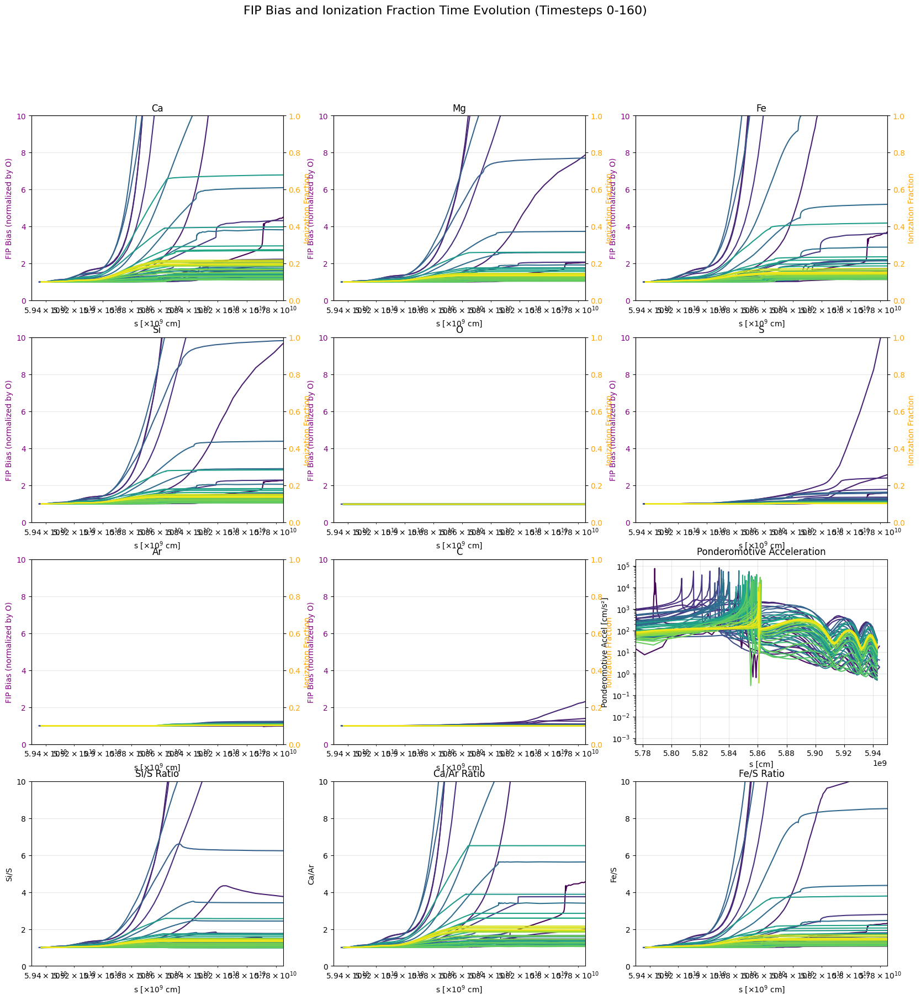

In [460]:
# Plot time evolution of FIP bias for different timesteps
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np

# Define time steps to plot
max_time = 1200
time_steps = range(0, max_time, 20)  # 0 to 70
n_steps = max_time

# Create colormaps - one for FIP bias, one for ionization fraction
fip_colors = cm.viridis(np.linspace(0, 1, n_steps))
ion_colors = cm.plasma(np.linspace(0, 1, n_steps))

# Define consistent colors for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

# Define element groups
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
high_fip_elements = ['O', 'S', 'Ar', 'C']

# Create figure with separate subplots for each element plus ponderomotive acceleration and ratios
fig, axes = plt.subplots(4, 3, figsize=(20, 20))
axes = axes.flatten()

# Create twin axes for ionization fraction (only for first 8 element plots)
axes_ion = [ax.twinx() for ax in axes[:8]]

xmin = 5.95e9
xmax = 5.775e9

# Combine all elements for plotting
all_elements = low_fip_elements + high_fip_elements

for time_idx in time_steps:
    # Load data for this timestep
    file_path = f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he1.8e8x5_SI_7_CF_5_train_with_H/test_loop_extra_properties_0.060_0.10_{time_idx}.pkl'
    
    try:
        with open(file_path, 'rb') as f:
            alfven_data = pickle.load(f)
        
        fip_bias_heights = alfven_data['fip_bias_heights']
        ionization_data = alfven_data['ionization_fractions']
        ponderomotive_accel = alfven_data['ponderomotive_acceleration']
        s_values = alfven_data['s_values']
        
        # Get oxygen data for normalization (right footpoint)
        oxygen_bias_right = None
        oxygen_heights_right = None
        if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
            oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
            oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])
        
        # Plot each element in its own subplot
        for i, element in enumerate(all_elements):
            # Plot FIP bias
            if element in fip_bias_heights and 'right' in fip_bias_heights[element]:
                heights_right = np.array(fip_bias_heights[element]['right']['heights']) * 1e9  # Convert to cm
                bias_right = np.array(fip_bias_heights[element]['right']['bias'])
                
                if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
                    bias_right_normalized = bias_right / oxygen_bias_right
                    axes[i].plot(heights_right, bias_right_normalized, 
                               color=fip_colors[time_idx], alpha=1, linewidth=1.5)
            
            # Plot ionization fraction on twin axis
            if element in ionization_data:
                axes_ion[i].plot(s_values, ionization_data[element], 
                               color=ion_colors[time_idx], alpha=1, linewidth=1.5, linestyle='--')
        
        # Plot ponderomotive acceleration in subplot 8
        axes[8].plot(s_values, np.abs(ponderomotive_accel), 
                    color=fip_colors[time_idx], alpha=1, linewidth=1.5)
        
        # Plot element ratios in subplots 9, 10, 11
        # Si/S ratio
        if 'Si' in fip_bias_heights and 'S' in fip_bias_heights:
            if 'right' in fip_bias_heights['Si'] and 'right' in fip_bias_heights['S']:
                si_heights = np.array(fip_bias_heights['Si']['right']['heights']) * 1e9
                si_bias = np.array(fip_bias_heights['Si']['right']['bias'])
                s_heights = np.array(fip_bias_heights['S']['right']['heights']) * 1e9
                s_bias = np.array(fip_bias_heights['S']['right']['bias'])
                
                if len(si_bias) == len(s_bias):
                    si_s_ratio = si_bias / s_bias
                    axes[9].plot(si_heights, si_s_ratio, 
                               color=fip_colors[time_idx], alpha=1, linewidth=1.5)
        
        # Ca/Ar ratio
        if 'Ca' in fip_bias_heights and 'Ar' in fip_bias_heights:
            if 'right' in fip_bias_heights['Ca'] and 'right' in fip_bias_heights['Ar']:
                ca_heights = np.array(fip_bias_heights['Ca']['right']['heights']) * 1e9
                ca_bias = np.array(fip_bias_heights['Ca']['right']['bias'])
                ar_heights = np.array(fip_bias_heights['Ar']['right']['heights']) * 1e9
                ar_bias = np.array(fip_bias_heights['Ar']['right']['bias'])
                
                if len(ca_bias) == len(ar_bias):
                    ca_ar_ratio = ca_bias / ar_bias
                    axes[10].plot(ca_heights, ca_ar_ratio, 
                               color=fip_colors[time_idx], alpha=1, linewidth=1.5)
        
        # Fe/S ratio
        if 'Fe' in fip_bias_heights and 'S' in fip_bias_heights:
            if 'right' in fip_bias_heights['Fe'] and 'right' in fip_bias_heights['S']:
                fe_heights = np.array(fip_bias_heights['Fe']['right']['heights']) * 1e9
                fe_bias = np.array(fip_bias_heights['Fe']['right']['bias'])
                s_heights = np.array(fip_bias_heights['S']['right']['heights']) * 1e9
                s_bias = np.array(fip_bias_heights['S']['right']['bias'])
                
                if len(fe_bias) == len(s_bias):
                    fe_s_ratio = fe_bias / s_bias
                    axes[11].plot(fe_heights, fe_s_ratio, 
                               color=fip_colors[time_idx], alpha=1, linewidth=1.5)
    
    except FileNotFoundError:
        print(f"File not found for timestep {time_idx}")
        continue

# Configure each subplot for elements
for i, element in enumerate(all_elements):
    axes[i].set_xlabel('s [×10$^9$ cm]')
    axes[i].set_ylabel('FIP Bias (normalized by O)', color='purple')
    axes[i].set_title(f'{element}')
    axes[i].grid(True, alpha=0.3)
    axes[i].invert_xaxis()
    axes[i].set_xscale('log')
    axes[i].set_ylim(0, 10)
    axes[i].set_xlim(left=xmin*10, right=xmax*10)
    axes[i].tick_params(axis='y', labelcolor='purple')
    
    # Configure ionization fraction axis
    axes_ion[i].set_ylabel('Ionization Fraction', color='orange')
    axes_ion[i].set_ylim(0, 1)
    axes_ion[i].tick_params(axis='y', labelcolor='orange')
    
    # Format x-axis ticks
    ax_xticks = axes[i].get_xticks()
    axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])

# Configure ponderomotive acceleration subplot
axes[8].set_xlabel('s [cm]')
axes[8].set_ylabel('Ponderomotive Accel [cm/s²]')
axes[8].set_title('Ponderomotive Acceleration')
axes[8].grid(True, alpha=0.3)
axes[8].set_yscale('log')
axes[8].set_xlim(left=xmin, right=xmax)
axes[8].invert_xaxis()

# Configure ratio subplots
ratio_configs = [
    (9, 'Si/S', 'Si/S Ratio'),
    (10, 'Ca/Ar', 'Ca/Ar Ratio'),
    (11, 'Fe/S', 'Fe/S Ratio')
]

for idx, label, title in ratio_configs:
    axes[idx].set_xlabel('s [×10$^9$ cm]')
    axes[idx].set_ylabel(label)
    axes[idx].set_title(title)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].invert_xaxis()
    axes[idx].set_xscale('log')
    axes[idx].set_ylim(0, 10)
    axes[idx].set_xlim(left=xmin*10, right=xmax*10)
    
    # Format x-axis ticks
    ax_xticks = axes[idx].get_xticks()
    axes[idx].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])

# Add colorbars to show time evolution
sm_fip = cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=0, vmax=160))
sm_fip.set_array([])
# cbar_fip = plt.colorbar(sm_fip, ax=axes, orientation='vertical', pad=0.02, aspect=30)
# cbar_fip.set_label('Time Step (FIP Bias - solid)', rotation=270, labelpad=20)

sm_ion = cm.ScalarMappable(cmap='plasma', norm=plt.Normalize(vmin=0, vmax=160))
sm_ion.set_array([])
# cbar_ion = plt.colorbar(sm_ion, ax=axes_ion, orientation='vertical', pad=0.08, aspect=30)
# cbar_ion.set_label('Time Step (Ion Frac - dashed)', rotation=270, labelpad=20)

plt.suptitle('FIP Bias and Ionization Fraction Time Evolution (Timesteps 0-160)', fontsize=16)
plt.subplots_adjust(right=0.9)  # Leave space for colorbar at bottom
plt.show()


/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/1379334637.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/1379334637.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/1379334637.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])
/var/folders/6w/c91jbrwd1k501xpqgh_czqbmvjj465/T/ipykernel_46192/1379334637.py:147: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after 

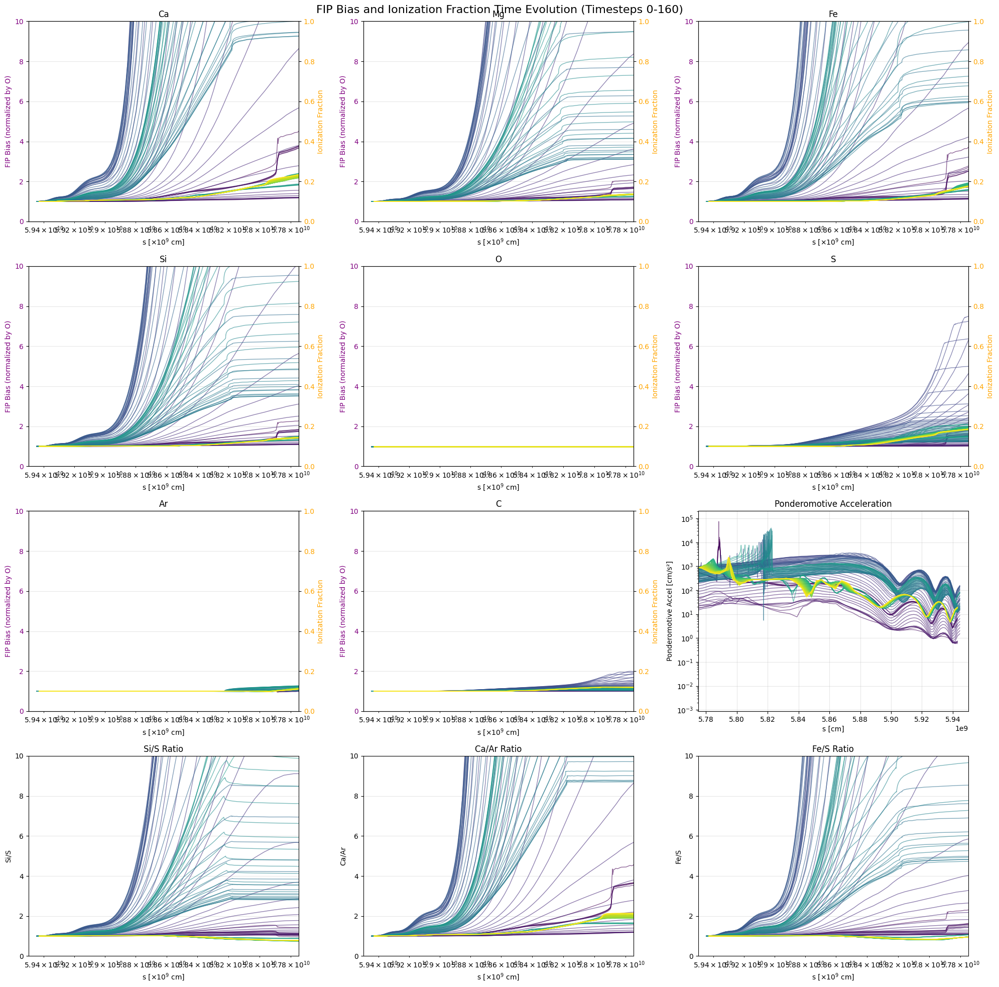

In [396]:
# Plot time evolution of FIP bias for different timesteps
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np

# Define time steps to plot
time_steps = range(0, 160)  # 0 to 70
n_steps = len(time_steps)

# Create colormaps - one for FIP bias, one for ionization fraction
fip_colors = cm.viridis(np.linspace(0, 1, n_steps))
ion_colors = cm.plasma(np.linspace(0, 1, n_steps))

# Define consistent colors for each element
element_colors = {
    'Ca': 'C0',  # blue
    'Mg': 'C1',  # orange
    'Fe': 'C2',  # green
    'Si': 'C3',  # red
    'O': 'C4',   # purple
    'S': 'C5',   # brown
    'Ar': 'C6',  # pink
    'C': 'C7'    # gray
}

# Define element groups
low_fip_elements = ['Ca', 'Mg', 'Fe', 'Si']
high_fip_elements = ['O', 'S', 'Ar', 'C']

# Create figure with separate subplots for each element plus ponderomotive acceleration and ratios
fig, axes = plt.subplots(4, 3, figsize=(20, 20))
axes = axes.flatten()

# Create twin axes for ionization fraction (only for first 8 element plots)
axes_ion = [ax.twinx() for ax in axes[:8]]

xmin = 5.95e9
xmax = 5.775e9

# Combine all elements for plotting
all_elements = low_fip_elements + high_fip_elements

for time_idx in time_steps:
    # Load data for this timestep
    file_path = f'/Users/andysh.to/Script/Python_Script/alfven_loop_SM/results/HYDRAD_flare_LL6e9_he6e8_SI_5_CF_15_with_H/test_loop_extra_properties_0.060_0.10_{time_idx}.pkl'
    
    try:
        with open(file_path, 'rb') as f:
            alfven_data = pickle.load(f)
        
        fip_bias_heights = alfven_data['fip_bias_heights']
        ionization_data = alfven_data['ionization_fractions']
        ponderomotive_accel = alfven_data['ponderomotive_acceleration']
        s_values = alfven_data['s_values']
        
        # Get oxygen data for normalization (right footpoint)
        oxygen_bias_right = None
        oxygen_heights_right = None
        if 'O' in fip_bias_heights and 'right' in fip_bias_heights['O']:
            oxygen_heights_right = np.array(fip_bias_heights['O']['right']['heights']) * 1e9  # Convert to cm
            oxygen_bias_right = np.array(fip_bias_heights['O']['right']['bias'])
        
        # Plot each element in its own subplot
        for i, element in enumerate(all_elements):
            # Plot FIP bias
            if element in fip_bias_heights and 'right' in fip_bias_heights[element]:
                heights_right = np.array(fip_bias_heights[element]['right']['heights']) * 1e9  # Convert to cm
                bias_right = np.array(fip_bias_heights[element]['right']['bias'])
                
                if oxygen_bias_right is not None and len(bias_right) == len(oxygen_bias_right):
                    bias_right_normalized = bias_right / oxygen_bias_right
                    axes[i].plot(heights_right, bias_right_normalized, 
                               color=fip_colors[time_idx], alpha=0.6, linewidth=1)
            
            # Plot ionization fraction on twin axis
            if element in ionization_data:
                axes_ion[i].plot(s_values, ionization_data[element], 
                               color=ion_colors[time_idx], alpha=0.6, linewidth=1, linestyle='--')
        
        # Plot ponderomotive acceleration in subplot 8
        axes[8].plot(s_values, np.abs(ponderomotive_accel), 
                    color=fip_colors[time_idx], alpha=0.6, linewidth=1)
        
        # Plot element ratios in subplots 9, 10, 11
        # Si/S ratio
        if 'Si' in fip_bias_heights and 'S' in fip_bias_heights:
            if 'right' in fip_bias_heights['Si'] and 'right' in fip_bias_heights['S']:
                si_heights = np.array(fip_bias_heights['Si']['right']['heights']) * 1e9
                si_bias = np.array(fip_bias_heights['Si']['right']['bias'])
                s_heights = np.array(fip_bias_heights['S']['right']['heights']) * 1e9
                s_bias = np.array(fip_bias_heights['S']['right']['bias'])
                
                if len(si_bias) == len(s_bias):
                    si_s_ratio = si_bias / s_bias
                    axes[9].plot(si_heights, si_s_ratio, 
                               color=fip_colors[time_idx], alpha=0.6, linewidth=1)
        
        # Ca/Ar ratio
        if 'Ca' in fip_bias_heights and 'Ar' in fip_bias_heights:
            if 'right' in fip_bias_heights['Ca'] and 'right' in fip_bias_heights['Ar']:
                ca_heights = np.array(fip_bias_heights['Ca']['right']['heights']) * 1e9
                ca_bias = np.array(fip_bias_heights['Ca']['right']['bias'])
                ar_heights = np.array(fip_bias_heights['Ar']['right']['heights']) * 1e9
                ar_bias = np.array(fip_bias_heights['Ar']['right']['bias'])
                
                if len(ca_bias) == len(ar_bias):
                    ca_ar_ratio = ca_bias / ar_bias
                    axes[10].plot(ca_heights, ca_ar_ratio, 
                               color=fip_colors[time_idx], alpha=0.6, linewidth=1)
        
        # Fe/S ratio
        if 'Fe' in fip_bias_heights and 'S' in fip_bias_heights:
            if 'right' in fip_bias_heights['Fe'] and 'right' in fip_bias_heights['S']:
                fe_heights = np.array(fip_bias_heights['Fe']['right']['heights']) * 1e9
                fe_bias = np.array(fip_bias_heights['Fe']['right']['bias'])
                s_heights = np.array(fip_bias_heights['S']['right']['heights']) * 1e9
                s_bias = np.array(fip_bias_heights['S']['right']['bias'])
                
                if len(fe_bias) == len(s_bias):
                    fe_s_ratio = fe_bias / s_bias
                    axes[11].plot(fe_heights, fe_s_ratio, 
                               color=fip_colors[time_idx], alpha=0.6, linewidth=1)
    
    except FileNotFoundError:
        print(f"File not found for timestep {time_idx}")
        continue

# Configure each subplot for elements
for i, element in enumerate(all_elements):
    axes[i].set_xlabel('s [×10$^9$ cm]')
    axes[i].set_ylabel('FIP Bias (normalized by O)', color='purple')
    axes[i].set_title(f'{element}')
    axes[i].grid(True, alpha=0.3)
    axes[i].invert_xaxis()
    axes[i].set_xscale('log')
    axes[i].set_ylim(0, 10)
    axes[i].set_xlim(left=xmin*10, right=xmax*10)
    axes[i].tick_params(axis='y', labelcolor='purple')
    
    # Configure ionization fraction axis
    axes_ion[i].set_ylabel('Ionization Fraction', color='orange')
    axes_ion[i].set_ylim(0, 1)
    axes_ion[i].tick_params(axis='y', labelcolor='orange')
    
    # Format x-axis ticks
    ax_xticks = axes[i].get_xticks()
    axes[i].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])

# Configure ponderomotive acceleration subplot
axes[8].set_xlabel('s [cm]')
axes[8].set_ylabel('Ponderomotive Accel [cm/s²]')
axes[8].set_title('Ponderomotive Acceleration')
axes[8].grid(True, alpha=0.3)
axes[8].set_yscale('log')
axes[8].set_xlim(left=xmin, right=xmax)
axes[8].invert_xaxis()

# Configure ratio subplots
ratio_configs = [
    (9, 'Si/S', 'Si/S Ratio'),
    (10, 'Ca/Ar', 'Ca/Ar Ratio'),
    (11, 'Fe/S', 'Fe/S Ratio')
]

for idx, label, title in ratio_configs:
    axes[idx].set_xlabel('s [×10$^9$ cm]')
    axes[idx].set_ylabel(label)
    axes[idx].set_title(title)
    axes[idx].grid(True, alpha=0.3)
    axes[idx].invert_xaxis()
    axes[idx].set_xscale('log')
    axes[idx].set_ylim(0, 10)
    axes[idx].set_xlim(left=xmin*10, right=xmax*10)
    
    # Format x-axis ticks
    ax_xticks = axes[idx].get_xticks()
    axes[idx].set_xticklabels([f'{x/1e9:.1f}' for x in ax_xticks])

# Add colorbars to show time evolution
sm_fip = cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=0, vmax=160))
sm_fip.set_array([])
# cbar_fip = plt.colorbar(sm_fip, ax=axes, orientation='vertical', pad=0.02, aspect=30)
# cbar_fip.set_label('Time Step (FIP Bias - solid)', rotation=270, labelpad=20)

sm_ion = cm.ScalarMappable(cmap='plasma', norm=plt.Normalize(vmin=0, vmax=160))
sm_ion.set_array([])
# cbar_ion = plt.colorbar(sm_ion, ax=axes_ion, orientation='vertical', pad=0.08, aspect=30)
# cbar_ion.set_label('Time Step (Ion Frac - dashed)', rotation=270, labelpad=20)

plt.suptitle('FIP Bias and Ionization Fraction Time Evolution (Timesteps 0-160)', fontsize=16)
plt.tight_layout()
plt.show()


Plotting at time index 1500, t = 1500.0 s


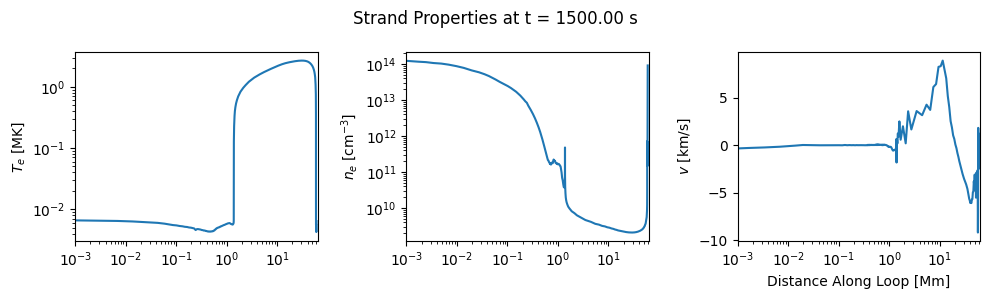

In [249]:
# Plot quantities at a specific time
# time_index = 170  # Choose the time index you want to inspect

# Get the data at this specific time
time_value = a.time[time_index]
print(f"Plotting at time index {time_index}, t = {time_value}")
# Extract quantities at this time
electron_temp = a[time_index].electron_temperature
electron_dens = a[time_index].electron_density
velocity = a[time_index].velocity
coordinate = a[time_index].coordinate

# Create figure with subplots
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharex=True)

# Plot electron temperature
axes[0].plot(coordinate.to(u.Mm), electron_temp.to(u.MK))
axes[0].set_ylabel(r'$T_e$ [MK]')
axes[0].set_yscale('log')
axes[0].set_xlim(left=1e-3)
# axes[0].grid(True, alpha=0.3)

# Plot electron density
axes[1].plot(coordinate.to(u.Mm), electron_dens.to(u.cm**-3))
axes[1].set_ylabel(r'$n_e$ [cm$^{-3}$]')
axes[1].set_yscale('log')
axes[1].set_xlim(left=1e-3)
# axes[1].grid(True, alpha=0.3)

# Plot velocity
axes[2].plot(coordinate.to(u.Mm), velocity.to(u.km/u.s))
axes[2].set_ylabel(r'$v$ [km/s]')
axes[2].set_xlabel('Distance Along Loop [Mm]')
axes[2].set_xlim(left=1e-3)
# axes[2].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xscale('log')
plt.suptitle(f'Strand Properties at t = {time_value:.2f}')
plt.tight_layout()
plt.show()


In [40]:
plot_time_distance(
    a,
    ['electron_temperature', 'electron_density', 'velocity'],
    0.5*u.Mm,
    cmap={'velocity': 'RdBu_r'},
    labels={'electron_temperature': r'$T_e$',
            'electron_density': r'$n_e$',
            'velocity': r'$v$'},
    norm={'electron_density': ImageNormalize(vmin=1e8, vmax=1e12, stretch=LogStretch())},
    time_unit='s',
    space_unit='Mm',
)


NameError: name 'plot_time_distance' is not defined

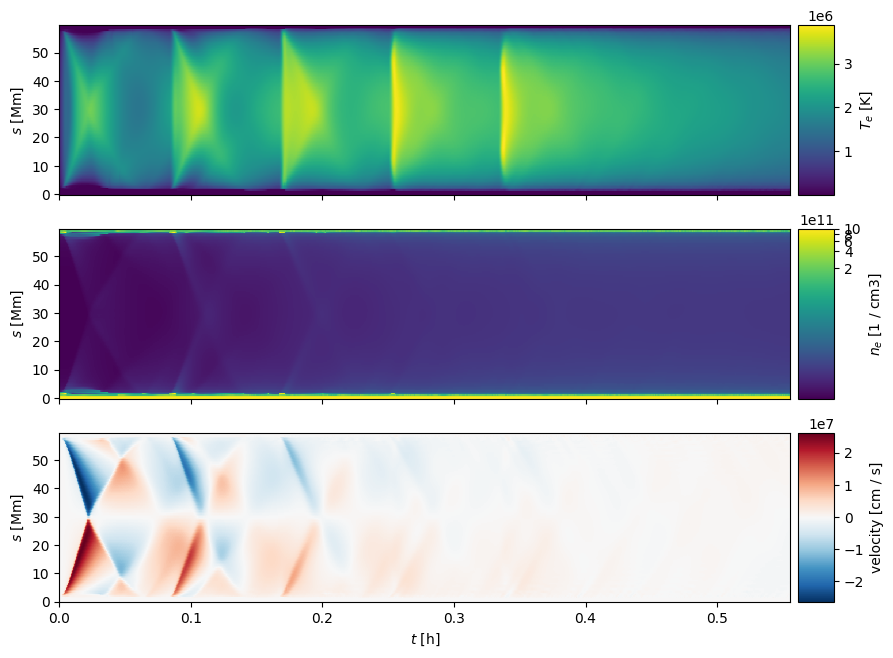

In [ ]:
a.peek_time_distance(
    ['electron_temperature', 'electron_density', 'velocity'],
    0.5*u.Mm,
    cmap={'velocity': 'RdBu_r'},
    labels={'electron_temperature':r'$T_e$',
            'electron_density': r'$n_e$'},
    norm={'electron_density': ImageNo rmalize(vmin=1e8, vmax=1e12, stretch=LogStretch())},
    time_unit='s',
    space_unit='Mm',
)


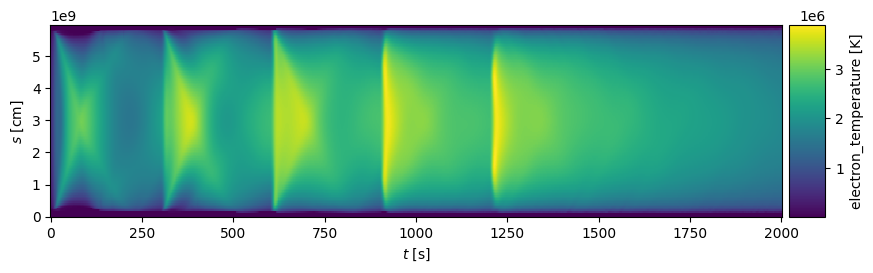

In [20]:
a.peek_time_distance('electron_temperature', 0.5*u.Mm)


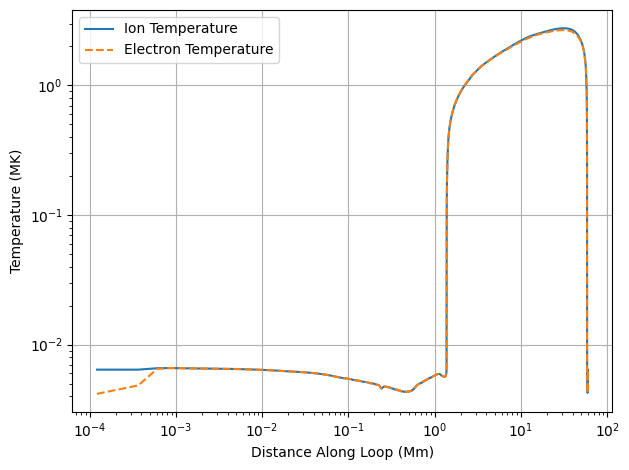

In [15]:
# Plot coordinate vs ion and electron temperatures
plt.figure()
plt.plot(hydrad_strand.coordinate.to(u.Mm), hydrad_strand.ion_temperature.to(u.MK), label='Ion Temperature')
plt.plot(hydrad_strand.coordinate.to(u.Mm), hydrad_strand.electron_temperature.to(u.MK), '--', label='Electron Temperature')
plt.xlabel('Distance Along Loop (Mm)')
plt.xscale('log')
plt.yscale('log')
plt.ylabel('Temperature (MK)')
plt.legend()
plt.grid(True)
plt.tight_layout()


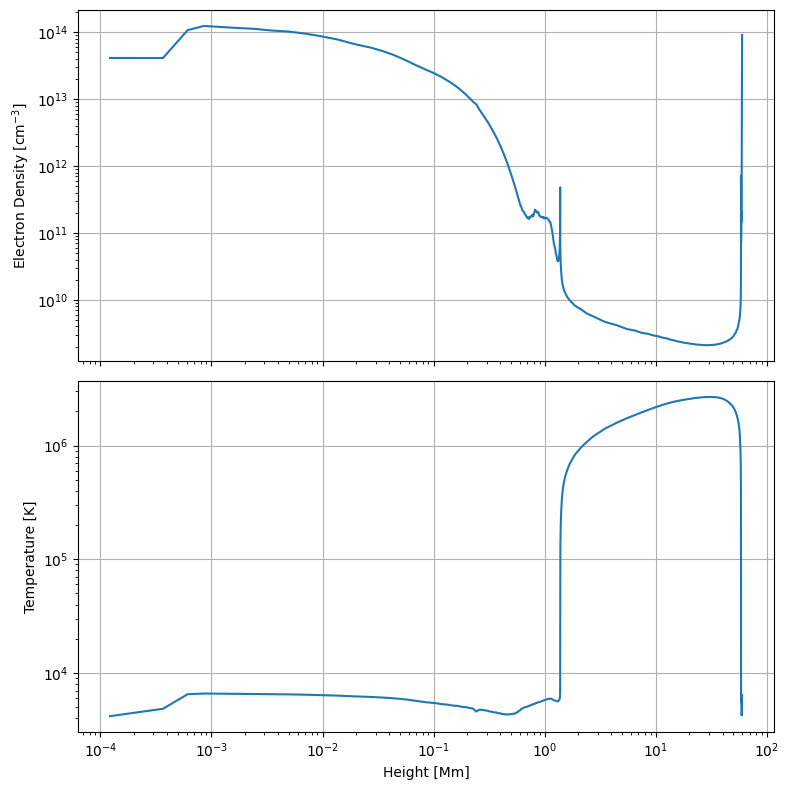

In [16]:
# Plot density and temperature vs height
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# Plot density
ax1.plot(hydrad_strand.coordinate.to(u.Mm), hydrad_strand.electron_density.to(u.cm**-3))
ax1.set_ylabel('Electron Density [cm$^{-3}$]')
ax1.set_yscale('log')
ax1.grid(True)

# Plot temperature 
ax2.plot(hydrad_strand.coordinate.to(u.Mm), hydrad_strand.electron_temperature.to(u.K))
ax2.set_xlabel('Height [Mm]')
ax2.set_ylabel('Temperature [K]')
ax2.set_yscale('log')
ax2.grid(True)

ax1.set_xscale('log')
ax2.set_xscale('log')
plt.tight_layout()


In [38]:
1-saha_fraction

array([1.25726077e-08, 8.93616792e-09, 4.83125673e-09, 4.65216310e-09,
       4.65336480e-09, 4.65325090e-09, 4.63316474e-09, 4.63557970e-09,
       4.64010852e-09, 4.65065697e-09, 4.70359351e-09, 4.71508543e-09,
       4.81231477e-09, 4.90094565e-09, 5.10233233e-09, 5.25055910e-09,
       5.67340330e-09, 5.99378680e-09, 7.10998083e-09, 8.79534900e-09,
       1.16894862e-08, 1.20911782e-08, 1.53357627e-08, 1.54089430e-08,
       1.86370294e-08, 1.75340934e-08, 2.16594112e-08, 2.01304236e-08,
       2.54998680e-08, 2.78561808e-08, 2.77888840e-08, 2.46803554e-08,
       2.87681911e-08, 2.56655919e-08, 2.95715106e-08, 2.84972025e-08,
       3.32460273e-08, 3.10403901e-08, 3.33236327e-08, 3.23267003e-08,
       3.56860611e-08, 3.40374899e-08, 3.69550179e-08, 3.07077459e-08,
       2.96031262e-08, 2.51846919e-08, 2.28591494e-08, 1.95501600e-08,
       1.51542963e-08, 1.10053849e-08, 7.06067449e-09, 4.79411422e-09,
       2.75731349e-09, 1.89208427e-09, 1.01518904e-09, 7.01596115e-10,
      

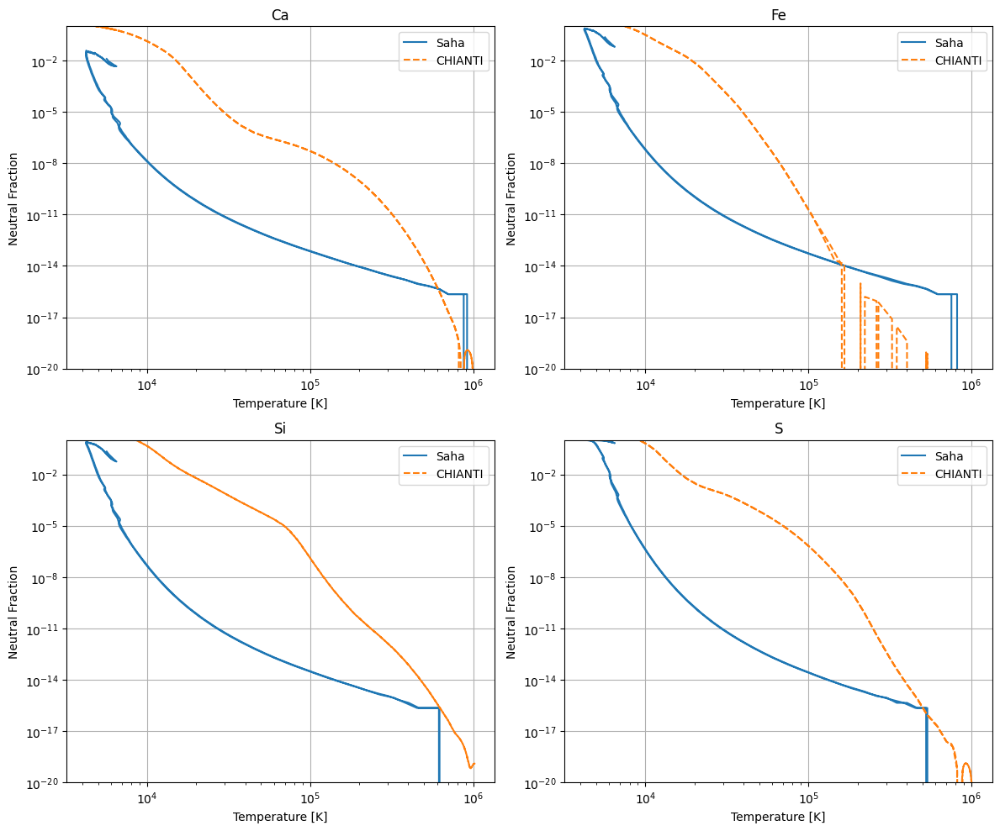

In [59]:
from scipy.interpolate import interp1d

# Initialize CHIANTI data for each element
ca = ch.ioneq(20)  # Ca
ca.load()
fe = ch.ioneq(26)  # Fe
fe.load()
si = ch.ioneq(14)  # Si
si.load()
s = ch.ioneq(16)   # S
s.load()

# Create temperature arrays
T_saha = hydrad_strand.electron_temperature.to(u.K).value
T_chianti = T_saha  # Use same temperature array for both

# Elements to plot
elements = ['Ca', 'Fe', 'Si', 'S']

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, element in enumerate(elements):
    # Get CHIANTI data
    if element == 'Ca':
        temperatures = ca.Temperature
        first_stage_fraction = ca.Ioneq[0]
    elif element == 'Fe':
        temperatures = fe.Temperature
        first_stage_fraction = fe.Ioneq[0]
    elif element == 'Si':
        temperatures = si.Temperature
        first_stage_fraction = si.Ioneq[0]
    elif element == 'S':
        temperatures = s.Temperature
        first_stage_fraction = s.Ioneq[0]
        
    first_stage_fraction_interp = interp1d(temperatures, first_stage_fraction, 
                                         kind='cubic', fill_value='extrapolate')(T_saha)

    # Calculate Saha equation ionization fraction
    n_e = hydrad_strand.electron_density.to(u.cm**-3).value
    saha_fraction = get_ionisation_fraction(
        atomic_data[element]['g_i'],
        atomic_data[element]['g_j'], 
        n_e*u.cm**-3,
        atomic_data[element]['ionization_energy'],
        T_saha*u.K
    )

    # Plot on corresponding subplot
    axes[i].plot(T_saha, 1-saha_fraction, label='Saha')
    axes[i].plot(T_saha, first_stage_fraction_interp, '--', label='CHIANTI')
    axes[i].set_xlabel('Temperature [K]')
    axes[i].set_ylabel('Neutral Fraction')
    axes[i].set_xscale('log')
    axes[i].set_yscale('log')
    axes[i].set_ylim(1e-20, 1)
    axes[i].legend()
    axes[i].grid(True)
    axes[i].set_title(f'{element}')

plt.tight_layout()

In [113]:
def save_chianti_data(elements, filename='chianti_data.npz'):
    """
    Calculate and save CHIANTI ionization equilibrium data for multiple elements.
    
    Parameters:
    -----------
    elements : list
        List of element symbols
    filename : str
        Output filename for NPZ file
    """
    chianti_data = {}
    
    for element in elements:
        atomic_num = ChiantiPy.tools.util.el2z(element)
        ion = ch.ioneq(atomic_num)
        ion.load()
        
        
        chianti_data[f'{element}_ioneq'] = 1-ion.Ioneq[0]  # Just ionised state
    chianti_data[f'temperature'] = ion.Temperature
    np.savez(filename, **chianti_data)

In [114]:
elements = ['Ca', 'Mg', 'Fe', 'Si', 'S', 'C', 'O', 'N', 'Ar', 'Ne']
save_chianti_data(elements)


In [115]:
chianti_data = np.load('chianti_data.npz')


In [118]:
print(len(chianti_data['temperature']))
print(len(chianti_data['Ca_ioneq']))


101
101


In [122]:
T_connect = 1e4
connect_idx = np.argmin(np.abs(T_saha - T_connect))

# Initialize array
ion_fraction = np.zeros_like(T_saha)

# Use Saha equation for T < T_connect
mask_saha = T_saha < T_connect
ion_fraction[mask_saha] = saha_fraction[mask_saha]

# Use CHIANTI for T >= T_connect 
# Add a smooth transition region around T_connect
transition_width = 0.05 * T_connect  # 10% width for transition
mask_chianti = T_saha >= T_connect
mask_transition = (T_saha >= (T_connect - transition_width)) & (T_saha < T_connect)

# Create weights for smooth interpolation in transition region
weights = 0.5*(T_saha[mask_transition] - (T_connect - transition_width)) / transition_width
# ion_fraction[mask_transition] = (saha_fraction[mask_transition]) * (1 - weights) + \
#                                (saha_fraction[mask_transition]) * weights
# ion_fraction[mask_chianti] = saha_fraction[mask_chianti]
ion_fraction[mask_transition] = (saha_fraction[mask_transition]) * (1 - weights) + \
                               (1-first_stage_fraction_interp[mask_transition]) * weights
ion_fraction[mask_chianti] = 1-first_stage_fraction_interp[mask_chianti]

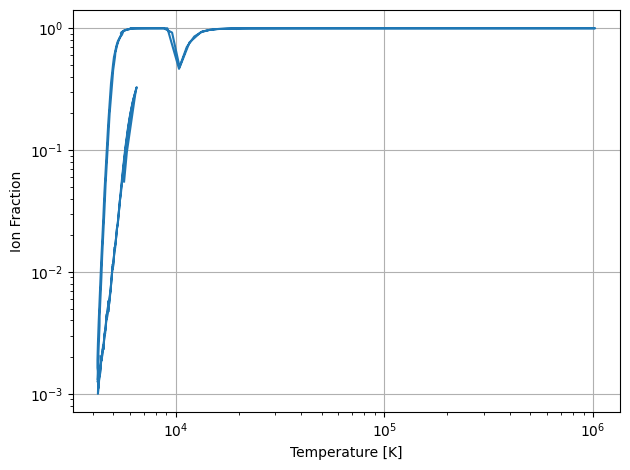

In [123]:
plt.figure()
plt.plot(T_saha, ion_fraction)
plt.xlabel('Temperature [K]')
plt.ylabel('Ion Fraction')
plt.xscale('log')
plt.yscale('log')
plt.grid(True)
plt.tight_layout()


In [124]:
# Use a sigmoid function for smooth transition
def sigmoid_weight(x, x0, width):
    return 1 / (1 + np.exp(-(x - x0) / (width/4)))

T_connect = 1e4
# Increase transition width for smoother blend
transition_width = 0.2 * T_connect  # 20% width for transition

# Initialize array
ion_fraction = np.zeros_like(T_saha)

# Calculate weights using sigmoid function
weights = sigmoid_weight(T_saha, T_connect, transition_width)

# Combine both solutions using smooth weights
ion_fraction = (saha_fraction * (1 - weights) + 
               (1-first_stage_fraction_interp) * weights)


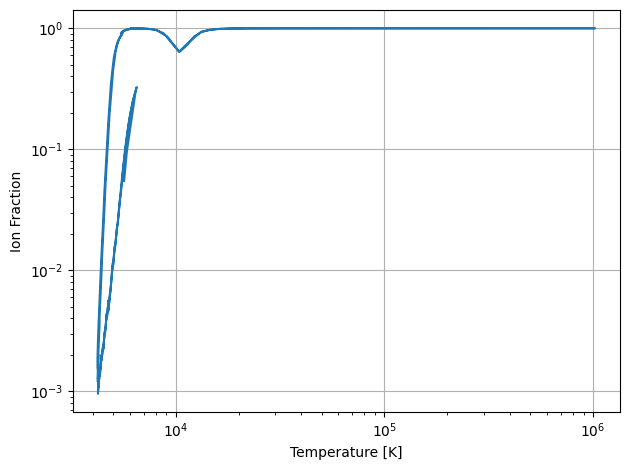

In [125]:
plt.figure()
plt.plot(T_saha, ion_fraction)
plt.xlabel('Temperature [K]')
plt.ylabel('Ion Fraction')
plt.xscale('log')
plt.yscale('log')
plt.grid(True)
plt.tight_layout()


In [60]:
def connect_saha_chianti(saha_fraction, chianti_fraction, T, T_connect=1e4):
    """
    Connect Saha equation results to CHIANTI results at a specified temperature.
    
    Parameters:
    -----------
    saha_fraction : array-like
        Ionization fractions calculated using Saha equation
    chianti_fraction : array-like 
        Ionization fractions from CHIANTI database
    T : array-like
        Temperature array in Kelvin
    T_connect : float
        Temperature at which to connect the two solutions (default: 1e4 K)
        
    Returns:
    --------
    array-like
        Combined ionization fractions
    """
    # Find index closest to connection temperature
    connect_idx = np.abs(T - T_connect).argmin()
    
    # Create combined solution
    combined = np.copy(1- saha_fraction)
    combined[connect_idx:] = chianti_fraction[connect_idx:]  # Use CHIANTI above connection temp
    
    return combined


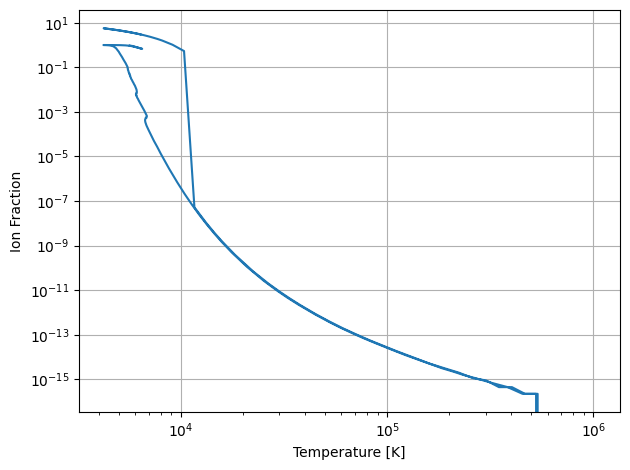

In [61]:
connected_fraction = connect_saha_chianti(saha_fraction, first_stage_fraction_interp, T_saha)

plt.figure()
plt.plot(T_saha, connected_fraction)
plt.xlabel('Temperature [K]')
plt.ylabel('Ion Fraction')
plt.xscale('log')
plt.yscale('log')
plt.grid(True)
plt.tight_layout()

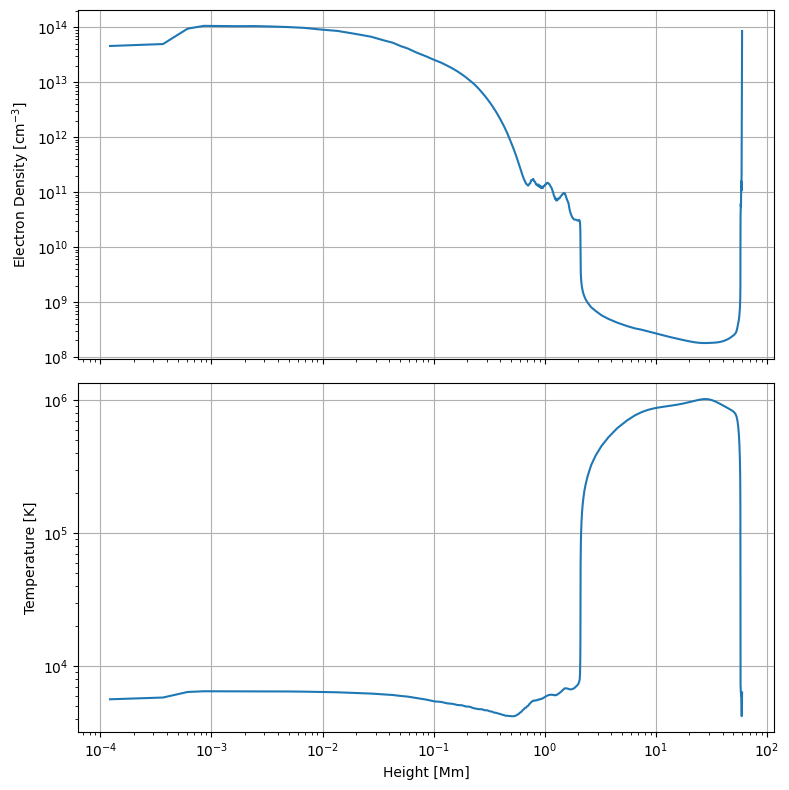

In [44]:
# Plot density and temperature vs height
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

# Plot density
ax1.plot(hydrad_strand.coordinate.to(u.Mm), hydrad_strand.electron_density.to(u.cm**-3))
ax1.set_ylabel('Electron Density [cm$^{-3}$]')
ax1.set_yscale('log')
ax1.grid(True)

# Plot temperature 
ax2.plot(hydrad_strand.coordinate.to(u.Mm), hydrad_strand.electron_temperature.to(u.K))
ax2.set_xlabel('Height [Mm]')
ax2.set_ylabel('Temperature [K]')
ax2.set_yscale('log')
ax2.grid(True)

ax1.set_xscale('log')
ax2.set_xscale('log')
plt.tight_layout()


In [36]:
T_saha

array([   5650.62361,    5825.59761,    6413.28096,    6492.97171,
          6489.28551,    6485.60299,    6490.04415,    6481.50756,
          6468.55769,    6449.62213,    6406.67101,    6376.73509,
          6306.57627,    6238.25454,    6149.11619,    6085.94676,
          5985.09353,    5917.3854 ,    5771.19018,    5619.03453,
          5451.47093,    5396.44407,    5265.59924,    5222.29793,
          5117.2301 ,    5096.28765,    4988.36936,    4971.78868,
          4861.66584,    4797.79171,    4759.45306,    4753.99262,
          4672.32397,    4666.75539,    4590.06374,    4563.38061,
          4486.12778,    4467.34281,    4412.75682,    4384.65568,
          4324.42641,    4301.47701,    4246.14502,    4254.33312,
          4225.33368,    4226.62739,    4211.71949,    4212.33495,
          4233.65616,    4271.18275,    4337.55856,    4392.22881,
          4490.62551,    4547.30249,    4674.96804,    4741.75258,
          4857.38528,    4890.6345 ,    5000.61143,    5051.88

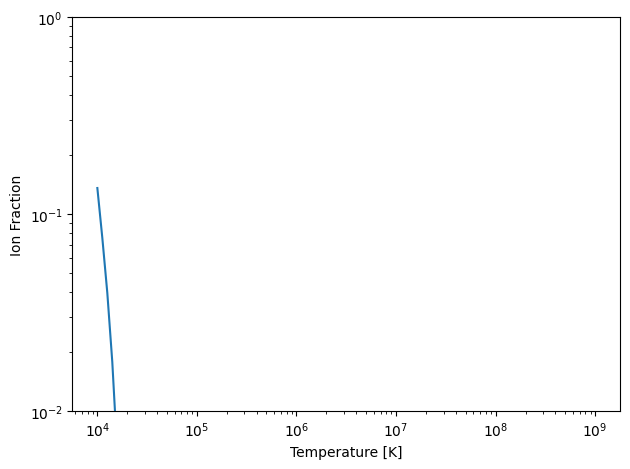

In [36]:
plt.figure()
plt.plot(data_array[:,0], data_array[:,1])
plt.xlabel('Temperature [K]')
plt.ylabel('Ion Fraction') 
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-2,1)
plt.tight_layout()

In [39]:
from plasmapy.formulary.ionization import Saha
import numpy as np
import astropy.units as u
atomic_data = {
    # 'H': {'ionization_energy': 13.6, 'g_i': 2, 'g_j': 1},
    # 'He': {'ionization_energy': 24.6, 'g_i': 1, 'g_j': 2},
    'Ca': {'ionization_energy': 6.1132*u.eV, 'g_i': 1, 'g_j': 2},
    'Mg': {'ionization_energy': 7.6462*u.eV, 'g_i': 1, 'g_j': 2},
    'Fe': {'ionization_energy': 7.9024*u.eV, 'g_i': 25, 'g_j': 30},
    'Si': {'ionization_energy': 8.1517*u.eV, 'g_i': 9, 'g_j': 6},
    'S': {'ionization_energy': 10.3600*u.eV, 'g_i': 9, 'g_j': 4},
    'C': {'ionization_energy': 11.2603*u.eV, 'g_i': 9, 'g_j': 6},
    'O': {'ionization_energy': 13.6181*u.eV, 'g_i': 9, 'g_j': 4}, 
    'N':  {'ionization_energy': 14.5341*u.eV, 'g_i': 4, 'g_j': 9},
    'Ar': {'ionization_energy': 15.7568*u.eV, 'g_i': 1, 'g_j': 6},
    'Ne': {'ionization_energy': 21.5645*u.eV, 'g_i': 1, 'g_j': 6},

}

def get_ionisation_fraction(g_i, g_j, n_e, ionization_energy, T):
    """
    Calculate the ionization fraction using the Saha equation.
    
    Parameters:
    T: Temperature in Kelvin
    n_e: Electron number density in cm^-3
    ionization_energy: Ionization energy in eV
    g_i: Statistical weight of the lower ionization state
    g_j: Statistical weight of the higher ionization state
    
    Returns:
    Ionization fraction n_j / n_i
    """
    fraction = Saha(g_i, g_j, n_e, ionization_energy, T)
    ionisation_fraction = 1 / (1 + 1 / np.array(fraction))
    
    return ionisation_fraction


In [43]:
element = 'Ca'
get_ionisation_fraction(atomic_data[element]['g_i'], atomic_data[element]['g_j'], 1e10, atomic_data[element]['ionization_energy'], temperatures*u.K)


array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [18]:
import ChiantiPy.tools.io as io

result = io.ioneqRead(ioneqName='')


 - make a selection from these - 
     0 chianti.ioneq 
     1 arnaud_rothenflug_ext.ioneq 
     2 arnaud_raymond.ioneq 
     3 bryans_etal_06.ioneq 
     4 mazzotta_etal_9.ioneq 
     5 chianti_version6.ioneq 
     6 mazzotta_etal_ext.ioneq 
     7 shull_steenberg.ioneq 
     8 bryans_etal_09.ioneq 
     9 mazzotta_etal.ioneq 
    10 arnaud_rothenflug.ioneq 
    11 shull_steenberg_ext.ioneq 
    12 arnaud_raymond_ext.ioneq 
 type the index of your selection and hit return


In [20]:
result['ioneqTemperature']

array([1.00000000e+04, 1.12201845e+04, 1.25892541e+04, 1.41253754e+04,
       1.58489319e+04, 1.77827941e+04, 1.99526231e+04, 2.23872114e+04,
       2.51188643e+04, 2.81838293e+04, 3.16227766e+04, 3.54813389e+04,
       3.98107171e+04, 4.46683592e+04, 5.01187234e+04, 5.62341325e+04,
       6.30957344e+04, 7.07945784e+04, 7.94328235e+04, 8.91250938e+04,
       1.00000000e+05, 1.12201845e+05, 1.25892541e+05, 1.41253754e+05,
       1.58489319e+05, 1.77827941e+05, 1.99526231e+05, 2.23872114e+05,
       2.51188643e+05, 2.81838293e+05, 3.16227766e+05, 3.54813389e+05,
       3.98107171e+05, 4.46683592e+05, 5.01187234e+05, 5.62341325e+05,
       6.30957344e+05, 7.07945784e+05, 7.94328235e+05, 8.91250938e+05,
       1.00000000e+06, 1.12201845e+06, 1.25892541e+06, 1.41253754e+06,
       1.58489319e+06, 1.77827941e+06, 1.99526231e+06, 2.23872114e+06,
       2.51188643e+06, 2.81838293e+06, 3.16227766e+06, 3.54813389e+06,
       3.98107171e+06, 4.46683592e+06, 5.01187234e+06, 5.62341325e+06,
      

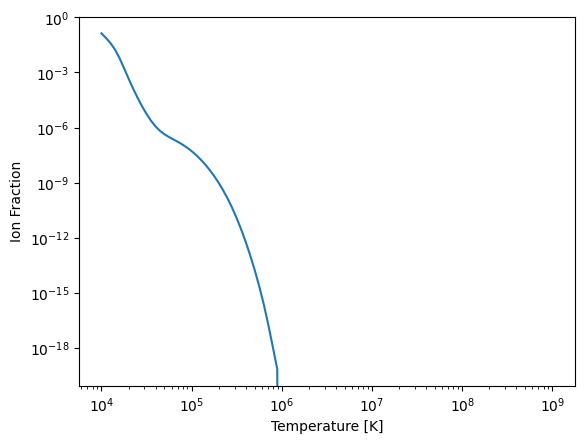

In [27]:
plt.figure()
plt.plot(result['ioneqTemperature'], result['ioneqAll'][20-1, 0])
plt.xlabel('Temperature [K]')
plt.ylabel('Ion Fraction')
plt.xscale('log')
plt.yscale('log')

In [12]:
help(ca)

Help on ioneq in module ChiantiPy.core.Ioneq object:

class ioneq(builtins.object)
 |  ioneq(el_or_z)
 |  
 |  Calculation ion fractions as a function of temperature assuming
 |  ionization equilibrium.
 |  
 |  Parameters
 |  ----------
 |  el_or_z : `int` or `str`
 |      Atomic number or symbol
 |  
 |  Note
 |  ----
 |  When either loading or calculating a set of ion fractions, the temperature and
 |  ion fractions are returned to the `Temperature` and `Ioneq` attributes, respectively.
 |  
 |  Methods defined here:
 |  
 |  __init__(self, el_or_z)
 |      Initialize self.  See help(type(self)) for accurate signature.
 |  
 |  calculate(self, temperature)
 |      Calculate ion fractions for given temperature array using the total
 |      ionization and recombination rates.
 |  
 |  load(self, ioneqName=None)
 |      Read temperature and ion fractions from a CHIANTI ".ioneq" file.
 |  
 |  plot(self, stages=0, tRange=0, yr=0, oplot=False, label=1, title=1, bw=False, semilogx=0, heig